# Shopping-Mall Evacuation: How Exit Width Must Scale with Crowd Size

This notebook simulates the evacuation of a simplified single-floor shopping mall (about 40 m × 30 m, with rectangular shop blocks and two exits) using the **Social Force Model**. Each shopper is an agent with its own desired walking speed. A driving force pushes them towards the nearest exit, and repulsive and contact forces from other people, walls and shop blocks push them away. Pedestrians follow a precomputed shortest-distance map, so they route around the shops. Their equations of motion are integrated with **Velocity-Verlet**, and **cell lists** find nearby pedestrians efficiently. Every scenario is repeated over many random seeds and reported with **95 % confidence intervals**. Sweeping exit width at crowd sizes from 100 to 800 people (the proposed 100–400, extended after a pilot run) gives the minimum width that clears the floor within a 3-minute target, and shows whether that width must grow faster than occupancy.

**Key result:** up to about 400 occupants, each exit must be about 1.05–1.10 m wide. That minimum is set by whether everyone can get through the door at all, not by the 3-minute target. From 500 to 800 occupants the target decides, and the required width rises from 1.15 m to 1.44 m per exit. In that range $w^* \propto N^{\alpha}$ with $\alpha = 0.46$ (95 % CI 0.45–0.48): exit width grows roughly like $\sqrt{N}$, **more slowly than occupancy, not faster**. Because the model over-rewards wider doors, this $\alpha$ is a lower bound (Section 5.5).

**Verification:** a single pedestrian's speed is checked against the analytic relaxation curve $v(t)=v_0\left(1-e^{-t/\tau}\right)$. The notebook also checks that people are conserved at every step, that results converge as the time step shrinks while a too-large step goes unstable, and that exit flow is plausible against published bottleneck measurements (Section 4).

**How to run:** *Runtime → Run all* on a fresh Google Colab runtime, or *Run All* in a local Jupyter install. Missing packages are installed automatically in the first code cell. All random seeds are fixed and stated.

In [29]:
!pip install --upgrade pip

In [30]:
# Setup: install anything missing, then import.
# Works unchanged on a fresh Google Colab runtime and in a local Jupyter install.
import importlib.util, subprocess, sys

REQUIRED = ["numpy", "scipy", "matplotlib", "pandas", "numba"]
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import platform, time
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numba
from numba import njit

# Reproducibility: every random draw in this notebook comes from a seeded generator.
SEED = 42
rng = np.random.default_rng(SEED)

# Run mode: QUICK_MODE = True loads the large parameter sweeps (main sweep, blocked exit, sensitivity)
# from the cached CSV files in data/ and re-simulates a few runs as a check, so "Run all" stays under
# ~10 minutes. Set it to False to regenerate those sweeps from scratch with 20 seeds per case (about
# 35 minutes on 10 cores).
QUICK_MODE = True

# Figures are saved to the repository's figures/ folder (or ./figures on Colab).
from pathlib import Path
FIG_DIR = Path("../figures") if Path("../figures").is_dir() else Path("figures")
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("../data") if Path("../data").is_dir() else Path("data")   # cached sweep results
DATA_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | numba {numba.__version__}")
print(f"SEED = {SEED} | QUICK_MODE = {QUICK_MODE}")

Python 3.13.18 | numpy 2.4.6 | scipy 1.16.3 | pandas 2.2.3 | matplotlib 3.10.0 | numba 0.64.0
SEED = 42 | QUICK_MODE = True


## 1. Problem and question

Large shopping malls in Colombo hold hundreds of shoppers on one open floor. In an emergency, everyone converges on a few exits at once, and the exits become bottlenecks: the floor can only empty as fast as people can pass through the doorways. If the exits are too narrow for the number of people inside, queues and crushing build up in front of them and evacuation takes much longer than the walking distance alone suggests.

**Question:** *How wide must the exits be to clear the floor within a target time of 3 minutes (180 s) as the number of occupants rises from 100 to 400?* The pilot run (Section 5.2) shows that, over this range, the exits are limited mainly by whether people can pass at all. The study therefore extends to 800 occupants to cover the regime where exit capacity decides the width.

| Quantity | Symbol | Values studied |
|---|---|---|
| Number of occupants | $N$ | 100, 200, 300, 400 people as proposed; 500, 600, 700 and 800 added after the pilot run (Section 5.2) |
| Width of each of the two exits | $w$ | six widths per $N$ between 0.85 and 1.6 m, placed around the 180 s crossing by a pilot run (Section 5.2) |
| Evacuation time (last person out) | $T_\text{evac}$ | output, s, mean ± 95 % CI over seeds |
| Target evacuation time | $T_\text{target}$ | 180 s (assumed) |
| Required exit width | $w^*(N)$ | smallest $w$ with $T_\text{evac} \le T_\text{target}$ |

To see how the required width scales with occupancy, a power law $w^*(N) \propto N^{\alpha}$ is fitted. If $\alpha > 1$, exit width must grow **faster** than occupancy: doubling the number of people needs more than double the exit width. If $\alpha \approx 1$, width grows in proportion; if $\alpha < 1$, it grows more slowly.

**Why it matters:** exit width and the maximum safe occupancy are linked design decisions. Knowing how $w^*$ scales with $N$ shows whether an existing floor can safely hold more people, and how much wider the exits would need to be.

**Scope:** one floor with synthetic geometry. Model parameters come from the published Social Force Model literature. Everyone starts moving at $t = 0$ (no pre-movement delay). As a stretch scenario, one exit is blocked at the start of the emergency, and the increase in evacuation time and the peak crowd density at the remaining exit are measured.

## 2. Model, assumptions and equations

Full derivations and justifications are in `THEORY.md`. Reference numbers [n] refer to Section 7.

### 2.1 Geometry

The mall floor is the region $\Omega = [0, 40] \times [0, 30]$ m. It is bounded by walls and contains several rectangular shop blocks that people cannot walk through. There are **two exits of equal width $w$**, in the middle of the west wall and the middle of the east wall. A person counts as evacuated, and is removed, once they are 0.5 m outside an exit line.

### 2.2 Assumptions

1. **2D single floor; people are discs** of radius $r_i$, the standard Social Force Model representation [1], [2].
2. **Synthetic geometry** representing a medium-sized mall floor, since no real floor plan or evacuation data are available.
3. **No pre-movement time:** everyone starts moving at $t = 0$, so $T_\text{evac}$ is a movement time and the required widths are a lower bound.
4. **Nearest-exit routing:** each person follows the shortest walking route to the nearest exit and does not re-route to a less crowded exit. The layout is symmetric, so the two exits are loaded roughly equally.
5. **Homogeneous adults, normal (non-panic) walking.** Parameters come from [1], [2] and are assumed to transfer to local crowds.
6. **Target time** $T_\text{target} = 180$ s is assumed.

### 2.3 Equations of motion (Social Force Model)

For each pedestrian $i$ with position $\mathbf{x}_i$ (m), velocity $\mathbf{v}_i$ (m s⁻¹), mass $m_i$ (kg) and radius $r_i$ (m):

$$
\frac{d\mathbf{x}_i}{dt} = \mathbf{v}_i, \qquad
m_i \frac{d\mathbf{v}_i}{dt}
= m_i\,\frac{v_i^0\,\mathbf{e}_i^0(\mathbf{x}_i) - \mathbf{v}_i}{\tau}
+ \sum_{j \ne i} \mathbf{f}_{ij}
+ \sum_{W} \mathbf{f}_{iW}
$$

The first term is the **driving force**: each person relaxes towards their desired velocity over time $\tau$. The **pedestrian–pedestrian force** combines soft repulsion, body compression and sliding friction [2]:

$$
\mathbf{f}_{ij} = \Big[ A\, e^{(r_{ij} - d_{ij})/B} + k\, g(r_{ij} - d_{ij}) \Big]\,\mathbf{n}_{ij}
+ \kappa\, g(r_{ij} - d_{ij})\, \Delta v_{ji}^{t}\, \mathbf{t}_{ij}
$$

Here $d_{ij} = \lVert \mathbf{x}_i - \mathbf{x}_j \rVert$, $r_{ij} = r_i + r_j$, $\mathbf{n}_{ij} = (\mathbf{x}_i - \mathbf{x}_j)/d_{ij}$, $\mathbf{t}_{ij} = (-n_{ij,2}, n_{ij,1})$, $\Delta v^t_{ji} = (\mathbf{v}_j - \mathbf{v}_i)\cdot\mathbf{t}_{ij}$, and $g(x) = \max(x, 0)$. The $k$ and $\kappa$ terms therefore act only when the bodies overlap.

The **pedestrian–wall force** uses the closest point on each obstacle $W$: every outer wall segment, and every shop block taken as one rectangle (so a shop corner is not counted twice). The closest point is at distance $d_{iW}$, with normal $\mathbf{n}_{iW}$ and tangent $\mathbf{t}_{iW}$ [2]:

$$
\mathbf{f}_{iW} = \Big[ A\, e^{(r_i - d_{iW})/B} + k\, g(r_i - d_{iW}) \Big]\,\mathbf{n}_{iW}
- \kappa\, g(r_i - d_{iW})\, (\mathbf{v}_i \cdot \mathbf{t}_{iW})\, \mathbf{t}_{iW}
$$

Speeds are capped at $v_\text{max} = 1.3\,v_i^0$ [1].

### 2.4 Desired direction from a shortest-distance map

$D(\mathbf{x})$ is the shortest walking distance from $\mathbf{x}$ to the nearest exit. It approximately solves $\lVert \nabla D \rVert = 1$ with $D = 0$ at the exits and obstacles impassable. It is computed with the fast marching method [10] on a grid with spacing $h = 0.1$ m: nodes are accepted in order of increasing $D$, as in Dijkstra's algorithm [6], but each value comes from an upwind finite-difference solution of the eikonal equation, so routes are not bent towards the grid directions. Shop blocks are impassable. A band of width 0.35 m (the largest body radius) along every wall and shop edge costs 5 times as much to cross, so routes keep a body radius away from walls; because the band is passable, it cannot close even a narrow exit. The desired direction is

$$
\mathbf{e}_i^0 = -\frac{\nabla D(\mathbf{x}_i)}{\lVert \nabla D(\mathbf{x}_i) \rVert},
$$

so people route around shop blocks instead of walking into them.

### 2.5 Input model (random variates)

| Input | Distribution | Method | Source |
|---|---|---|---|
| Desired speed $v_i^0$ | $\mathcal{N}(1.34, 0.26^2)$ m/s, truncated to [0.56, 2.12] m/s (mean ± 3 s.d.) | rejection sampling | [1] |
| Body radius $r_i$ | $\mathcal{U}(0.25, 0.35)$ m | inverse transform | [2] |
| Start position | uniform on the free floor, no overlaps | random sequential placement with rejection | assumed |
| Start velocity | $\mathbf{0}$ | — | assumed |

### 2.6 Parameters

| Symbol | Meaning | Units | Value | Source |
|---|---|---|---|---|
| $m_i$ | mass | kg | 80 | [2] |
| $\tau$ | relaxation time | s | 0.5 | [2] |
| $A$ | repulsion strength | N | $2 \times 10^3$ | [2] |
| $B$ | repulsion range | m | 0.08 | [2] |
| $k$ | body-compression coefficient | kg s⁻² | $1.2 \times 10^5$ | [2] |
| $\kappa$ | sliding-friction coefficient | kg m⁻¹ s⁻¹ | $2.4 \times 10^5$ | [2] |
| $r_c$ | interaction cut-off, $2r_\text{max} + B\ln(A/1\,\text{N})$ | m | 1.3 | derived |
| $\Delta t$ | time step | s | 0.005 for $N \le 400$, 0.0025 for $N > 400$ (checked in V4, V5; Section 5.3) | derived |
| $T_\text{max}$ | simulation time limit | s | 600 (360 in the main sweep, Section 5.3) | assumed |
| $T_\text{target}$ | evacuation target | s | 180 | assumed |

### 2.7 Numerical method: Velocity-Verlet with a velocity predictor

$$
\begin{aligned}
\mathbf{x}_{n+1} &= \mathbf{x}_n + \mathbf{v}_n\,\Delta t + \tfrac12\,\mathbf{a}_n\,\Delta t^2 \\
\tilde{\mathbf{v}} &= \mathbf{v}_n + \mathbf{a}_n\,\Delta t \\
\mathbf{a}_{n+1} &= \mathbf{F}(\mathbf{x}_{n+1}, \tilde{\mathbf{v}}) / m \\
\mathbf{v}_{n+1} &= \mathbf{v}_n + \tfrac12\left(\mathbf{a}_n + \mathbf{a}_{n+1}\right)\Delta t
\end{aligned}
$$

The driving and friction forces depend on velocity, so plain Velocity-Verlet [3], [4] would be implicit. The Euler predictor $\tilde{\mathbf{v}}$ keeps the scheme explicit while staying **second-order accurate** (it is close to Heun's method, but $\mathbf{a}_{n+1}$ is reused as the next step's $\mathbf{a}_n$, so each step needs only one force evaluation; its error analysis is in Section 4). For one person in open space the model reduces to $\dot v = (v_0 - v)/\tau$, with exact solution $v(t) = v_0\left(1 - e^{-t/\tau}\right)$. This is the analytic check V1 in Section 4.

**Stability.** The step must resolve the fastest time scales (derivation and checks in V5). For this scheme the stability limits are $\omega\,\Delta t \le 2$ for an undamped oscillation and $\gamma\,\Delta t \le 1$ for a damping rate $\gamma$. That is half of Heun's limit, because $\mathbf{a}_{n+1}$ is reused. Two overlapping people oscillate at $\omega = \sqrt{2(k + A/B)/m} \approx 60$ rad s⁻¹, so $\Delta t < 0.033$ s. Sliding friction damps their relative sliding at $\gamma = 2\kappa s/m$ for an overlap $s$, so $\Delta t < m/(2\kappa s)$, a limit that **tightens as people are squeezed together**. In dense jams 99 % of overlaps are below about 1.8 cm and the deepest reach about 3 cm (V5), which needs $\Delta t \lesssim 0.006$–$0.009$ s. The production step is $\Delta t = 0.005$ s, halved to 0.0025 s for crowds of more than 400 people, which push harder (Section 5.3).

**Neighbour search.** Forces are truncated at $r_c \approx 1.3$ m, where the repulsion is below 1 N (< 0.5 % of the driving force). Neighbours are found with **cell lists** of side $\ge r_c$ [5] (32 × 23 cells of 1.31 × 1.30 m), which reduces the cost per step from $O(N^2)$ to $O(N)$.

### 2.8 Outputs and statistics

For each run: the evacuation time $T_\text{evac}$ (last person out), $T_{90}$ (90 % out), the cumulative count $N_\text{out}(t)$, the specific exit flow $J_s = \Delta N_\text{out}/(w\,\Delta t)$ (persons m⁻¹ s⁻¹), and the peak density in front of each exit. Each scenario $(N, w)$ is repeated with $R$ independent seeds. The results are reported as

$$
\overline{T} \pm t_{0.975,\,R-1}\,\frac{s}{\sqrt{R}}
$$

(95 % CI) [9]. The required width $w^*(N)$ is the smallest $w$ whose **upper** 95 % limit is $\le T_\text{target}$, interpolated between the simulated widths. The scaling exponent $\alpha$ is fitted from $\log w^* = \log c + \alpha \log N$.

### 2.9 Concepts used

| Concept | Where it appears |
|---|---|
| **Particle-based simulation** | pedestrians as interacting particles with pair forces; cell-list neighbour search (2.3, 2.7) |
| **Numerical ODE solvers** | Newton's equations integrated with Velocity-Verlet with a velocity predictor; stability limit and convergence order (2.7, Section 4) |
| **Input modelling and random variate generation** | truncated-normal desired speeds, uniform radii, random non-overlapping start positions (2.5) |
| **Monte Carlo and the law of large numbers** | replications over seeds and 95 % confidence intervals on every result (2.8, Section 5) |

## 3. Implementation

### 3.1 Geometry

`make_mall(exit_width, blocked_exits=())` builds the floor described in Section 2.1:

- **Floor** 40 m × 30 m, bounded by four outer walls.
- **Six shop blocks** of 8 m × 5 m in two rows of three. The corridors are 4.0 m wide between shops in x and 6.67 m wide in y, so every corridor is at least 3 m wide.
- **Two exits** of width $w$, as gaps in the west and east walls, centred at $y = 15$ m. They open onto the central corridor, so no shop stands directly in front of an exit (the nearest shop is 4 m away). This also limits $w$ to at most 6.67 m.
- The layout is **symmetric** about both mid-lines, so under nearest-exit routing (assumption 4) each exit serves about half the crowd.

Walls are stored as line segments `[x1, y1, x2, y2]` (outer walls with the exit gaps cut out, plus the four edges of each shop), because the wall force in Section 2.3 uses the closest point on each segment. An exit named in `blocked_exits` is replaced by solid wall; this is used for the blocked-exit study. Each open exit also stores its outward normal, so "0.5 m outside the exit line" is the test $(\mathbf{x} - \mathbf{c}) \cdot \mathbf{n} > 0.5$ m. The cell ends with a few `assert` checks on the layout (corridor widths, gap width equal to $w$, shops inside the floor and clear of the exits).

In [31]:
# 3.1 Geometry: floor, shop blocks and exits.
from dataclasses import dataclass

FLOOR_W, FLOOR_H = 40.0, 30.0      # floor size (m)
SHOP_W, SHOP_H = 8.0, 5.0          # shop block size (m)
SHOP_COLS, SHOP_ROWS = 3, 2        # 3 x 2 grid of shops
EXIT_Y = FLOOR_H / 2               # both exits are centred on the floor's mid-line
EXIT_X = {"west": 0.0, "east": FLOOR_W}
EXIT_NORMAL = {"west": (-1.0, 0.0), "east": (1.0, 0.0)}   # outward unit normals


@dataclass(frozen=True)
class Mall:
    """Everything the simulation needs to know about one floor layout.

    All geometry is stored as plain float arrays so it can be passed straight
    into numba-compiled force code later.
    """
    walls: np.ndarray          # (M, 4) wall segments [x1, y1, x2, y2] (outer walls + shop edges)
    shops: np.ndarray          # (S, 4) shop rectangles [xmin, ymin, xmax, ymax]
    exit_names: tuple          # names of the OPEN exits, e.g. ("west", "east")
    exit_centres: np.ndarray   # (E, 2) centre of each open exit gap
    exit_normals: np.ndarray   # (E, 2) outward unit normal of each open exit
    exit_width: float          # width w of every exit (m)
    blocked: tuple             # names of exits closed off by a wall
    size: tuple = (FLOOR_W, FLOOR_H)


def make_mall(exit_width, blocked_exits=()):
    """Build the mall floor with two exits of width `exit_width` (m).

    Exits are gaps in the west and east walls, centred at y = 15 m. An exit named
    in `blocked_exits` is closed with a wall (used for the blocked-exit study).
    """
    blocked = tuple(blocked_exits)
    unknown = set(blocked) - set(EXIT_X)
    if unknown:
        raise ValueError(f"unknown exit(s) {sorted(unknown)}; choose from {sorted(EXIT_X)}")
    if len(set(blocked)) == len(EXIT_X):
        raise ValueError("at least one exit must stay open")

    # Shop blocks: equal corridors between shops and between shops and the walls.
    gap_x = (FLOOR_W - SHOP_COLS * SHOP_W) / (SHOP_COLS + 1)   # 4.0 m
    gap_y = (FLOOR_H - SHOP_ROWS * SHOP_H) / (SHOP_ROWS + 1)   # 6.67 m
    shops = np.array([[gap_x + c * (SHOP_W + gap_x), gap_y + r * (SHOP_H + gap_y),
                       gap_x + c * (SHOP_W + gap_x) + SHOP_W, gap_y + r * (SHOP_H + gap_y) + SHOP_H]
                      for r in range(SHOP_ROWS) for c in range(SHOP_COLS)])

    # The exit must fit inside the central corridor so no shop sits across it.
    if not 0.0 < exit_width <= gap_y:
        raise ValueError(f"exit_width must be in (0, {gap_y:.2f}] m, got {exit_width}")

    y_lo, y_hi = EXIT_Y - exit_width / 2, EXIT_Y + exit_width / 2
    walls = [[0.0, 0.0, FLOOR_W, 0.0],              # south
             [0.0, FLOOR_H, FLOOR_W, FLOOR_H]]      # north
    for name, x in EXIT_X.items():                  # west and east walls
        if name in blocked:
            walls.append([x, 0.0, x, FLOOR_H])      # solid wall, no gap
        else:
            walls += [[x, 0.0, x, y_lo], [x, y_hi, x, FLOOR_H]]   # wall with a gap of width w
    for x0, y0, x1, y1 in shops:                    # four edges of each shop block
        walls += [[x0, y0, x1, y0], [x1, y0, x1, y1], [x1, y1, x0, y1], [x0, y1, x0, y0]]

    open_exits = tuple(n for n in EXIT_X if n not in blocked)
    return Mall(walls=np.array(walls, dtype=float),
                shops=shops,
                exit_names=open_exits,
                exit_centres=np.array([[EXIT_X[n], EXIT_Y] for n in open_exits]),
                exit_normals=np.array([EXIT_NORMAL[n] for n in open_exits]),
                exit_width=float(exit_width),
                blocked=blocked)


def plot_mall(mall, ax=None, title=None):
    """Draw walls, shop blocks and exits (green = open, red = blocked)."""
    from matplotlib.patches import Rectangle
    ax = ax or plt.gca()
    for x0, y0, x1, y1 in mall.shops:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="0.85", ec="none", zorder=1))
    for x1, y1, x2, y2 in mall.walls:
        ax.plot([x1, x2], [y1, y2], color="k", lw=2, solid_capstyle="butt", zorder=2)
    w = mall.exit_width
    for name, x in EXIT_X.items():
        is_open = name in mall.exit_names
        ax.plot([x, x], [EXIT_Y - w / 2, EXIT_Y + w / 2], lw=6, zorder=3,
                color="tab:green" if is_open else "tab:red", alpha=0.6 if is_open else 1.0)
        ax.annotate(f"{name}\n{'open' if is_open else 'blocked'}", (x, EXIT_Y),
                    xytext=(-8 if name == "west" else 8, 0), textcoords="offset points",
                    ha="right" if name == "west" else "left", va="center", fontsize=8)
    ax.set_xlim(-6, FLOOR_W + 6)
    ax.set_ylim(-1, FLOOR_H + 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title or f"Mall floor, exit width w = {w:g} m")
    return ax


# Sanity checks on the layout (cheap, run every time).
_m = make_mall(1.5)
_gap_x = (FLOOR_W - SHOP_COLS * SHOP_W) / (SHOP_COLS + 1)
_gap_y = (FLOOR_H - SHOP_ROWS * SHOP_H) / (SHOP_ROWS + 1)
assert min(_gap_x, _gap_y) >= 3.0, "corridors must be at least 3 m wide"
assert len(_m.walls) == 2 + 4 + 4 * len(_m.shops)                 # two gapped side walls
assert len(make_mall(1.5, blocked_exits=("east",)).walls) == len(_m.walls) - 1
_seg_len = np.hypot(_m.walls[:, 2] - _m.walls[:, 0], _m.walls[:, 3] - _m.walls[:, 1])
_outer = 2 * (FLOOR_W + FLOOR_H)
assert np.isclose(_seg_len[:6].sum(), _outer - 2 * 1.5), "each exit gap must be exactly w wide"
assert np.all((_m.shops[:, [0, 1]] > 0) & (_m.shops[:, [2, 3]] < [FLOOR_W, FLOOR_H])), "shops inside floor"
# Nothing in the first 3 m in front of either exit.
assert _m.shops[:, 0].min() >= 3.0 and _m.shops[:, 2].max() <= FLOOR_W - 3.0
print(f"Geometry OK: {len(_m.shops)} shops, {len(_m.walls)} wall segments, "
      f"corridors {_gap_x:.2f} m (x) and {_gap_y:.2f} m (y), max exit width {_gap_y:.2f} m")

Geometry OK: 6 shops, 30 wall segments, corridors 4.00 m (x) and 6.67 m (y), max exit width 6.67 m


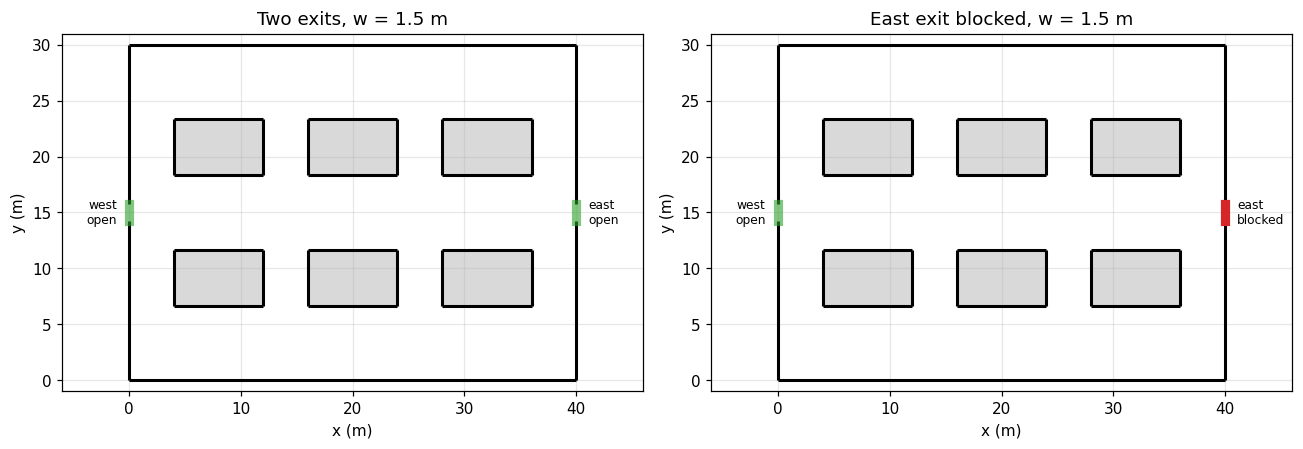

In [32]:
# Figure: the reference layout and the blocked-exit variant.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
plot_mall(make_mall(1.5), ax=axes[0], title="Two exits, w = 1.5 m")
plot_mall(make_mall(1.5, blocked_exits=("east",)), ax=axes[1], title="East exit blocked, w = 1.5 m")
fig.tight_layout()
fig.savefig(FIG_DIR / "mall_geometry.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Distance map and desired direction

`make_distance_map(mall)` computes the walking distance $D(\mathbf{x})$ to the nearest open exit (Section 2.4) on a grid with $h = 0.1$ m, and from it the desired direction $\mathbf{e}^0 = -\nabla D / \lVert \nabla D \rVert$ at every grid node. `desired_direction(dmap, x, y)` reads $\mathbf{e}^0$ at any positions by bilinear interpolation.

Design choices:

- **Fast marching, not 8-connected Dijkstra.** A first version used Dijkstra on an 8-connected grid. Its distances are sums of grid steps, so its directions snap to multiples of 22.5°: next to the west wall it pointed 22.5° *into* the wall instead of along it, and the path-tracing check below failed. Fast marching solves $\lVert\nabla D\rVert = 1$ directly and removes this bias. Measured against the exact straight-line solution in the central corridor, the direction error is about 1–2° more than 6 m from an exit and up to about 14° within 3 m of it, where the first-order scheme is least accurate and where crowd forces dominate anyway.
- **A costly band instead of inflated obstacles.** Within 0.35 m of any wall or shop edge, each metre costs 5. Routes therefore keep clear of walls and corners, but $D$ is still defined where a person's centre can be (0.25–0.35 m from a wall), and no exit can be closed off, however narrow.
- **Targets trimmed to where a body fits.** The source nodes are the middle part of each exit line, $|y - 15| \le \max(w/2 - 0.35, 0)$ m, so people aim through the gap instead of at its edges.
- **Outside the floor** (past an exit), $\mathbf{e}^0$ is the exit's outward normal, so people keep walking until they are removed 0.5 m out.
- **On the ridge** where two exits are equally far ($x = 20$ m), $\nabla D$ can vanish; there a person heads straight for the nearest exit.
- The map depends only on the geometry, so it is computed **once per layout** (about 0.3 s), not once per time step.

The checks after the next cell confirm that every part of the floor can reach an exit, that $D$ is never shorter than the straight-line distance, that $D$ is symmetric when both exits are open, and that following $\mathbf{e}^0$ from 300 random start points always leads out through an open exit gap without entering a shop, for $w$ = 0.6, 1.5 and 3.0 m and with the east exit blocked.

In [33]:
# 3.2 Shortest-distance map D(x) and desired direction e0 = -grad D / |grad D|.
import heapq, math

GRID_H = 0.1          # grid spacing h (m)
GRID_MARGIN = 1.0     # grid extends this far outside the west/east walls (m), past the 0.5 m removal line
R_INFLATE = 0.35      # band along every wall and shop edge = largest body radius (m)
BAND_COST = 5.0       # crossing the band costs 5x normal walking, so routes keep a body radius off walls


@dataclass(frozen=True)
class DistanceMap:
    """Distance to the nearest open exit and the desired-direction field, on a regular grid.

    Arrays are indexed [j, i] with x = x0 + i*h and y = y0 + j*h.
    """
    x0: float
    y0: float
    h: float
    D: np.ndarray             # (ny, nx) walking distance to the nearest open exit (m); inf where impassable
    ex: np.ndarray            # (ny, nx) x-component of the unit desired direction (0 inside shops)
    ey: np.ndarray            # (ny, nx) y-component
    exit_centres: np.ndarray  # (E, 2) open exits, used as a fallback target


def _distance_to_shops(X, Y, shops):
    """Distance from each point to the nearest shop rectangle (0 inside or on its edge)."""
    d = np.full(np.shape(X), np.inf)
    for x0, y0, x1, y1 in shops:
        dx = np.maximum(np.maximum(x0 - X, X - x1), 0.0)
        dy = np.maximum(np.maximum(y0 - Y, Y - y1), 0.0)
        d = np.minimum(d, np.hypot(dx, dy))
    return d


def _distance_to_walls(X, Y, walls):
    """Distance from each point to the nearest wall segment (outer walls and shop edges)."""
    d = np.full(np.shape(X), np.inf)
    for x1, y1, x2, y2 in walls:
        sx, sy = x2 - x1, y2 - y1
        t = np.clip(((X - x1) * sx + (Y - y1) * sy) / (sx * sx + sy * sy), 0.0, 1.0)
        d = np.minimum(d, np.hypot(X - (x1 + t * sx), Y - (y1 + t * sy)))
    return d


def _fast_march(cost, sources, h):
    """First-order fast marching method for |grad T| = cost with T = 0 on the source nodes.

    Nodes are accepted in order of increasing T (like Dijkstra), but each new value comes from
    the upwind finite-difference solution of the eikonal equation instead of a sum of grid
    edges, so the result does not favour the grid's 4 or 8 directions. Returns inf where unreachable.
    """
    ny, nx = cost.shape
    NX = nx + 2                                   # pad with an impassable ring: no bounds checks
    c = np.pad(cost, 1, constant_values=np.inf).ravel().tolist()
    INF = math.inf
    T = [INF] * len(c)
    known = bytearray(len(c))
    heap = [(0.0, int(k)) for k in np.flatnonzero(np.pad(sources, 1))]
    for _, k in heap:
        T[k] = 0.0
    heapq.heapify(heap)
    while heap:
        _, k = heapq.heappop(heap)
        if known[k]:
            continue
        known[k] = 1
        for n in (k - 1, k + 1, k - NX, k + NX):
            if known[n] or c[n] == INF:
                continue
            a = min(T[n - 1] if known[n - 1] else INF, T[n + 1] if known[n + 1] else INF)
            b = min(T[n - NX] if known[n - NX] else INF, T[n + NX] if known[n + NX] else INF)
            if a > b:
                a, b = b, a
            f = c[n] * h
            t = 0.5 * (a + b + math.sqrt(2 * f * f - (b - a) ** 2)) if b - a < f else a + f
            if t < T[n]:
                T[n] = t
                heapq.heappush(heap, (t, n))
    return np.array(T).reshape(ny + 2, nx + 2)[1:-1, 1:-1]


def make_distance_map(mall, h=GRID_H):
    """Solve the eikonal equation from the open exits on a grid of the floor, then take -grad D."""
    W, H = mall.size
    eps = 1e-9
    nx = int(round((W + 2 * GRID_MARGIN) / h)) + 1
    ny = int(round(H / h)) + 1
    x0, y0 = -GRID_MARGIN, 0.0
    X, Y = np.meshgrid(x0 + h * np.arange(nx), y0 + h * np.arange(ny))

    # Cost per metre: 1 on open floor, BAND_COST within R_INFLATE of any wall or shop edge,
    # inf inside shops and outside the floor. The band is costly but passable, so it can never
    # close an exit, however narrow.
    on_floor = (X >= -eps) & (X <= W + eps)
    cost = np.where(_distance_to_walls(X, Y, mall.walls) < R_INFLATE, BAND_COST, 1.0)
    cost[(_distance_to_shops(X, Y, mall.shops) <= eps) | ~on_floor] = np.inf

    # Sources: nodes on each open exit line, trimmed by R_INFLATE at both ends so people aim
    # for the part of the gap their body fits through (at least the centre node is kept).
    half = max(mall.exit_width / 2 - R_INFLATE, 0.0)
    src = np.zeros((ny, nx), dtype=bool)
    for (cx, cy) in mall.exit_centres:
        src |= (np.abs(X - cx) < h / 2) & (np.abs(Y - cy) <= half + eps)
    D = _fast_march(cost, src, h)

    # Gradient by central differences, one-sided next to impassable nodes.
    Dn = np.where(np.isfinite(D), D, np.nan)

    def _grad(axis):
        diff = np.diff(Dn, axis=axis) / h
        pad = [(0, 0), (0, 0)]
        pad[axis] = (0, 1); fwd = np.pad(diff, pad, constant_values=np.nan)
        pad[axis] = (1, 0); bwd = np.pad(diff, pad, constant_values=np.nan)
        g = np.where(np.isnan(fwd), bwd, np.where(np.isnan(bwd), fwd, 0.5 * (fwd + bwd)))
        return np.nan_to_num(g, nan=0.0)

    gx, gy = _grad(1), _grad(0)
    norm = np.hypot(gx, gy)
    safe = np.where(norm > 0, norm, 1.0)
    ex, ey = np.where(norm > 0, -gx / safe, 0.0), np.where(norm > 0, -gy / safe, 0.0)
    # Outside the floor (past an exit) the desired direction is straight out.
    ex[X < -eps], ey[X < -eps] = -1.0, 0.0
    ex[X > W + eps], ey[X > W + eps] = 1.0, 0.0
    return DistanceMap(x0=x0, y0=y0, h=h, D=D, ex=ex, ey=ey, exit_centres=mall.exit_centres.copy())


def desired_direction(dmap, px, py):
    """Unit desired direction at points (px, py), by bilinear interpolation of the field.

    If the interpolated vector vanishes (e.g. exactly on the ridge between two exits),
    the person heads straight for the nearest open exit instead.
    """
    px, py = np.atleast_1d(np.asarray(px, float)), np.atleast_1d(np.asarray(py, float))
    ny, nx = dmap.D.shape
    fx, fy = (px - dmap.x0) / dmap.h, (py - dmap.y0) / dmap.h
    i = np.clip(np.floor(fx).astype(int), 0, nx - 2)
    j = np.clip(np.floor(fy).astype(int), 0, ny - 2)
    tx, ty = np.clip(fx - i, 0.0, 1.0), np.clip(fy - j, 0.0, 1.0)

    def lerp(F):
        return ((1 - tx) * (1 - ty) * F[j, i] + tx * (1 - ty) * F[j, i + 1]
                + (1 - tx) * ty * F[j + 1, i] + tx * ty * F[j + 1, i + 1])

    ex, ey = lerp(dmap.ex), lerp(dmap.ey)
    norm = np.hypot(ex, ey)
    stuck = norm < 1e-6
    if np.any(stuck):
        c = dmap.exit_centres
        dx, dy = c[:, 0][None, :] - px[stuck, None], c[:, 1][None, :] - py[stuck, None]
        k = np.argmin(np.hypot(dx, dy), axis=1)
        rows = np.arange(k.size)
        ex[stuck], ey[stuck] = dx[rows, k], dy[rows, k]
        norm[stuck] = np.hypot(ex[stuck], ey[stuck])
    return ex / norm, ey / norm


_t = time.perf_counter()
dmap_ref = make_distance_map(make_mall(1.5))
print(f"Distance map: grid {dmap_ref.D.shape[1]} x {dmap_ref.D.shape[0]} nodes, h = {GRID_H} m, "
      f"built in {time.perf_counter() - _t:.2f} s")

Distance map: grid 421 x 301 nodes, h = 0.1 m, built in 0.72 s


In [34]:
# Checks on the distance map and the direction field.

def trace_paths(dmap, starts, step=0.05, max_steps=2000):
    """Follow the desired-direction field from each start point with fixed steps (no physics).

    Returns an array (max_steps + 1, n, 2) of positions; a path is NaN after it leaves the grid
    0.5 m past an exit line.
    """
    W = FLOOR_W
    p = np.array(starts, dtype=float)
    out = np.full((max_steps + 1, len(p), 2), np.nan)
    out[0] = p
    active = np.ones(len(p), dtype=bool)
    for s in range(1, max_steps + 1):
        ex, ey = desired_direction(dmap, p[active, 0], p[active, 1])
        p[active] += step * np.column_stack([ex, ey])
        out[s, active] = p[active]
        active &= (p[:, 0] > -0.5) & (p[:, 0] < W + 0.5)
        if not active.any():
            break
    return out


def check_paths(mall, dmap, paths):
    """Every path must reach an open exit, pass through its gap, and never enter a shop."""
    W, H = mall.size
    w = mall.exit_width
    last = paths[np.isfinite(paths[..., 0]).sum(axis=0) - 1, np.arange(paths.shape[1])]
    assert np.all((last[:, 0] <= -0.5) | (last[:, 0] >= W + 0.5)), "some paths never reached an exit"
    for x0, y0, x1, y1 in mall.shops:
        inside = (paths[..., 0] > x0) & (paths[..., 0] < x1) & (paths[..., 1] > y0) & (paths[..., 1] < y1)
        assert not inside.any(), "a path entered a shop block"
    assert np.nanmin(paths[..., 1]) > 0 and np.nanmax(paths[..., 1]) < H, "a path crossed the north/south wall"
    # Where a path crosses x = 0 or x = W it must be inside an open exit gap.
    x = paths[..., 0]
    for side, xw in (("west", 0.0), ("east", W)):
        a, b = x[:-1], x[1:]
        cross = np.isfinite(a) & np.isfinite(b) & ((a - xw) * (b - xw) < 0)
        if cross.any():
            assert side in mall.exit_names, f"a path left through the blocked {side} exit"
            y_cross = paths[1:, :, 1][cross]
            assert np.all(np.abs(y_cross - EXIT_Y) < w / 2), f"a path crossed the {side} wall outside the gap"
    return last


_check_rng = np.random.default_rng(SEED)   # separate stream, so these checks do not shift later results
for w, blocked in [(0.6, ()), (1.5, ()), (3.0, ()), (1.5, ("east",))]:
    mall = make_mall(w, blocked_exits=blocked)
    dm = dmap_ref if (w, blocked) == (1.5, ()) else make_distance_map(mall)
    ny, nx = dm.D.shape
    X, Y = np.meshgrid(dm.x0 + dm.h * np.arange(nx), dm.y0 + dm.h * np.arange(ny))

    # (a) Every floor node outside the shops can reach an exit.
    walkable = (X >= 0) & (X <= FLOOR_W) & (_distance_to_shops(X, Y, mall.shops) > 1e-9)
    assert np.all(np.isfinite(dm.D[walkable])), "part of the floor cannot reach an exit"

    # (b) Grid distances are never shorter than the straight line to the nearest exit centre
    #     (allowing for the source segment, which is at most w/2 from the centre).
    c = mall.exit_centres
    euclid = np.min(np.hypot(X[..., None] - c[:, 0], Y[..., None] - c[:, 1]), axis=-1)
    assert np.all(dm.D[walkable] >= euclid[walkable] - w / 2 - 1e-9), "distance shorter than straight line"

    # (c) With two exits the layout is symmetric, so D must be too (mirror in x and in y).
    if not blocked:
        floor = dm.D[:, (X[0] >= 0) & (X[0] <= FLOOR_W)]
        assert np.allclose(floor, floor[:, ::-1], equal_nan=True), "D not mirror-symmetric in x"
        assert np.allclose(floor, floor[::-1, :], equal_nan=True), "D not mirror-symmetric in y"

    # (d) Following the field from 300 random start points (body centres >= 0.25 m from any shop)
    #     reaches an open exit through its gap without entering a shop.
    pts = np.column_stack([_check_rng.uniform(0.3, FLOOR_W - 0.3, 3000),
                           _check_rng.uniform(0.3, FLOOR_H - 0.3, 3000)])
    pts = pts[_distance_to_shops(pts[:, 0], pts[:, 1], mall.shops) >= 0.25][:300]
    last = check_paths(mall, dm, trace_paths(dm, pts))
    n_west = int(np.sum(last[:, 0] < 0))
    print(f"w = {w:3.1f} m, blocked = {', '.join(blocked) or 'none':<5}: all nodes reachable, D >= straight line, "
          f"300/300 paths exit through a gap (west {n_west}, east {300 - n_west})")

# (e) A point on the central corridor's axis, 10 m from the west exit, is exactly 10 m away.
_j, _i = int(round(EXIT_Y / GRID_H)), int(round((10.0 - dmap_ref.x0) / GRID_H))
assert abs(dmap_ref.D[_j, _i] - 10.0) < 1e-6, f"D = {dmap_ref.D[_j, _i]:.6f} m, expected 10 m"
print("Distance-map checks passed.")

w = 0.6 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 148, east 152)
w = 1.5 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 158, east 142)
w = 3.0 m, blocked = none : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 144, east 156)
w = 1.5 m, blocked = east : all nodes reachable, D >= straight line, 300/300 paths exit through a gap (west 300, east 0)
Distance-map checks passed.


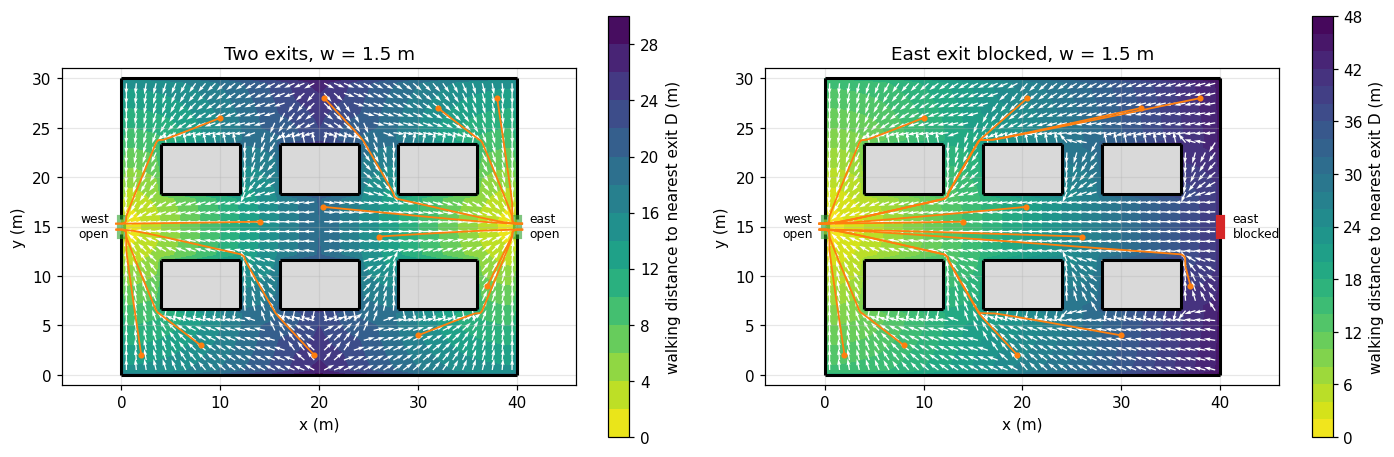

In [35]:
# Figure: distance map, desired directions and example routes.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# Start points avoid x = 20 m exactly: that line is equidistant from both exits, so D has a ridge there.
_starts = np.array([[19.5, 2], [20.5, 28], [8, 3], [32, 27], [14, 15.5], [26, 14], [2, 2], [38, 28],
                    [10, 26], [30, 4], [20.4, 17], [37, 9]], dtype=float)
for ax, blocked in zip(axes, [(), ("east",)]):
    mall = make_mall(1.5, blocked_exits=blocked)
    dm = dmap_ref if not blocked else make_distance_map(mall)
    ny, nx = dm.D.shape
    xs, ys = dm.x0 + dm.h * np.arange(nx), dm.y0 + dm.h * np.arange(ny)
    Dplot = np.ma.masked_invalid(np.where((xs[None, :] >= 0) & (xs[None, :] <= FLOOR_W), dm.D, np.nan))
    cf = ax.contourf(xs, ys, Dplot, levels=np.arange(0, np.nanmax(Dplot.filled(np.nan)) + 2, 2),
                     cmap="viridis_r", zorder=0)
    k = 10   # one arrow per metre
    sel = np.s_[5::k, 15::k]
    U, V = dm.ex[sel], dm.ey[sel]
    show = (U ** 2 + V ** 2 > 0) & np.isfinite(dm.D[sel])
    Xq, Yq = np.meshgrid(xs[15::k], ys[5::k])
    ax.quiver(Xq[show], Yq[show], U[show], V[show], color="w", scale=45, width=0.0025, zorder=1)
    for path in np.moveaxis(trace_paths(dm, _starts), 1, 0):
        ax.plot(path[:, 0], path[:, 1], color="tab:orange", lw=1.2, zorder=4)
    ax.plot(_starts[:, 0], _starts[:, 1], "o", color="tab:orange", ms=3, zorder=4)
    plot_mall(mall, ax=ax, title=("Two exits" if not blocked else "East exit blocked") + ", w = 1.5 m")
    fig.colorbar(cf, ax=ax, shrink=0.85, label="walking distance to nearest exit D (m)")
fig.tight_layout()
fig.savefig(FIG_DIR / "distance_map.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Parameters and time integration

The parameters of Section 2.6 are defined once here, so every later cell uses the same values. `verlet_step` is the Velocity-Verlet scheme with a velocity predictor from Section 2.7. It takes the acceleration as a function `accel(x, v)`. Here that is only the driving force, for check V1. The crowd runs use `crowd_step` (Section 3.4), a compiled copy of the same scheme with the full force; check V1b shows that the two give identical results.

Each step evaluates the forces **once**: the acceleration computed at the new position and the predicted velocity is reused as $\mathbf{a}_n$ in the next step. The speed cap $v_\text{max} = 1.3\,v_i^0$ is applied after each velocity update.

In [36]:
# 3.3 Model parameters (Section 2.6) and the time integrator (Section 2.7).
MASS = 80.0          # m: body mass (kg)                                  [2]
TAU = 0.5            # tau: relaxation time (s)                           [2]
A_REP = 2.0e3        # A: repulsion strength (N)                          [2]
B_REP = 0.08         # B: repulsion range (m)                             [2]
K_BODY = 1.2e5       # k: body-compression coefficient (kg s^-2)          [2]
KAPPA = 2.4e5        # kappa: sliding-friction coefficient (kg m^-1 s^-1) [2]
R_CUT = 1.3          # r_c: interaction cut-off, centre to centre (m)     derived
V_MAX_FACTOR = 1.3   # v_max = 1.3 v0                                     [1]
DT = 0.005           # time step (s): stability limit and convergence checked in V4 and V5
T_MAX = 600.0        # simulation time limit (s)
T_TARGET = 180.0     # evacuation target (s)
# Input model (Section 2.5).
R_MIN, R_MAX = 0.25, 0.35   # body radius r_i ~ U(R_MIN, R_MAX) (m)                         [2]
V0_MEAN, V0_SD = 1.34, 0.26 # desired speed v0 ~ N(V0_MEAN, V0_SD^2), truncated at +-3 sd (m/s) [1]
REMOVE_DIST = 0.5           # a person is evacuated 0.5 m beyond an exit line (m)


def driving_acceleration(v, v0, e0, tau=TAU):
    """Driving force divided by mass, (v0 e0 - v) / tau, for every person.

    v: (N, 2) velocities, v0: (N,) desired speeds, e0: (N, 2) unit desired directions.
    """
    return (v0[:, None] * e0 - v) / tau


def cap_speed(v, v0, factor=V_MAX_FACTOR):
    """Scale down any velocity faster than v_max = factor * v0, keeping its direction."""
    speed = np.hypot(v[:, 0], v[:, 1])
    v_max = factor * v0
    scale = np.where(speed > v_max, v_max / np.maximum(speed, 1e-12), 1.0)
    return v * scale[:, None]


def verlet_step(x, v, a, dt, accel, v0):
    """One step of Velocity-Verlet with a velocity predictor (Section 2.7).

    accel(x, v) returns the (N, 2) accelerations. `a` is the acceleration returned by the
    previous step (or accel(x0, v0) at the start), so each step costs ONE force evaluation.
    Returns (x, v, a) at the new time.
    """
    x_new = x + v * dt + 0.5 * a * dt * dt      # position update
    v_pred = v + a * dt                         # Euler predictor, keeps the scheme explicit
    a_new = accel(x_new, v_pred)                # forces at the new position, predicted velocity
    v_new = v + 0.5 * (a + a_new) * dt          # trapezoidal velocity update
    return x_new, cap_speed(v_new, v0), a_new

### 3.4 Social forces and cell lists

The force code follows Section 2.3 term by term. It is compiled with numba because every run takes about $10^4$ time steps and the study needs hundreds of runs.

- **Pedestrian forces** (`pair_force`): the repulsion $A e^{(r_{ij}-d_{ij})/B}$, plus body compression $k\,g$ and sliding friction $\kappa\,g\,\Delta v^t_{ji}$ when the bodies overlap. Pairs more than $r_c = 1.3$ m apart are skipped.
- **Walls** (`wall_force`): each outer wall segment uses its closest point. Each **shop block is one obstacle**, using the closest point on its rectangle. If its four edges were separate walls, a person just off a corner would feel that corner twice, because both edges have the same closest point there.
- **Cell lists** (`build_cells`): the floor and the 1 m strips outside the exits are split into 32 × 23 cells of 1.31 × 1.30 m (each side $\ge r_c$). The cells are refilled by counting sort at every step. Each person looks only at the 3 × 3 block of cells around them, and people who have left are skipped. `crowd_accel(..., use_cells=False)` does the plain $O(N^2)$ sum; it is used only for check V3.
- **Time step** (`crowd_step`): the same Velocity-Verlet + predictor scheme as `verlet_step`, including the speed cap. Check V1b shows that the two agree to rounding error.
- The force parameters are passed in as an array (`model_params`) rather than read as globals: numba freezes globals at compile time, and the sensitivity study changes $\tau$ and $A$.

In [37]:
# 3.4 Social forces, cell lists and the compiled time step (Sections 2.3 and 2.7).
# Everything inside the time loop is compiled with numba. The formulas are exactly those of Section 2.3.

# Cell grid: covers the floor plus the GRID_MARGIN strips outside the exits; every cell side >= R_CUT.
CELL_X0, CELL_Y0 = -GRID_MARGIN, 0.0
CELL_NX = int((FLOOR_W + 2 * GRID_MARGIN) // R_CUT)      # 32 columns
CELL_NY = int(FLOOR_H // R_CUT)                          # 23 rows
CELL_LX = (FLOOR_W + 2 * GRID_MARGIN) / CELL_NX          # 1.3125 m
CELL_LY = FLOOR_H / CELL_NY                              # 1.304 m
assert min(CELL_LX, CELL_LY) >= R_CUT, "cells must be at least as large as the cut-off"


def model_params(tau=TAU, a_rep=A_REP):
    """Pack the force parameters into one array for the compiled code (so none is frozen in by numba).

    tau and a_rep can be changed for the sensitivity study (Section 5.7); every other run uses the defaults.
    """
    return np.array([tau, a_rep, B_REP, K_BODY, KAPPA, R_CUT, V_MAX_FACTOR, MASS])


@njit(cache=False)
def field_direction(px, py, ex, ey, gx0, gy0, gh, exit_c):
    """Compiled version of desired_direction (Section 3.2) for one point: bilinear interpolation
    of the direction field, falling back to the nearest open exit centre where the field vanishes."""
    ny, nx = ex.shape
    fx, fy = (px - gx0) / gh, (py - gy0) / gh
    i = min(max(int(np.floor(fx)), 0), nx - 2)
    j = min(max(int(np.floor(fy)), 0), ny - 2)
    tx = min(max(fx - i, 0.0), 1.0)
    ty = min(max(fy - j, 0.0), 1.0)
    w00, w10, w01, w11 = (1 - tx) * (1 - ty), tx * (1 - ty), (1 - tx) * ty, tx * ty
    dx = w00 * ex[j, i] + w10 * ex[j, i + 1] + w01 * ex[j + 1, i] + w11 * ex[j + 1, i + 1]
    dy = w00 * ey[j, i] + w10 * ey[j, i + 1] + w01 * ey[j + 1, i] + w11 * ey[j + 1, i + 1]
    norm = np.hypot(dx, dy)
    if norm < 1e-6:
        best = np.inf
        for k in range(exit_c.shape[0]):
            cx, cy = exit_c[k, 0] - px, exit_c[k, 1] - py
            dd = np.hypot(cx, cy)
            if dd < best:
                best, dx, dy = dd, cx, cy
        norm = np.hypot(dx, dy)
    return dx / norm, dy / norm


@njit(cache=False)
def build_cells(x, alive):
    """Cell lists by counting sort: people in cell c are order[start[c]:start[c + 1]]."""
    n = x.shape[0]
    cell = np.full(n, -1, np.int64)
    count = np.zeros(CELL_NX * CELL_NY + 1, np.int64)
    for i in range(n):
        if alive[i]:
            cx = min(max(int(np.floor((x[i, 0] - CELL_X0) / CELL_LX)), 0), CELL_NX - 1)
            cy = min(max(int(np.floor((x[i, 1] - CELL_Y0) / CELL_LY)), 0), CELL_NY - 1)
            cell[i] = cy * CELL_NX + cx
            count[cell[i] + 1] += 1
    start = np.cumsum(count)
    order = np.empty(start[-1], np.int64)
    fill = start[:-1].copy()
    for i in range(n):
        if cell[i] >= 0:
            order[fill[cell[i]]] = i
            fill[cell[i]] += 1
    return cell, start, order


@njit(cache=False)
def pair_force(i, j, x, v, r, A, B, K, KAP, rc):
    """f_ij (N): soft repulsion + body compression along n_ij, sliding friction along t_ij."""
    dx, dy = x[i, 0] - x[j, 0], x[i, 1] - x[j, 1]
    d2 = dx * dx + dy * dy
    if d2 >= rc * rc or d2 == 0.0:
        return 0.0, 0.0
    d = np.sqrt(d2)
    nx, ny = dx / d, dy / d
    s = r[i] + r[j] - d                         # overlap r_ij - d_ij (negative when apart)
    f = A * np.exp(s / B)
    if s <= 0.0:
        return f * nx, f * ny
    f += K * s
    tx, ty = -ny, nx
    ft = KAP * s * ((v[j, 0] - v[i, 0]) * tx + (v[j, 1] - v[i, 1]) * ty)
    return f * nx + ft * tx, f * ny + ft * ty


@njit(cache=False)
def wall_force(d, nx, ny, vx, vy, ri, A, B, K, KAP):
    """f_iW (N) for a wall at distance d with unit normal (nx, ny) pointing towards the person."""
    s = ri - d
    f = A * np.exp(s / B)
    if s <= 0.0:
        return f * nx, f * ny
    f += K * s
    tx, ty = -ny, nx
    vt = vx * tx + vy * ty
    return f * nx - KAP * s * vt * tx, f * ny - KAP * s * vt * ty


@njit(cache=False)
def crowd_accel(x, v, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells):
    """Acceleration of every person: driving force + pedestrian forces + wall and shop forces, / m.

    walls: (M, 4) outer wall segments. shops: (S, 4) rectangles, each treated as ONE obstacle
    (closest point on its boundary) so that a shop corner is not counted twice.
    use_cells=False sums over all pairs (O(N^2)); it is used only to verify the cell lists (V3).
    """
    tau, A, B, K, KAP, rc, mass = prm[0], prm[1], prm[2], prm[3], prm[4], prm[5], prm[7]
    n = x.shape[0]
    acc = np.zeros((n, 2))
    if use_cells:
        cell, start, order = build_cells(x, alive)
    for i in range(n):
        if not alive[i]:
            continue
        xi, yi, vxi, vyi, ri = x[i, 0], x[i, 1], v[i, 0], v[i, 1], r[i]
        fx, fy = 0.0, 0.0
        # Pedestrian-pedestrian forces.
        if use_cells:
            cx, cy = cell[i] % CELL_NX, cell[i] // CELL_NX
            for gy in range(max(cy - 1, 0), min(cy + 2, CELL_NY)):
                for gx in range(max(cx - 1, 0), min(cx + 2, CELL_NX)):
                    c = gy * CELL_NX + gx
                    for k in range(start[c], start[c + 1]):
                        j = order[k]
                        if j != i:
                            px, py = pair_force(i, j, x, v, r, A, B, K, KAP, rc)
                            fx += px
                            fy += py
        else:
            for j in range(n):
                if j != i and alive[j]:
                    px, py = pair_force(i, j, x, v, r, A, B, K, KAP, rc)
                    fx += px
                    fy += py
        # Outer walls: closest point on each segment.
        for w in range(walls.shape[0]):
            x1, y1, x2, y2 = walls[w, 0], walls[w, 1], walls[w, 2], walls[w, 3]
            sx, sy = x2 - x1, y2 - y1
            t = min(max(((xi - x1) * sx + (yi - y1) * sy) / (sx * sx + sy * sy), 0.0), 1.0)
            dx, dy = xi - (x1 + t * sx), yi - (y1 + t * sy)
            d = np.hypot(dx, dy)
            if 0.0 < d < rc:
                wx, wy = wall_force(d, dx / d, dy / d, vxi, vyi, ri, A, B, K, KAP)
                fx += wx
                fy += wy
        # Shop blocks: closest point on the rectangle's boundary.
        for s in range(shops.shape[0]):
            x0, y0, x1, y1 = shops[s, 0], shops[s, 1], shops[s, 2], shops[s, 3]
            qx, qy = min(max(xi, x0), x1), min(max(yi, y0), y1)
            dx, dy = xi - qx, yi - qy
            d = np.hypot(dx, dy)
            if d > 0.0:
                if d < rc:
                    wx, wy = wall_force(d, dx / d, dy / d, vxi, vyi, ri, A, B, K, KAP)
                    fx += wx
                    fy += wy
            else:
                # Centre inside the shop (only if something has gone badly wrong): push out through
                # the nearest edge, with the depth counted as extra overlap.
                dl, dr, db, dt_ = xi - x0, x1 - xi, yi - y0, y1 - yi
                m = min(dl, dr, db, dt_)
                nx, ny = (-1.0, 0.0) if m == dl else (1.0, 0.0) if m == dr else (0.0, -1.0) if m == db else (0.0, 1.0)
                wx, wy = wall_force(-m, nx, ny, vxi, vyi, ri, A, B, K, KAP)
                fx += wx
                fy += wy
        # Driving force, written directly as an acceleration (same expression as driving_acceleration).
        e0x, e0y = field_direction(xi, yi, ex, ey, gx0, gy0, gh, exit_c)
        acc[i, 0] = (v0[i] * e0x - vxi) / tau + fx / mass
        acc[i, 1] = (v0[i] * e0y - vyi) / tau + fy / mass
    return acc


@njit(cache=False)
def crowd_step(x, v, a, dt, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells):
    """One step of the same Velocity-Verlet + predictor scheme as verlet_step (Section 3.3), compiled.

    V1b checks that it reproduces verlet_step exactly for a single pedestrian.
    """
    x_new = x + v * dt + 0.5 * a * dt * dt
    v_pred = v + a * dt
    a_new = crowd_accel(x_new, v_pred, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
    v_new = v + 0.5 * (a + a_new) * dt
    vmax_factor = prm[6]
    for i in range(x.shape[0]):                  # speed cap v_max = 1.3 v0, as in cap_speed
        speed = np.hypot(v_new[i, 0], v_new[i, 1])
        vmax = vmax_factor * v0[i]
        if speed > vmax:
            scale = vmax / max(speed, 1e-12)
            v_new[i, 0] *= scale
            v_new[i, 1] *= scale
    return x_new, v_new, a_new

### 3.5 Initial crowd, exits and one evacuation run

`sample_crowd` draws the inputs of Section 2.5: radii by inverse transform, desired speeds from the truncated normal by rejection, and start positions by random sequential placement with rejection (no overlap with other people, shop blocks or walls). `simulate` runs the compiled time loop. After each step, anyone 0.5 m beyond an exit line is removed and their exit time is recorded. Every 0.5 s it records the number out through each exit and the density in a 2 m half-disc inside each exit. At **every** step it also checks conservation (V2) and that nobody has passed through a wall or a closed exit; a failure stops the run with an error. `run_evacuation(N, w, seed)` wraps all of this and returns $T_\text{evac}$, $T_{90}$ and the records.

**Seeds and common random numbers.** Replication $k$ uses seed $1000 + k$ in every scenario. The exit width does not change the free floor, so the same seed gives exactly the same starting crowd for every $w$. Different widths are therefore compared on identical crowds (common random numbers), which lowers the variance of the differences between them.

In [38]:
# 3.5 Initial crowd, exits and the evacuation run.
DENSITY_RADIUS = 2.0                                  # density is measured in a 2 m half-disc inside each exit
DENSITY_AREA = 0.5 * np.pi * DENSITY_RADIUS ** 2      # 6.28 m^2
REPLICATION_SEEDS = [1000 + k for k in range(40)]     # replication k uses seed 1000 + k in every scenario


def sample_crowd(n, mall, rng, v0_mean=V0_MEAN, v0_sd=V0_SD, max_tries=20_000):
    """Random variates of Section 2.5: radii, desired speeds and non-overlapping start positions.

    Radii: U(R_MIN, R_MAX). Desired speeds: N(v0_mean, v0_sd^2) truncated to mean +- 3 sd by
    rejection. Positions: random sequential placement, rejecting any point that overlaps a person
    already placed, a shop block or an outer wall. Exits do not change the free floor, so the same
    seed gives the same crowd for every exit width (common random numbers across widths).
    """
    W, H = mall.size
    r = rng.uniform(R_MIN, R_MAX, n)
    v0 = rng.normal(v0_mean, v0_sd, n)
    lo, hi = v0_mean - 3 * v0_sd, v0_mean + 3 * v0_sd
    bad = (v0 < lo) | (v0 > hi)
    while bad.any():                                   # rejection: redraw only the out-of-range values
        v0[bad] = rng.normal(v0_mean, v0_sd, bad.sum())
        bad = (v0 < lo) | (v0 > hi)
    x = np.empty((n, 2))
    for i in range(n):
        for _ in range(max_tries):
            p = rng.uniform([r[i], r[i]], [W - r[i], H - r[i]])
            if _distance_to_shops(p[0], p[1], mall.shops) < r[i]:
                continue
            if i and np.min(np.hypot(*(x[:i] - p).T) - r[:i]) < r[i]:
                continue
            x[i] = p
            break
        else:
            raise RuntimeError(f"could not place person {i} of {n} without overlap")
    return x, r, v0


@njit(cache=False)
def simulate(x, v, r, v0, walls, shops, ex, ey, gx0, gy0, gh, exit_c, exit_open, prm, dt, t_max,
             half_w, rec_every, snap_steps, use_cells):
    """Advance the crowd until everyone is out or t_max is reached (compiled).

    Checks at EVERY step (raising an error on failure):
      V2  n_inside + n_out == N;
      no NaN positions; nobody crosses the north/south walls; anyone outside the floor in x is
      inside an OPEN exit gap (so nobody passes through a wall or a blocked exit).
    Returns per-person exit time and exit (0 = west, 1 = east), the recording times, the cumulative
    count through each exit and the density in front of each exit (every rec_every steps and at the
    final step), snapshots, and the step count.
    """
    n = x.shape[0]
    x, v = x.copy(), v.copy()
    alive = np.ones(n, np.bool_)
    exit_time = np.full(n, np.nan)
    exit_side = np.full(n, -1, np.int64)
    n_side = np.zeros(2, np.int64)
    n_steps = int(round(t_max / dt))
    rec_out = np.zeros((n_steps // rec_every + 2, 2), np.int64)
    rec_dens = np.zeros((n_steps // rec_every + 2, 2))
    rec_t = np.zeros(n_steps // rec_every + 2)
    snaps = np.full((snap_steps.shape[0], n, 2), np.nan)
    a = crowd_accel(x, v, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
    n_out, step, rec = 0, 0, 0
    while True:
        # Record (first and last step included) and take snapshots.
        done = n_out == n or step >= n_steps
        if step % rec_every == 0 or done:
            rec_t[rec] = step * dt
            rec_out[rec, 0], rec_out[rec, 1] = n_side[0], n_side[1]
            for i in range(n):
                if alive[i]:
                    for e in range(2):
                        ex_x = 0.0 if e == 0 else FLOOR_W
                        inside = x[i, 0] >= 0.0 if e == 0 else x[i, 0] <= FLOOR_W
                        if inside and np.hypot(x[i, 0] - ex_x, x[i, 1] - EXIT_Y) < DENSITY_RADIUS:
                            rec_dens[rec, e] += 1.0 / DENSITY_AREA
            rec += 1
        for s in range(snap_steps.shape[0]):
            if snap_steps[s] == step:
                for i in range(n):
                    if alive[i]:
                        snaps[s, i, 0], snaps[s, i, 1] = x[i, 0], x[i, 1]
        if done:
            break

        x, v, a = crowd_step(x, v, a, dt, r, v0, alive, walls, shops, ex, ey, gx0, gy0, gh, exit_c, prm, use_cells)
        step += 1

        # Remove anyone 0.5 m beyond an exit line.
        for i in range(n):
            if alive[i]:
                side = 0 if x[i, 0] < -REMOVE_DIST else 1 if x[i, 0] > FLOOR_W + REMOVE_DIST else -1
                if side >= 0:
                    alive[i] = False
                    exit_time[i], exit_side[i] = step * dt, side
                    n_side[side] += 1
                    n_out += 1
                    v[i, 0] = v[i, 1] = a[i, 0] = a[i, 1] = 0.0

        # Per-step checks.
        n_inside = 0
        for i in range(n):
            if alive[i]:
                n_inside += 1
                xi, yi = x[i, 0], x[i, 1]
                if not (np.isfinite(xi) and np.isfinite(yi)):
                    raise FloatingPointError("non-finite position: the integration has become unstable")
                if yi < 0.0 or yi > FLOOR_H:
                    raise AssertionError("a pedestrian crossed the north or south wall")
                if xi < 0.0 or xi > FLOOR_W:
                    e = 0 if xi < 0.0 else 1
                    if not exit_open[e] or abs(yi - EXIT_Y) > half_w + R_MAX:
                        raise AssertionError("a pedestrian left the floor outside an open exit gap")
        if n_inside + n_out != n:
            raise AssertionError("V2 failed: n_inside + n_out != N")
    return exit_time, exit_side, rec_t[:rec], rec_out[:rec], rec_dens[:rec], snaps, step


_MALL_CACHE, _DMAP_CACHE = {}, {}


def get_mall(w, blocked=()):
    """Mall and distance map for exit width w (cached: the fast marching map takes ~0.2 s)."""
    key = (round(float(w), 9), tuple(sorted(blocked)))
    if key not in _MALL_CACHE:
        _MALL_CACHE[key] = make_mall(w, blocked_exits=blocked)
        _DMAP_CACHE[key] = make_distance_map(_MALL_CACHE[key])
    return _MALL_CACHE[key], _DMAP_CACHE[key]


def outer_walls(mall):
    """The outer wall segments (make_mall appends the four edges of every shop after them)."""
    return mall.walls[: len(mall.walls) - 4 * len(mall.shops)]


@dataclass
class RunResult:
    n: int
    w: float
    seed: int
    blocked: tuple
    t_evac: float          # time the last person leaves (s); NaN if the run did not clear by t_max
    t_90: float            # time 90 % have left (s); NaN if fewer than 90 % left
    cleared: bool
    n_west: int            # people out through each exit
    n_east: int
    r: np.ndarray          # (N,) body radii (m)
    v0: np.ndarray         # (N,) desired speeds (m/s)
    exit_time: np.ndarray  # (N,) exit time of each person (NaN if still inside)
    exit_side: np.ndarray  # (N,) 0 = west, 1 = east, -1 = still inside
    t_rec: np.ndarray      # recording times (s)
    n_out_rec: np.ndarray  # (n_rec, 2) cumulative number out through west / east
    density_rec: np.ndarray  # (n_rec, 2) people per m^2 in the half-disc inside each exit
    snaps: np.ndarray      # (n_snap, N, 2) positions at snap_times (NaN once evacuated)
    snap_times: tuple
    wall_s: float          # wall-clock time of the run (s)


def run_evacuation(n, w, seed, blocked=(), dt=DT, t_max=T_MAX, tau=TAU, v0_mean=V0_MEAN, a_rep=A_REP,
                   snap_times=(), rec_dt=0.5, use_cells=True):
    """One evacuation run: sample a crowd with `seed`, simulate it, return a RunResult."""
    mall, dm = get_mall(w, blocked)
    rng = np.random.default_rng(seed)
    x, r, v0 = sample_crowd(n, mall, rng, v0_mean=v0_mean)
    exit_open = np.array(["west" in mall.exit_names, "east" in mall.exit_names])
    rec_every = max(1, int(round(rec_dt / dt)))
    snap_steps = np.array([int(round(t / dt)) for t in snap_times], dtype=np.int64)
    t0 = time.perf_counter()
    exit_time, exit_side, t_rec, n_out_rec, dens, snaps, steps = simulate(
        x, np.zeros_like(x), r, v0, outer_walls(mall), mall.shops, dm.ex, dm.ey, dm.x0, dm.y0, dm.h,
        mall.exit_centres, exit_open, model_params(tau, a_rep), dt, t_max, w / 2, rec_every, snap_steps, use_cells)
    wall_s = time.perf_counter() - t0
    out = np.isfinite(exit_time)
    # V2 again, on the returned data, and X3: nobody leaves through a blocked exit.
    assert out.sum() + (~out).sum() == n and np.array_equal(out, exit_side >= 0)
    assert all(exit_open[s] for s in np.unique(exit_side[out])), "someone left through a blocked exit"
    k90 = int(np.ceil(0.9 * n))
    times = np.sort(exit_time[out])
    return RunResult(n=n, w=float(w), seed=int(seed), blocked=tuple(blocked),
                     t_evac=float(times[-1]) if out.all() else np.nan,
                     t_90=float(times[k90 - 1]) if out.sum() >= k90 else np.nan,
                     cleared=bool(out.all()), n_west=int((exit_side == 0).sum()), n_east=int((exit_side == 1).sum()),
                     r=r, v0=v0, exit_time=exit_time, exit_side=exit_side, t_rec=t_rec,
                     n_out_rec=n_out_rec, density_rec=dens, snaps=snaps, snap_times=tuple(snap_times), wall_s=wall_s)


def mean_ci(values, level=0.95):
    """Sample mean and half-width of the t-based confidence interval (Section 2.8)."""
    from scipy import stats
    v = np.asarray(values, float)
    half = stats.t.ppf(0.5 + level / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), half


_RUN_CACHE = {}


def run_cached(n, w, seed, blocked=(), **kw):
    """run_evacuation, memoised, so a scenario used by several cells (e.g. V6 and the pilot) is simulated once."""
    key = (n, round(float(w), 9), seed, tuple(sorted(blocked)), tuple(sorted(kw.items())))
    if key not in _RUN_CACHE:
        _RUN_CACHE[key] = run_evacuation(n, w, seed, blocked=blocked, **kw)
    return _RUN_CACHE[key]


In [39]:
# Cost of one run. The first call compiles the numba functions (a few seconds, once per session).
_t = time.perf_counter()
run_evacuation(20, 1.5, REPLICATION_SEEDS[0], t_max=1.0)
print(f"numba compilation: {time.perf_counter() - _t:.1f} s (once)")
for _n in (100, 400):
    _res = run_evacuation(_n, 1.5, REPLICATION_SEEDS[0])
    _steps = int(round(_res.t_evac / DT))
    print(f"N = {_n:3d}, w = 1.5 m: T_evac = {_res.t_evac:6.2f} s simulated in {_res.wall_s:5.2f} s of compute "
          f"({_steps} steps, {1e6 * _res.wall_s / _steps:5.1f} us per step)")

numba compilation: 17.4 s (once)
N = 100, w = 1.5 m: T_evac =  39.23 s simulated in  0.19 s of compute (7846 steps,  24.6 us per step)
N = 400, w = 1.5 m: T_evac =  95.96 s simulated in  2.63 s of compute (19192 steps, 136.9 us per step)


## 4. Verification

Every check is an `assert` or tolerance test, so "Run all" stops if one fails. V1–V6 are below, followed by log–log plots of how the integrator error and the Monte Carlo error scale.

### V1: single pedestrian, analytic relaxation

One person starts from rest in open space with a fixed desired direction, so only the driving force acts and the motion reduces to $\dot v = (v_0 - v)/\tau$. The exact solution is $v(t) = v_0\left(1 - e^{-t/\tau}\right)$, $x(t) = v_0\left[t - \tau\left(1 - e^{-t/\tau}\right)\right]$. This tests the integrator, the sign of the driving term, $\tau$ and the units, using the same `verlet_step` as the crowd simulation.

**Expected error.** On this equation, with $z = -\Delta t/\tau$, the scheme multiplies the error by the main root of $\lambda^2 - \left(1 + \tfrac32 z\right)\lambda + \tfrac12 z = 0$ each step, which is $\lambda = 1 + z + \tfrac12 z^2 - \tfrac14 z^3 + O(z^4)$. (The second root is about $z/2$ and dies out immediately.) $\lambda$ matches $e^{z}$ up to $z^2$, so the method is **second order**, with local error $\tfrac{5}{12}|z|^3$ per step (Heun's method would have $\tfrac16|z|^3$). Accumulated over the run, the speed error peaks at $t = \tau$ at about

$$
v_0 \left(\frac{\Delta t}{\tau}\right)^2 \frac{5}{12\,e} \approx 2.1 \times 10^{-5}\ \text{m/s} \quad \text{for } \Delta t = 0.005 \text{ s}.
$$

**Pass criterion.** The maximum speed error (m/s) and position error (m) over 5 s ($10\tau$) must both be below $2.5 \times 10^{-4}$. This is about 12 times the expected error, but tight enough that a first-order method fails it: explicit Euler, with expected error $v_0(\Delta t/\tau)/(2e) \approx 2.5 \times 10^{-3}$ m/s, is run alongside as a negative control.

V1 PASS: dt = 0.005 s, max |v - v_exact| = 2.05e-05 m/s, max |x - x_exact| = 1.67e-05 m (tolerance 2.5e-04)
     For comparison, explicit Euler at the same dt: max speed error 2.48e-03 m/s (fails, as it should)


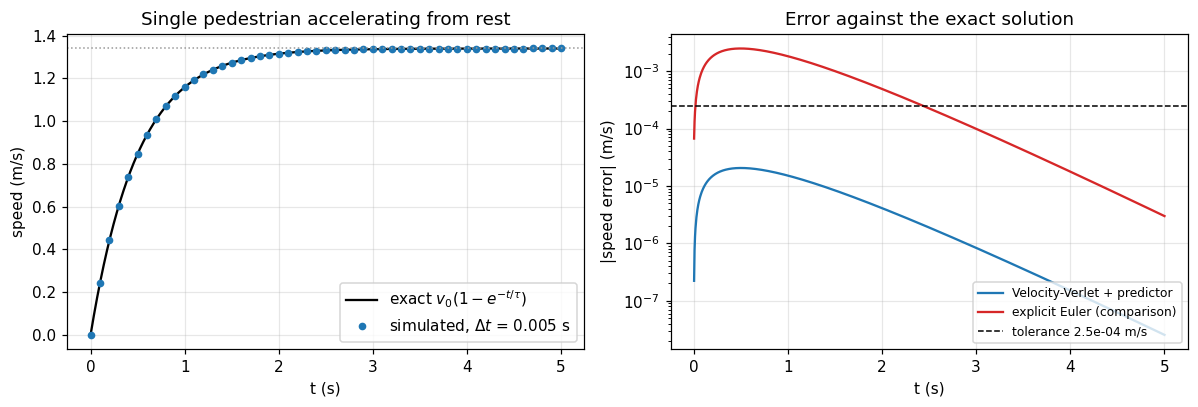

In [40]:
# V1: one pedestrian from rest in open space vs the analytic relaxation v(t) = v0 (1 - exp(-t/tau)).
V1_V0, V1_T_END, V1_TOL = 1.34, 5.0, 2.5e-4       # desired speed (m/s), duration = 10 tau (s), tolerance (m/s)
_v0 = np.array([V1_V0])
_e0 = np.array([[1.0, 0.0]])                     # fixed direction: no walls, no other people


def _accel_free(x, v):
    return driving_acceleration(v, _v0, _e0)


def relaxation_run(dt, scheme="verlet", t_end=V1_T_END):
    """Speed and distance walked over time for one pedestrian starting from rest."""
    n = int(round(t_end / dt))
    x, v = np.zeros((1, 2)), np.zeros((1, 2))
    a = _accel_free(x, v)
    speed, dist = np.zeros(n + 1), np.zeros(n + 1)
    for k in range(1, n + 1):
        if scheme == "verlet":
            x, v, a = verlet_step(x, v, a, dt, _accel_free, _v0)
        else:                                    # explicit Euler, for comparison only
            x, v = x + v * dt, v + _accel_free(x, v) * dt
        speed[k], dist[k] = np.hypot(*v[0]), np.hypot(*x[0])
    return dt * np.arange(n + 1), speed, dist


def relaxation_exact(t, v0=V1_V0, tau=TAU):
    """Exact speed and distance: v = v0 (1 - e^(-t/tau)), x = v0 (t - tau (1 - e^(-t/tau)))."""
    return v0 * (1 - np.exp(-t / tau)), v0 * (t - tau * (1 - np.exp(-t / tau)))


t1, s_vv, x_vv = relaxation_run(DT)
s_ex, x_ex = relaxation_exact(t1)
err_v, err_x = np.max(np.abs(s_vv - s_ex)), np.max(np.abs(x_vv - x_ex))
assert err_v < V1_TOL, f"V1 failed: max speed error {err_v:.2e} m/s >= {V1_TOL:.1e} m/s"
assert err_x < V1_TOL, f"V1 failed: max position error {err_x:.2e} m >= {V1_TOL:.1e} m"
print(f"V1 PASS: dt = {DT} s, max |v - v_exact| = {err_v:.2e} m/s, max |x - x_exact| = {err_x:.2e} m "
      f"(tolerance {V1_TOL:.1e})")

# The tolerance is strict enough to reject a first-order method: explicit Euler fails it.
_, s_eu, _ = relaxation_run(DT, scheme="euler")
err_eu = np.max(np.abs(s_eu - s_ex))
assert err_eu > V1_TOL, "tolerance too loose: it would not detect a first-order integrator"
print(f"     For comparison, explicit Euler at the same dt: max speed error {err_eu:.2e} m/s (fails, as it should)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t1, s_ex, "k-", lw=1.5, label=r"exact $v_0(1-e^{-t/\tau})$")
axes[0].plot(t1[::20], s_vv[::20], "o", ms=4, color="tab:blue", label=f"simulated, $\\Delta t$ = {DT} s")
axes[0].axhline(V1_V0, color="0.6", ls=":", lw=1)
axes[0].set(xlabel="t (s)", ylabel="speed (m/s)", title="Single pedestrian accelerating from rest")
axes[0].legend(loc="lower right")
axes[1].semilogy(t1[1:], np.abs(s_vv - s_ex)[1:], color="tab:blue", label="Velocity-Verlet + predictor")
axes[1].semilogy(t1[1:], np.abs(s_eu - s_ex)[1:], color="tab:red", label="explicit Euler (comparison)")
axes[1].axhline(V1_TOL, color="k", ls="--", lw=1, label=f"tolerance {V1_TOL:.1e} m/s")
axes[1].set(xlabel="t (s)", ylabel="|speed error| (m/s)", title="Error against the exact solution")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "verification_relaxation.png", dpi=150, bbox_inches="tight")
plt.show()

### V1b: the compiled crowd code matches the tested Python code

The crowd runs use the compiled `crowd_step` and `field_direction`, not the Python `verlet_step` and `desired_direction` tested by V1 and Section 3.2. This check runs both versions side by side, for one pedestrian over 5 s and for the direction field at 5000 random points. They must agree to $10^{-12}$.

In [41]:
# V1b: the compiled crowd code reproduces the Python code that V1 and Section 3.2 tested.
# (a) crowd_step = verlet_step for one pedestrian with a uniform desired direction (1, 0), no walls.
_no_walls = np.zeros((0, 4))
_field = (np.ones((2, 2)), np.zeros((2, 2)), -100.0, -100.0, 1000.0, np.array([[0.0, 15.0]]))  # e0 = (1, 0)
_one = dict(r=np.array([0.3]), v0=_v0, alive=np.ones(1, np.bool_))
_xc, _vc = np.array([[5.0, 15.0]]), np.zeros((1, 2))
_ac = crowd_accel(_xc, _vc, _one["r"], _v0, _one["alive"], _no_walls, _no_walls, *_field, model_params(), True)
_xp, _vp = _xc.copy(), _vc.copy()
_ap = _accel_free(_xp, _vp)
_diff = 0.0
for _ in range(int(round(V1_T_END / DT))):
    _xc, _vc, _ac = crowd_step(_xc, _vc, _ac, DT, _one["r"], _v0, _one["alive"], _no_walls, _no_walls,
                               *_field, model_params(), True)
    _xp, _vp, _ap = verlet_step(_xp, _vp, _ap, DT, _accel_free, _v0)
    _diff = max(_diff, np.abs(_xc - _xp).max(), np.abs(_vc - _vp).max())
assert _diff < 1e-12, f"compiled step differs from verlet_step by {_diff:.2e}"

# (b) field_direction (compiled) = desired_direction (Python) at 5000 random points.
_mall, _dm = get_mall(1.5)
_chk = np.random.default_rng(SEED + 1)
_P = np.column_stack([_chk.uniform(-GRID_MARGIN, FLOOR_W + GRID_MARGIN, 5000), _chk.uniform(0, FLOOR_H, 5000)])
_e_py = np.column_stack(desired_direction(_dm, _P[:, 0], _P[:, 1]))
_e_nb = np.array([field_direction(px, py, _dm.ex, _dm.ey, _dm.x0, _dm.y0, _dm.h, _dm.exit_centres) for px, py in _P])
assert np.allclose(_e_nb, _e_py, rtol=0, atol=1e-12), "compiled direction lookup differs"
print(f"V1b PASS: compiled step vs verlet_step over {V1_T_END:g} s: max difference {_diff:.1e}; "
      f"compiled vs Python direction field at 5000 points: max difference {np.abs(_e_nb - _e_py).max():.1e}")

V1b PASS: compiled step vs verlet_step over 5 s: max difference 0.0e+00; compiled vs Python direction field at 5000 points: max difference 0.0e+00


### V2: conservation of people

$N_\text{inside} + N_\text{out} = N$ must hold at every step of every run. The check is built into `simulate`, so it runs in every simulation in this notebook. Two more checks run alongside it: no position becomes non-finite, and nobody leaves the floor except through an open exit. The cell below also checks the returned records of a two-exit run and a blocked-exit run.

In [42]:
# V2: conservation. simulate() raises an error at any step where n_inside + n_out != N, a position is
# not finite, or someone is outside the floor anywhere other than an open exit gap. Every run in this
# notebook therefore passes V2 at every step, or "Run all" stops. Here the returned records are also checked.
for _n, _blocked in [(400, ()), (200, ("east",))]:
    _res = run_evacuation(_n, 1.5, REPLICATION_SEEDS[0], blocked=_blocked)
    _total = _res.n_out_rec.sum(axis=1)
    assert _res.cleared and _total[0] == 0 and _total[-1] == _n, "everyone must leave, and only once"
    assert np.all(np.diff(_total) >= 0), "the number evacuated can never fall"
    assert _res.n_west + _res.n_east == _n == np.isfinite(_res.exit_time).sum()
    if _blocked:
        assert _res.n_east == 0, "nobody may leave through the blocked exit"
    print(f"V2 PASS: N = {_n}, blocked = {', '.join(_blocked) or 'none':<4}: n_inside + n_out = N at all "
          f"{int(round(_res.t_evac / DT))} steps; out through west {_res.n_west}, east {_res.n_east}")

V2 PASS: N = 400, blocked = none: n_inside + n_out = N at all 19192 steps; out through west 215, east 185
V2 PASS: N = 200, blocked = east: n_inside + n_out = N at all 17711 steps; out through west 200, east 0


### V3: cell lists give the same forces as the brute-force sum

The cell lists must find every pair closer than $r_c$. Two random crowds are tested, each with 10 % of people marked as already evacuated:

- a dense patch of about 2 people/m², with many overlapping bodies, so every force term is active;
- a crowd spread over the whole grid, including the strips outside the exits where cell indices are clamped.

The accelerations from the cell lists and from the $O(N^2)$ sum must agree to a relative tolerance of $10^{-10}$; only the order of summation differs.

In [43]:
# V3: forces from the cell lists equal the brute-force O(N^2) sum (same cut-off) on random crowds.
_mall, _dm = get_mall(1.5)
_chk = np.random.default_rng(SEED + 2)
for _label, _box in [("dense patch", (2.0, 22.0, 10.0, 20.0)),            # ~2 people/m^2, many overlaps
                     ("whole floor and exit strips", (-GRID_MARGIN, FLOOR_W + GRID_MARGIN, 0.0, FLOOR_H))]:
    _pts = np.column_stack([_chk.uniform(_box[0], _box[1], 4000), _chk.uniform(_box[2], _box[3], 4000)])
    _xs = _pts[_distance_to_shops(_pts[:, 0], _pts[:, 1], _mall.shops) > 0][:400]   # not inside a shop
    _n = len(_xs)
    _vs, _rs = _chk.normal(0, 1, (_n, 2)), _chk.uniform(R_MIN, R_MAX, _n)
    _v0s, _alive = _chk.uniform(0.8, 1.8, _n), _chk.random(_n) > 0.1         # 10 % already evacuated
    _args = (_xs, _vs, _rs, _v0s, _alive, outer_walls(_mall), _mall.shops, _dm.ex, _dm.ey, _dm.x0, _dm.y0,
             _dm.h, _mall.exit_centres, model_params())
    _a_cell, _a_brute = crowd_accel(*_args, True), crowd_accel(*_args, False)
    np.testing.assert_allclose(_a_cell, _a_brute, rtol=1e-10, atol=1e-10)
    assert np.all(_a_cell[~_alive] == 0), "evacuated people must feel no force"
    _d = np.hypot(*(_xs[_alive, None] - _xs[None, _alive]).transpose(2, 0, 1))
    _iu = np.triu_indices(_alive.sum(), 1)
    _n_pairs = int((_d[_iu] < R_CUT).sum())
    _n_overlap = int((_d[_iu] < (_rs[_alive, None] + _rs[None, _alive])[_iu]).sum())
    print(f"V3 PASS ({_label}): {_n_pairs} interacting pairs, {_n_overlap} overlapping; "
          f"max |a_cell - a_brute| = {np.abs(_a_cell - _a_brute).max():.1e} m/s^2 "
          f"(max |a| = {np.abs(_a_brute).max():.1e} m/s^2)")

V3 PASS (dense patch): 1899 interacting pairs, 433 overlapping; max |a_cell - a_brute| = 7.3e-12 m/s^2 (max |a| = 5.3e+04 m/s^2)
V3 PASS (whole floor and exit strips): 296 interacting pairs, 63 overlapping; max |a_cell - a_brute| = 9.1e-13 m/s^2 (max |a| = 3.9e+04 m/s^2)


### V4: time-step convergence

A crowd is a chaotic many-body system. A change in $\Delta t$ eventually changes the order in which two people squeeze through an exit, and from then on the two runs follow different trajectories. Individual evacuation times are therefore **not** expected to converge pointwise over a whole run. V4 tests convergence in the two ways that are meaningful:

**(a) Trajectories over a short horizon.** One crowd ($N = 100$, $w = 1.5$ m, seed 1000) is run for 5 s at $\Delta t$ = 0.02, 0.01, 0.005, 0.0025 and 0.00125 s and compared with a reference run at $\Delta t = 0.0003125$ s. The error is the largest position difference over all people at $t = 5$ s. As a control, the same crowd is also run with the pedestrian, wall and shop forces switched off, so each person only follows the distance-map direction field.

- Without contacts the right-hand side is smooth, so the error must fall at **second order**. Pass: fitted slope in [1.8, 2.2].
- With contacts the observed order is expected to drop towards 1. The contact forces contain $g(x) = \max(x, 0)$, so the force has a kink when two bodies touch, and the scheme loses accuracy on the steps that cross it. Pass: the error falls with every halving of $\Delta t$ from 0.01 s down, and is below 1 cm at the production step.

**(b) The distribution of evacuation times over seeds.** $N = 400$, $w = 1.5$ m (a dense case), $R = 10$ seeds, at $\Delta t$ = 0.01, 0.005 and 0.0025 s. The same seed gives the same starting crowd at every $\Delta t$, so the differences $d$ between the production step and $\Delta t/2$ are paired by seed. Two statistics are compared: $T_\text{evac}$ itself, and the mean exit time over all people, which averages out the noise of single trajectories.

The pass criterion bounds the bias with 95 % confidence: $|\bar d| + h_{95}(d) < 5\,\%$ of the mean. A first, tighter criterion of 2 % was below what a 10-seed comparison can resolve. $T_\text{evac}$ is the time of the *last* person out, an extreme value with a run-to-run standard deviation of about 2.5 s here. Pairing by seed does not remove that noise, because the trajectories at two time steps drift apart within seconds (part a). A 5 % bound on $T_\text{evac}$ corresponds to about 5 cm in the required exit width near the 180 s threshold. This is the same order as the Monte Carlo uncertainty of the main study, and it is carried into the discussion of results.


crowd (all forces)         : max position error at t = 5 s: 1.1e-02, 1.3e-02, 6.4e-03, 2.9e-03, 1.1e-03 m
                             error ratio per halving [0.86 2.07 2.23 2.51], fitted order 0.88
free walkers (no contacts) : max position error at t = 5 s: 6.9e-04, 2.0e-04, 3.7e-05, 8.6e-06, 2.2e-06 m
                             error ratio per halving [3.45 5.45 4.24 4.01], fitted order 2.12
V4a PASS: free walkers converge at order 2.12; crowd error falls with every halving from 0.01 s, 0.64 cm at dt = 0.005 s (tolerance 1 cm)
   T_evac          dt = 0.01    s:  90.43 +- 1.93 s (mean +- 95 % CI, R = 10)
   T_evac          dt = 0.005   s:  91.44 +- 2.01 s (mean +- 95 % CI, R = 10)
   T_evac          dt = 0.0025  s:  90.71 +- 1.52 s (mean +- 95 % CI, R = 10)
V4b PASS (T_evac): dt - dt/2 = +0.73 +- 1.26 s (paired, 95 % CI), so |bias| < 2.2 % (limit 5 %). For comparison, 2 dt - dt/2 = -0.28 +- 1.89 s.
   mean exit time  dt = 0.01    s:  37.07 +- 0.42 s (mean +- 95 % CI, R = 10)
   mea

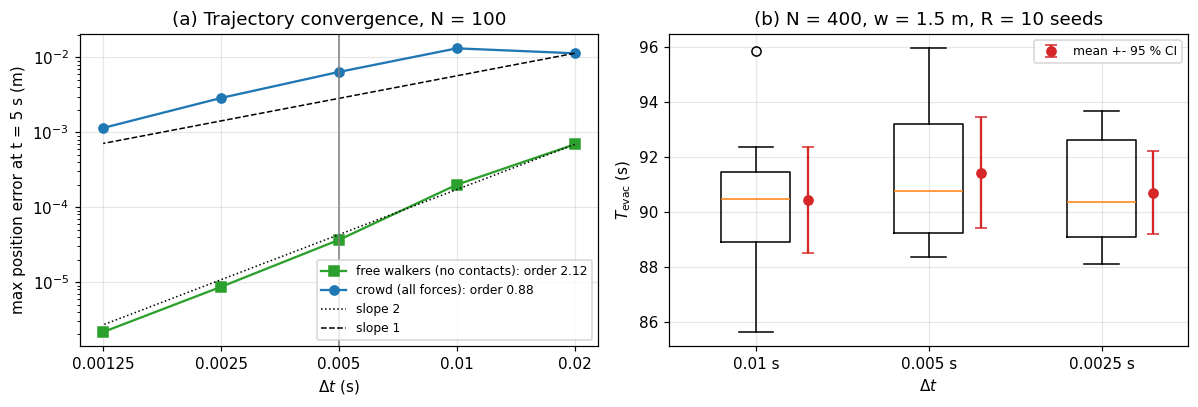

In [44]:
# V4: time-step convergence. (a) trajectories over 5 s; (b) mean T_evac over seeds.
def positions_at(n, w, seed, dt, t_end, interactions=True):
    """Positions of a sampled crowd after t_end seconds (NaN for anyone already out).

    interactions=False switches off every pedestrian, wall and shop force (A = k = kappa = 0),
    leaving only the driving force along the distance-map direction field.
    """
    mall, dm = get_mall(w)
    x, r, v0 = sample_crowd(n, mall, np.random.default_rng(seed))
    prm = model_params()
    if not interactions:
        prm[1] = prm[3] = prm[4] = 0.0
    snap = np.array([int(round(t_end / dt))], dtype=np.int64)
    out = simulate(x, np.zeros_like(x), r, v0, outer_walls(mall), mall.shops, dm.ex, dm.ey, dm.x0, dm.y0, dm.h,
                   mall.exit_centres, np.array([True, True]), prm, dt, t_end, w / 2, 10**9, snap, True)
    return out[5][0]


# (a) Trajectory error at t = 5 s against a reference run at dt = 0.0003125 s.
V4_DTS = np.array([0.02, 0.01, 0.005, 0.0025, 0.00125])
V4_DT_REF, V4_T, V4_TOL_X = 0.0003125, 5.0, 0.01        # reference step (s), horizon (s), tolerance (m)
v4_err = {}
for _label, _inter in [("crowd (all forces)", True), ("free walkers (no contacts)", False)]:
    _ref = positions_at(100, 1.5, REPLICATION_SEEDS[0], V4_DT_REF, V4_T, _inter)
    _e = []
    for _dt in V4_DTS:
        _p = positions_at(100, 1.5, REPLICATION_SEEDS[0], _dt, V4_T, _inter)
        _ok = np.isfinite(_p[:, 0]) & np.isfinite(_ref[:, 0])
        _e.append(np.abs(_p[_ok] - _ref[_ok]).max())
    v4_err[_label] = np.array(_e)
    _slope = np.polyfit(np.log(V4_DTS), np.log(v4_err[_label]), 1)[0]
    _ratios = v4_err[_label][:-1] / v4_err[_label][1:]
    print(f"{_label:<27}: max position error at t = {V4_T:g} s: "
          + ", ".join(f"{e:.1e}" for e in v4_err[_label])
          + f" m\n{'':<29}error ratio per halving {np.round(_ratios, 2)}, fitted order {_slope:.2f}")
    v4_err[_label + " order"] = _slope
assert 1.8 <= v4_err["free walkers (no contacts) order"] <= 2.2, "V4a failed: free walkers are not second order"
_ec = v4_err["crowd (all forces)"]
assert np.all(np.diff(_ec[V4_DTS <= 0.01]) < 0), "V4a failed: crowd error does not fall as dt is halved"
assert _ec[np.isclose(V4_DTS, DT)][0] < V4_TOL_X, "V4a failed: crowd error at the production step too large"
print(f"V4a PASS: free walkers converge at order {v4_err['free walkers (no contacts) order']:.2f}; "
      f"crowd error falls with every halving from 0.01 s, {_ec[np.isclose(V4_DTS, DT)][0] * 100:.2f} cm at dt = {DT} s "
      f"(tolerance {V4_TOL_X * 100:g} cm)")

# (b) T_evac and the mean exit time over seeds at three time steps (N = 400, w = 1.5 m), paired by seed.
V4_N, V4_W, V4_R, V4_TOL_REL = 400, 1.5, 10, 0.05
V4_DTS_B = (2 * DT, DT, DT / 2)
_runs = {dt: [run_evacuation(V4_N, V4_W, s, dt=dt) for s in REPLICATION_SEEDS[:V4_R]] for dt in V4_DTS_B}
v4_T = {dt: np.array([r.t_evac for r in rs]) for dt, rs in _runs.items()}
v4_mean_exit = {dt: np.array([np.mean(r.exit_time) for r in rs]) for dt, rs in _runs.items()}
for _name, _X in [("T_evac", v4_T), ("mean exit time", v4_mean_exit)]:
    for dt in V4_DTS_B:
        _m, _h = mean_ci(_X[dt])
        print(f"   {_name:<15} dt = {dt:<7g} s: {_m:6.2f} +- {_h:4.2f} s (mean +- 95 % CI, R = {V4_R})")
    _dm, _dh = mean_ci(_X[DT] - _X[DT / 2])
    _d2m, _d2h = mean_ci(_X[2 * DT] - _X[DT / 2])
    _bound = (abs(_dm) + _dh) / _X[DT / 2].mean()
    assert _bound < V4_TOL_REL, f"V4b failed: {_name} bias bound {100 * _bound:.1f} % >= {100 * V4_TOL_REL:g} %"
    print(f"V4b PASS ({_name}): dt - dt/2 = {_dm:+.2f} +- {_dh:.2f} s (paired, 95 % CI), so |bias| < "
          f"{100 * _bound:.1f} % (limit {100 * V4_TOL_REL:g} %). For comparison, 2 dt - dt/2 = {_d2m:+.2f} +- {_d2h:.2f} s.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (_label, _c, _mk) in [("free walkers (no contacts)", "tab:green", "s"), ("crowd (all forces)", "tab:blue", "o")]:
    axes[0].loglog(V4_DTS, v4_err[_label], _mk + "-", color=_c,
                   label=f"{_label}: order {v4_err[_label + ' order']:.2f}")
_g = V4_DTS / V4_DTS[0]
axes[0].loglog(V4_DTS, v4_err["free walkers (no contacts)"][0] * _g ** 2, "k:", lw=1, label="slope 2")
axes[0].loglog(V4_DTS, v4_err["crowd (all forces)"][0] * _g, "k--", lw=1, label="slope 1")
axes[0].axvline(DT, color="0.5", lw=1)
axes[0].set(xlabel=r"$\Delta t$ (s)", ylabel=f"max position error at t = {V4_T:g} s (m)",
            title="(a) Trajectory convergence, N = 100")
axes[0].set_xticks(V4_DTS, [f"{d:g}" for d in V4_DTS])
axes[0].set_xticks([], minor=True)
axes[0].legend(fontsize=8)
_pos = np.arange(len(V4_DTS_B))
axes[1].boxplot([v4_T[dt] for dt in V4_DTS_B], positions=_pos, widths=0.4)
for k, dt in enumerate(V4_DTS_B):
    _m, _h = mean_ci(v4_T[dt])
    axes[1].errorbar(k + 0.3, _m, yerr=_h, fmt="o", color="tab:red", capsize=4, label="mean +- 95 % CI" if k == 0 else None)
axes[1].set_xticks(_pos, [f"{dt:g} s" for dt in V4_DTS_B])
axes[1].set(xlabel=r"$\Delta t$", ylabel=r"$T_\mathrm{evac}$ (s)", title=f"(b) N = {V4_N}, w = {V4_W} m, R = {V4_R} seeds")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "convergence_timestep.png", dpi=150, bbox_inches="tight")
plt.show()

### V5: stability limit of the time step

The scheme is explicit, so $\Delta t$ must resolve the fastest time scale. Its stability limits follow from the **amplification matrix** on two linear test problems. One step maps the state $(x_n, v_n, a_n)$ to $(x_{n+1}, v_{n+1}, a_{n+1})$, and the scheme is stable while the spectral radius $\rho$ of that $3 \times 3$ matrix stays $\le 1$.

1. **Body contact** (an undamped oscillator, $\ddot x = -\omega^2 x$): stable for $\omega\,\Delta t \le 2$. Two touching people oscillate at $\omega = \sqrt{2(k + A/B)/m} \approx 60$ rad s⁻¹, so $\Delta t < 0.033$ s.
2. **Sliding friction** (pure damping, $\dot v = -\gamma v$): stable for $\gamma\,\Delta t \le 1$. This limit is **half** the $\gamma\,\Delta t \le 2$ of Heun's method, because $\mathbf{a}_{n+1}$ is reused (Section 2.7). Two people overlapping by $s$ damp their relative sliding at $\gamma = 2\kappa s/m$, so the step must satisfy $\Delta t < m/(2\kappa s)$. **The friction limit tightens as people are squeezed together.**

The first draft of this model used $\Delta t = 0.01$ s, chosen from limit 1 and Heun's friction limit. The pilot runs in Section 5.2 then crashed at $N = 400$ with a 0.6 m exit: the per-step checks in `simulate` caught a person pushed through a wall. The cell below measures the overlaps in a dense jam ($N = 400$, $w = 0.8$ m, positions every 0.5 s for 200 s). 99 % of them are below about 1.8 cm, which needs $\Delta t \lesssim 0.009$ s. The deepest, about 3 cm, need $\Delta t \lesssim 0.006$ s. A step of 0.01 s therefore breaks the friction limit for the deepest 1 % or so of contacts, and in the densest jams that is enough to blow up. **The production step is $\Delta t = 0.005$ s.** It meets the limit for 99 % of contacts with a margin of about 2.5, and even the deepest contact seen, with a margin of about 1.7 (values printed below; they vary a little between machines, down to about 2 and 1.15 in an earlier run). A brief excursion past the limit does not destabilise a run: the oscillation only grows while the overlap persists (by about 1.2 per step at $\gamma\Delta t = 1.15$), and the speed cap bounds it. Every run at this step with up to 400 people passes the per-step checks, and V4b finds no detectable bias against $\Delta t = 0.0025$ s. Larger crowds push harder and contacts get deeper, so runs with more than 400 people use $\Delta t = 0.0025$ s, with an automatic step-halving retry (Section 5.3).

**Pass criteria.**
- The numerical spectral radius reproduces both limits, $\omega\Delta t = 2$ and $\gamma\Delta t = 1$, to $10^{-3}$.
- The production step is below both limits, with the friction limit evaluated at the 99th percentile of the overlaps seen in a dense run. The margin at the single deepest overlap is reported.
- In the densest case ($N = 400$, $w = 0.6$ m, 120 s), every step from 0.1 s down to 0.01 s fails a per-step check, and the production step runs cleanly.

Stability limits of the scheme: omega dt <= 2.000 (contact), gamma dt <= 1.000 (friction)
   contact: omega = sqrt(2 (k + A/B) / m) = 60.2 rad/s  ->  dt < 0.0332 s
   friction: overlaps in the dense run (417 overlapping pairs seen): 99th percentile 1.32 cm -> dt < 0.0126 s; deepest 2.00 cm -> dt < 0.0083 s
   production dt = 0.005 s: margin x6.6 (contact), x2.52 (friction, 99 % of contacts), x1.67 (deepest contact). The first-draft dt = 0.01 s exceeds the friction limit for the deepest 1.0 % of contacts.
   N = 400, w = 0.6 m, dt = 0.1    s: FAILS: a pedestrian crossed the north or south wall
   N = 400, w = 0.6 m, dt = 0.05   s: FAILS: a pedestrian crossed the north or south wall
   N = 400, w = 0.6 m, dt = 0.02   s: FAILS: a pedestrian crossed the north or south wall
   N = 400, w = 0.6 m, dt = 0.01   s: FAILS: a pedestrian crossed the north or south wall
   N = 400, w = 0.6 m, dt = 0.005  s: stable
V5 PASS: steps of 0.01 s and above fail in the dense case; dt = 0.005 s is stable


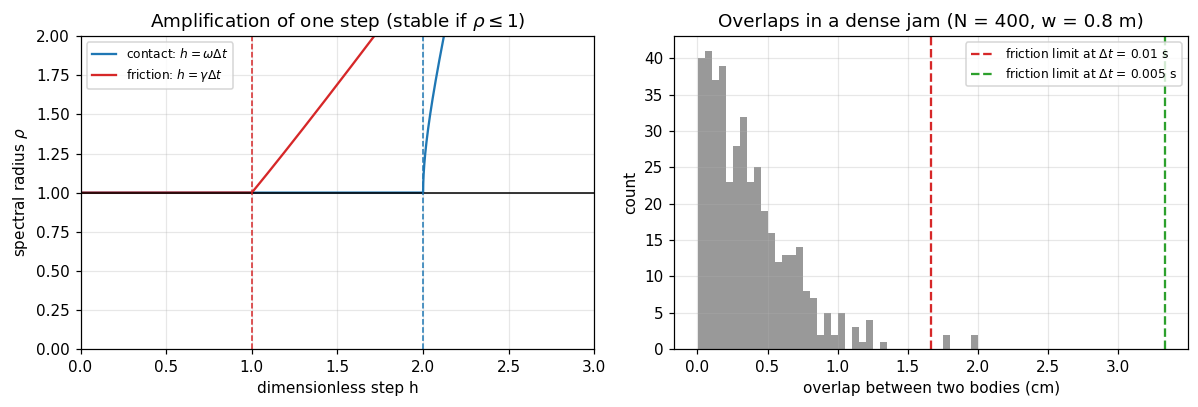

In [45]:
# V5: stability limits of the integrator, overlaps in a dense jam, and a too-large step failing.
def amplification_matrix(omega2, gamma, dt):
    """One step of the Section 2.7 scheme on x'' = -omega2 x - gamma v, as a matrix acting on (x, v, a)."""
    cols = []
    for x, v, a in np.eye(3):
        x1 = x + v * dt + 0.5 * a * dt * dt
        v_pred = v + a * dt
        a1 = -omega2 * x1 - gamma * v_pred
        cols.append([x1, v + 0.5 * (a + a1) * dt, a1])
    return np.array(cols).T


def spectral_radius(omega2, gamma, dt):
    return np.abs(np.linalg.eigvals(amplification_matrix(omega2, gamma, dt))).max()


def first_unstable(rho_of_h, h=np.linspace(1e-3, 3, 30_000)):
    """Smallest dimensionless step h at which the spectral radius exceeds 1."""
    rho = np.array([rho_of_h(x) for x in h])
    return h[np.argmax(rho > 1 + 1e-9)], h, rho


h_osc, _h1, rho_osc = first_unstable(lambda h: spectral_radius(1.0, 0.0, h))    # omega = 1, h = omega dt
h_fric, _h2, rho_fric = first_unstable(lambda h: spectral_radius(0.0, 1.0, h))  # gamma = 1, h = gamma dt
assert abs(h_osc - 2.0) < 1e-3 and abs(h_fric - 1.0) < 1e-3, "stability limits differ from the analysis"
OMEGA = np.sqrt(2 * (K_BODY + A_REP / B_REP) / MASS)
DT_CONTACT = 2.0 / OMEGA
print(f"Stability limits of the scheme: omega dt <= {h_osc:.3f} (contact), gamma dt <= {h_fric:.3f} (friction)")
print(f"   contact: omega = sqrt(2 (k + A/B) / m) = {OMEGA:.1f} rad/s  ->  dt < {DT_CONTACT:.4f} s")


# Overlaps in a dense jam (N = 400, w = 0.8 m), from positions saved every 0.5 s at the production step.
def pair_overlaps(pos, r):
    inside = np.isfinite(pos[:, 0])
    p, rr = pos[inside], r[inside]
    d = np.hypot(*(p[:, None] - p[None]).transpose(2, 0, 1))
    s = (rr[:, None] + rr[None]) - d
    s = s[np.triu_indices(len(p), 1)]
    return s[s > 0]


_res = run_evacuation(400, 0.8, REPLICATION_SEEDS[0], t_max=200.0, snap_times=tuple(np.arange(0.0, 200.0, 0.5)))
v5_overlaps = np.concatenate([pair_overlaps(p, _res.r) for p in _res.snaps])
S_99, S_MAX = np.percentile(v5_overlaps, 99), v5_overlaps.max()
DT_FRICTION, DT_FRICTION_WORST = MASS / (2 * KAPPA * S_99), MASS / (2 * KAPPA * S_MAX)
print(f"   friction: overlaps in the dense run ({len(v5_overlaps)} overlapping pairs seen): 99th percentile "
      f"{100 * S_99:.2f} cm -> dt < {DT_FRICTION:.4f} s; deepest {100 * S_MAX:.2f} cm -> dt < {DT_FRICTION_WORST:.4f} s")
assert DT < DT_CONTACT and DT < DT_FRICTION, "production step violates a stability limit"
print(f"   production dt = {DT} s: margin x{DT_CONTACT / DT:.1f} (contact), x{DT_FRICTION / DT:.2f} (friction, 99 % of "
      f"contacts), x{DT_FRICTION_WORST / DT:.2f} (deepest contact). The first-draft dt = 0.01 s exceeds the friction "
      f"limit for the deepest {100 * (v5_overlaps > MASS / (2 * KAPPA * 0.01)).mean():.1f} % of contacts.")

# Demonstration: the densest case at increasing dt. simulate() raises an error the moment a check fails.
V5_DTS = (0.1, 0.05, 0.02, 0.01, DT)
v5_outcome = {}
for _dt in V5_DTS:
    try:
        run_evacuation(400, 0.6, REPLICATION_SEEDS[0], dt=_dt, t_max=120.0)
        v5_outcome[_dt] = "stable"
    except (AssertionError, FloatingPointError) as err:
        v5_outcome[_dt] = f"FAILS: {err}"
    print(f"   N = 400, w = 0.6 m, dt = {_dt:<6g} s: {v5_outcome[_dt]}")
assert all(v5_outcome[d] != "stable" for d in V5_DTS if d > DT), "a too-large step should fail"
assert v5_outcome[DT] == "stable", "the production step must be stable"
print(f"V5 PASS: steps of 0.01 s and above fail in the dense case; dt = {DT} s is stable")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(_h1, rho_osc, color="tab:blue", label=r"contact: $h = \omega\Delta t$")
axes[0].plot(_h2, rho_fric, color="tab:red", label=r"friction: $h = \gamma\Delta t$")
axes[0].axhline(1, color="k", lw=1)
for _hc, _c in [(h_osc, "tab:blue"), (h_fric, "tab:red")]:
    axes[0].axvline(_hc, color=_c, ls="--", lw=1)
axes[0].set(xlabel="dimensionless step h", ylabel=r"spectral radius $\rho$", ylim=(0, 2), xlim=(0, 3),
            title="Amplification of one step (stable if $\\rho \\leq 1$)")
axes[0].legend(fontsize=8)
axes[1].hist(100 * v5_overlaps, bins=40, color="0.6")
for _dt, _c in [(0.01, "tab:red"), (DT, "tab:green")]:
    axes[1].axvline(100 * MASS / (2 * KAPPA * _dt), color=_c, ls="--",
                    label=fr"friction limit at $\Delta t$ = {_dt:g} s")
axes[1].set(xlabel="overlap between two bodies (cm)", ylabel="count",
            title="Overlaps in a dense jam (N = 400, w = 0.8 m)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "stability_timestep.png", dpi=150, bbox_inches="tight")
plt.show()

### V6: plausibility of the exit flow

Through a bottleneck, the **specific flow** $J_s$ (persons per metre of width per second) is the quantity that has been measured experimentally. In each run it is computed over the steady discharge phase, between 20 % and 80 % of the crowd evacuated:

$$
J_s = \frac{N_{80\%} - N_{20\%}}{(t_{80\%} - t_{20\%})\cdot 2w},
$$

since both exits are open and equally loaded. Runs use $N = 400$ (so a queue forms at both exits) and the widths of the laboratory experiment of Seyfried et al. [7], $w$ = 0.8–1.2 m, with 3 seeds each. These runs are reused in the pilot sweep (Section 5.2).

**Reference values.**
- In [7], groups of 20–60 people started from a holding area at 3.3 m⁻² and passed bottlenecks of 0.8–1.2 m at $J_s$ = 1.61–2.31 m⁻¹ s⁻¹ (Table 2 of [7]).
- In [8], every measured specific flow, for widths of 0.4–1.6 m, was above 1.33 m⁻¹ s⁻¹.
- The SFPE handbook's design capacity, as tabulated in [7], corresponds to $J_s = 1.3$ m⁻¹ s⁻¹.

**Pass criterion.** The mean simulated $J_s$ lies within [1.3, 2.31] m⁻¹ s⁻¹: from the design value up to the largest measured value. This is checked for $w \ge 1.0$ m. Below 1.0 m the model is expected to fall short: the walls at the two door edges repel with $A = 2000$ N, more than the 214 N driving force of a person walking at 1.34 m/s ($m v^0/\tau$). This effectively narrows the doorway by about 0.2 m on each side, and slow people can stop short of the gap altogether (Section 5.2). That result is printed and discussed rather than hidden. The sensitivity study (Section 5.7) later shows that a weaker repulsion does **not** raise the flow: the friction and compression terms matter as much as $A$.

Specific flow J_s (1/(m s)), N = 400, 3 seeds per width:
       mean   min   max experiment [7]  in band
w (m)                                          
0.8    1.20  1.15  1.23      1.61-1.86    False
0.9    1.19  1.16  1.22      1.86-2.06    False
1.0    1.34  1.32  1.36      1.90-2.19     True
1.1    1.45  1.42  1.47      1.78-1.93     True
1.2    1.60  1.58  1.64      1.81-2.31     True
V6 PASS for w >= 1.0 m: mean J_s = 1.34-1.60, inside [1.3, 2.31].
     Below 1.0 m the model under-predicts: w = 0.8, 0.9 m gives J_s = 1.20, 1.19, below the design value 1.3 and the experiments (1.61+). Narrow-exit results are therefore conservative.


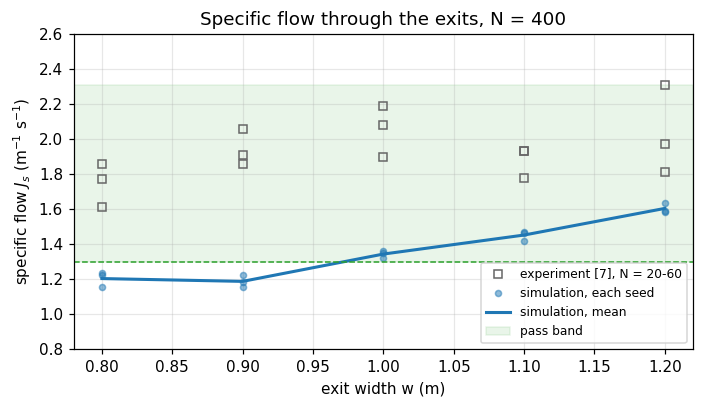

In [46]:
# V6: specific flow J_s in the steady discharge phase vs bottleneck experiments [7], [8].
JS_DESIGN, JS_MEAS_MAX = 1.3, 2.31            # SFPE design value (as tabulated in [7]); largest value in [7], Table 2
SEYFRIED_JS = {0.8: (1.61, 1.77, 1.86), 0.9: (1.86, 1.91, 2.06), 1.0: (1.90, 2.08, 2.19),   # [7], Table 2:
               1.1: (1.93, 1.93, 1.78), 1.2: (1.97, 1.81, 2.31)}                            # dN = 60, 40, 20
V6_N, V6_SEEDS = 400, REPLICATION_SEEDS[:3]


def specific_flow(res, lo=0.2, hi=0.8):
    """J_s (1/(m s)) between lo and hi of the crowd evacuated, over both exits; NaN if hi was not reached."""
    t = np.sort(res.exit_time[np.isfinite(res.exit_time)])
    i0, i1 = int(np.ceil(lo * res.n)), int(np.ceil(hi * res.n))
    if len(t) < i1:
        return np.nan
    n_exits = 2 - len(res.blocked)
    return (i1 - i0) / ((t[i1 - 1] - t[i0 - 1]) * n_exits * res.w)


v6 = pd.DataFrame([{"w (m)": w, "seed": s, "J_s": specific_flow(run_cached(V6_N, w, s))}
                   for w in SEYFRIED_JS for s in V6_SEEDS])
v6_summary = v6.groupby("w (m)")["J_s"].agg(["mean", "min", "max"])
v6_summary["experiment [7]"] = [f"{min(v):.2f}-{max(v):.2f}" for v in SEYFRIED_JS.values()]
v6_summary["in band"] = v6_summary["mean"].between(JS_DESIGN, JS_MEAS_MAX)
print(f"Specific flow J_s (1/(m s)), N = {V6_N}, {len(V6_SEEDS)} seeds per width:")
print(v6_summary.round(2).to_string())
_checked = v6_summary.loc[v6_summary.index >= 1.0]
assert _checked["in band"].all(), "V6 failed: simulated specific flow outside the published band for w >= 1.0 m"
print(f"V6 PASS for w >= 1.0 m: mean J_s = {_checked['mean'].min():.2f}-{_checked['mean'].max():.2f}, inside "
      f"[{JS_DESIGN}, {JS_MEAS_MAX}].")
_below = v6_summary.loc[(v6_summary.index < 1.0) & ~v6_summary["in band"]]
if len(_below):
    print(f"     Below 1.0 m the model under-predicts: w = {', '.join(f'{w:g}' for w in _below.index)} m gives "
          f"J_s = {', '.join(f'{j:.2f}' for j in _below['mean'])}, below the design value {JS_DESIGN} and the "
          f"experiments ({min(min(v) for v in SEYFRIED_JS.values()):.2f}+). Narrow-exit results are therefore conservative.")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for w, vals in SEYFRIED_JS.items():
    ax.plot([w] * 3, vals, "s", color="0.4", ms=5, mfc="none", label="experiment [7], N = 20-60" if w == 0.8 else None)
ax.plot(v6["w (m)"], v6["J_s"], "o", color="tab:blue", alpha=0.5, ms=4, label="simulation, each seed")
ax.plot(v6_summary.index, v6_summary["mean"], "-", color="tab:blue", lw=2, label="simulation, mean")
ax.axhspan(JS_DESIGN, JS_MEAS_MAX, color="tab:green", alpha=0.1, label="pass band")
ax.axhline(JS_DESIGN, color="tab:green", ls="--", lw=1)
ax.set(xlabel="exit width w (m)", ylabel=r"specific flow $J_s$ (m$^{-1}$ s$^{-1}$)", ylim=(0.8, 2.6),
       title=f"Specific flow through the exits, N = {V6_N}")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "flow_plausibility.png", dpi=150, bbox_inches="tight")
plt.show()

### Error scaling on log–log axes

Two errors in this study should shrink at known rates:

1. **Discretisation error** of the integrator. On the V1 test, the maximum speed error should fall like $\Delta t^2$ for Velocity-Verlet with the predictor and like $\Delta t$ for explicit Euler. Pass: fitted slopes in [1.8, 2.2] and [0.8, 1.2]. The measured errors should also lie on the predicted line $v_0(\Delta t/\tau)^2 \cdot 5/(12e)$ from V1.
2. **Monte Carlo error** of a mean over $R$ replications. Its standard error should fall like $R^{-1/2}$ (law of large numbers / central limit theorem). It is measured directly: 120 independent runs ($N = 100$, $w = 1.5$ m, seeds 5000–5119) are split into $120/R$ batches of $R$ runs, and the standard deviation of the batch means is plotted against $R$. Pass: fitted slope in [−0.7, −0.3]. The tolerance is wide because the largest batches have only six means each.

Integrator: fitted slope 2.000 (Velocity-Verlet + predictor), 1.011 (explicit Euler); measured / predicted error = [0.999 0.999 1.    1.    1.   ]
Monte Carlo: s.d. of one run = 2.01 s; s.d. of batch means falls with slope -0.50 (expected -0.5)
X2 PASS: integrator error ~ dt^2, Monte Carlo error ~ R^(-1/2)


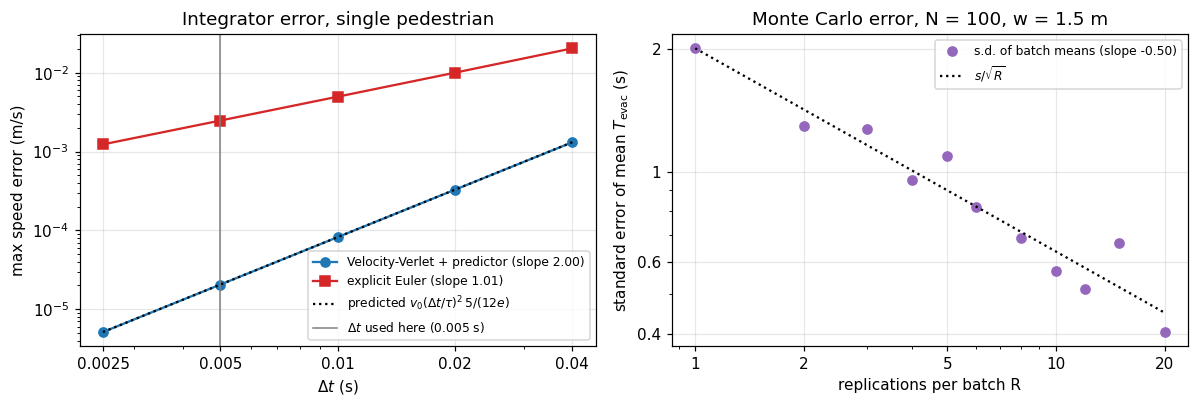

In [47]:
# Error scaling: (1) integrator error vs dt on the V1 test; (2) Monte Carlo standard error vs R.
X2_DTS = np.array([0.04, 0.02, 0.01, 0.005, 0.0025])
_e_vv, _e_eu = [], []
for _dt in X2_DTS:
    _t, _s, _ = relaxation_run(_dt)
    _ex = relaxation_exact(_t)[0]
    _e_vv.append(np.abs(_s - _ex).max())
    _t, _s, _ = relaxation_run(_dt, scheme="euler")
    _e_eu.append(np.abs(_s - _ex).max())
_e_vv, _e_eu = np.array(_e_vv), np.array(_e_eu)
slope_vv = np.polyfit(np.log(X2_DTS), np.log(_e_vv), 1)[0]
slope_eu = np.polyfit(np.log(X2_DTS), np.log(_e_eu), 1)[0]
_pred = V1_V0 * (X2_DTS / TAU) ** 2 * 5 / (12 * np.e)
assert 1.8 <= slope_vv <= 2.2, f"integrator order {slope_vv:.2f} is not 2"
assert 0.8 <= slope_eu <= 1.2, f"Euler order {slope_eu:.2f} is not 1"
print(f"Integrator: fitted slope {slope_vv:.3f} (Velocity-Verlet + predictor), {slope_eu:.3f} (explicit Euler); "
      f"measured / predicted error = {np.round(_e_vv / _pred, 3)}")

# Monte Carlo: 120 independent runs, split into batches of R.
X2_SEEDS = [5000 + k for k in range(120)]
x2_T = np.array([run_evacuation(100, 1.5, s).t_evac for s in X2_SEEDS])
X2_RS = np.array([1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20])
_sd_batch = np.array([x2_T.reshape(-1, R).mean(axis=1).std(ddof=1) for R in X2_RS])
slope_mc = np.polyfit(np.log(X2_RS), np.log(_sd_batch), 1)[0]
assert -0.7 <= slope_mc <= -0.3, f"Monte Carlo error slope {slope_mc:.2f} is not about -1/2"
print(f"Monte Carlo: s.d. of one run = {x2_T.std(ddof=1):.2f} s; s.d. of batch means falls with slope {slope_mc:.2f} "
      f"(expected -0.5)")
print("X2 PASS: integrator error ~ dt^2, Monte Carlo error ~ R^(-1/2)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].loglog(X2_DTS, _e_vv, "o-", color="tab:blue", label=f"Velocity-Verlet + predictor (slope {slope_vv:.2f})")
axes[0].loglog(X2_DTS, _e_eu, "s-", color="tab:red", label=f"explicit Euler (slope {slope_eu:.2f})")
axes[0].loglog(X2_DTS, _pred, "k:", label=r"predicted $v_0(\Delta t/\tau)^2\,5/(12e)$")
axes[0].axvline(DT, color="0.5", lw=1, label=rf"$\Delta t$ used here ({DT} s)")
axes[0].set(xlabel=r"$\Delta t$ (s)", ylabel="max speed error (m/s)", title="Integrator error, single pedestrian")
axes[0].legend(fontsize=8)
axes[1].loglog(X2_RS, _sd_batch, "o", color="tab:purple", label=f"s.d. of batch means (slope {slope_mc:.2f})")
axes[1].loglog(X2_RS, x2_T.std(ddof=1) / np.sqrt(X2_RS), "k:", label=r"$s/\sqrt{R}$")
axes[1].set(xlabel="replications per batch R", ylabel=r"standard error of mean $T_\mathrm{evac}$ (s)",
            title="Monte Carlo error, N = 100, w = 1.5 m")
axes[1].legend(fontsize=8)
# Readable ticks: label only the values used, in plain numbers, and hide the crowded minor-tick labels.
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
for _ax, _xt, _xl, _yt, _yl in [
        (axes[0], X2_DTS, [f"{d:g}" for d in X2_DTS], None, None),
        (axes[1], [1, 2, 5, 10, 20], ["1", "2", "5", "10", "20"], [0.4, 0.6, 1, 2], ["0.4", "0.6", "1", "2"])]:
    _ax.xaxis.set_major_locator(FixedLocator(_xt))
    _ax.xaxis.set_major_formatter(FixedFormatter(_xl))
    _ax.xaxis.set_minor_formatter(NullFormatter())
    if _yt is not None:
        _ax.yaxis.set_major_locator(FixedLocator(_yt))
        _ax.yaxis.set_major_formatter(FixedFormatter(_yl))
        _ax.yaxis.set_minor_formatter(NullFormatter())
fig.tight_layout()
fig.savefig(FIG_DIR / "convergence_loglog.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Experiments and results

### 5.1 First result: 100 people, two 1.5 m exits

This is a first run of the full model, before the exit-width sweep: 100 people start at random positions and evacuate through two exits of $w = 1.5$ m, with $R = 10$ replications. Snapshots are taken at 0, 10 and 20 s, because a 100-person run clears in about 40 s. The pilot sweep over $N$ and $w$ follows in Section 5.2.

In [48]:
# 5.1 First result: N = 100 people, two exits of w = 1.5 m, R = 10 replications (seeds listed above).
MVP_N, MVP_W, MVP_R = 100, 1.5, 10
SNAP_TIMES = (0.0, 10.0, 20.0)
mvp_runs = [run_evacuation(MVP_N, MVP_W, s, snap_times=SNAP_TIMES) for s in REPLICATION_SEEDS[:MVP_R]]
mvp = pd.DataFrame([{"seed": r.seed, "T_evac (s)": r.t_evac, "T_90 (s)": r.t_90, "out west": r.n_west,
                     "out east": r.n_east, "peak density (1/m^2)": r.density_rec.max(), "cleared": r.cleared}
                    for r in mvp_runs])
assert mvp["cleared"].all(), "every MVP run should clear well before T_max"
print(mvp.round(2).to_string(index=False))
_m, _h = mean_ci(mvp["T_evac (s)"])
_m90, _h90 = mean_ci(mvp["T_90 (s)"])
print(f"\nN = {MVP_N}, w = {MVP_W} m, R = {MVP_R}: T_evac = {_m:.1f} +- {_h:.1f} s, "
      f"T_90 = {_m90:.1f} +- {_h90:.1f} s (mean +- 95 % CI); target {T_TARGET:.0f} s")

 seed  T_evac (s)  T_90 (s)  out west  out east  peak density (1/m^2)  cleared
 1000       39.23     29.00        46        54                  1.91     True
 1001       37.93     28.30        46        54                  2.07     True
 1002       38.93     29.50        57        43                  1.91     True
 1003       38.98     29.86        56        44                  1.75     True
 1004       41.82     30.97        46        54                  1.91     True
 1005       39.34     31.06        51        49                  1.91     True
 1006       41.54     30.86        45        55                  1.91     True
 1007       38.94     30.12        54        46                  1.91     True
 1008       36.54     28.93        55        45                  1.91     True
 1009       36.70     29.12        50        50                  1.91     True

N = 100, w = 1.5 m, R = 10: T_evac = 39.0 +- 1.2 s, T_90 = 29.8 +- 0.7 s (mean +- 95 % CI); target 180 s


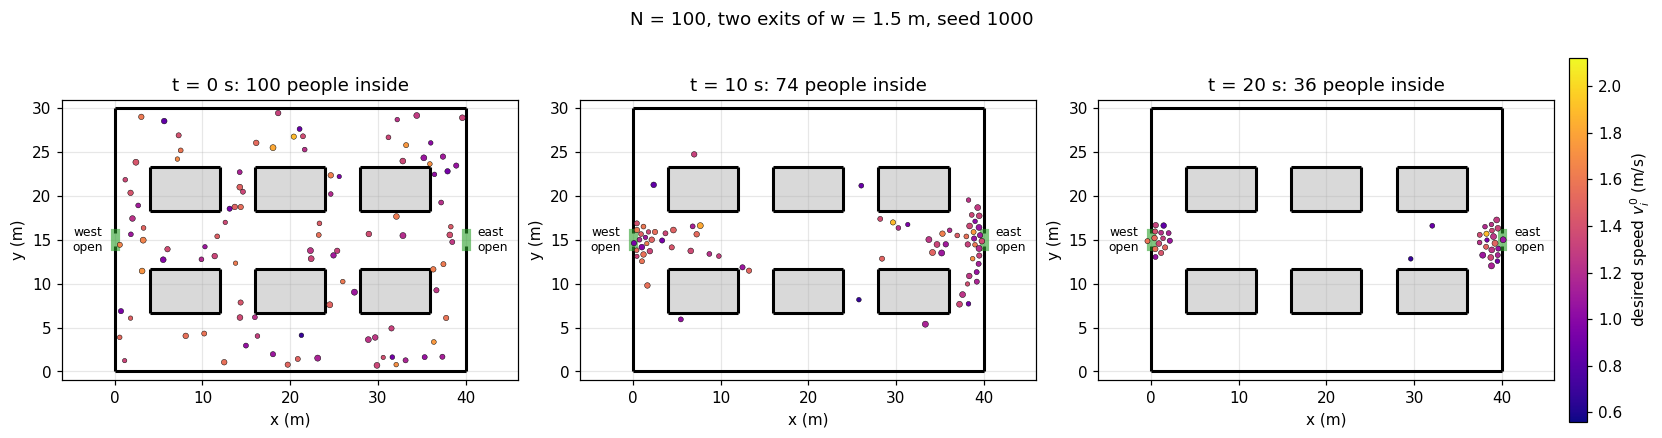

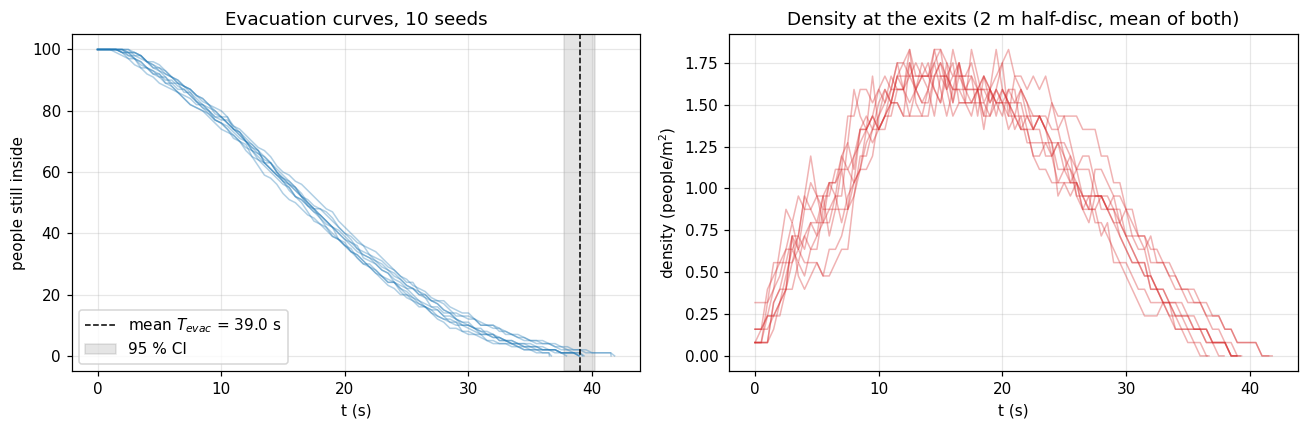

In [49]:
# Figures: crowd snapshots for the first seed, and the evacuation curves of all seeds.
from matplotlib.collections import EllipseCollection

_run = mvp_runs[0]
fig, axes = plt.subplots(1, len(SNAP_TIMES), figsize=(15, 4.0), layout="constrained")
for ax, t, pos in zip(axes, _run.snap_times, _run.snaps):
    plot_mall(get_mall(MVP_W)[0], ax=ax, title=f"t = {t:g} s: {np.isfinite(pos[:, 0]).sum()} people inside")
    inside = np.isfinite(pos[:, 0])
    discs = EllipseCollection(2 * _run.r[inside], 2 * _run.r[inside], 0, units="xy", offsets=pos[inside],
                              offset_transform=ax.transData, array=_run.v0[inside], cmap="plasma",
                              clim=(V0_MEAN - 3 * V0_SD, V0_MEAN + 3 * V0_SD), zorder=5, edgecolor="k", lw=0.3)
    ax.add_collection(discs)
fig.colorbar(discs, ax=axes, shrink=0.9, pad=0.01, label="desired speed $v_i^0$ (m/s)")
fig.suptitle(f"N = {MVP_N}, two exits of w = {MVP_W} m, seed {_run.seed}")
fig.savefig(FIG_DIR / "mvp_snapshots.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in mvp_runs:
    axes[0].plot(r.t_rec, MVP_N - r.n_out_rec.sum(axis=1), color="tab:blue", alpha=0.35, lw=1)
    axes[1].plot(r.t_rec, r.density_rec.mean(axis=1), color="tab:red", alpha=0.35, lw=1)
axes[0].axvline(_m, color="k", ls="--", lw=1, label=f"mean $T_{{evac}}$ = {_m:.1f} s")
axes[0].axvspan(_m - _h, _m + _h, color="k", alpha=0.1, label="95 % CI")
axes[0].set(xlabel="t (s)", ylabel="people still inside", title=f"Evacuation curves, {MVP_R} seeds")
axes[0].legend()
axes[1].set(xlabel="t (s)", ylabel="density (people/m$^2$)",
            title=f"Density at the exits ({DENSITY_RADIUS:g} m half-disc, mean of both)")
fig.tight_layout()
fig.savefig(FIG_DIR / "mvp_evacuation_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Pilot sweep: where does the 180 s threshold fall?

Before the main sweep, a pilot with 3 seeds per case locates the widths at which $T_\text{evac}$ crosses the 180 s target, for the smallest and largest crowds ($N$ = 100 and 400). Its only job is to choose the width grid for the main study. The 180 s target is fixed and is not adjusted to suit the results.

- Widths: 0.6, 0.8, 0.9, 1.0, 1.1, 1.2, 1.5, 2.0 and 3.0 m.
- The 0.6 m case is run only for $N = 100$: it already jams permanently there, and a larger crowd cannot clear a door that a smaller one cannot.
- A run that has not cleared by $T_\text{max} = 600$ s is reported as "not cleared". For those runs, the cell also lists how many people are still inside, and their mean desired speed and radius compared with the whole crowd.

Pilot sweep, 3 seeds per case (T in s; NaN = not cleared by T_max = 600 s):
           T_evac_mean  T_evac_max  T_90_mean  cleared  left_at_T_max  v0_left  r_left  compute_s  meets 180 s (all seeds)
N   w (m)                                                                                                                 
100 0.6            NaN         NaN        NaN        0          95.33     1.33    0.30       8.30                    False
    0.8            NaN         NaN      85.72        0           5.67     1.02    0.32       1.77                    False
    0.9            NaN         NaN      70.21        0           1.00     0.92    0.33       1.05                    False
    1.0          72.20       77.89      52.04        3           0.00      NaN     NaN       0.36                     True
    1.1          64.90       67.40      46.34        3           0.00      NaN     NaN       0.33                     True
    1.2          54.74       56.36      39.76        3         

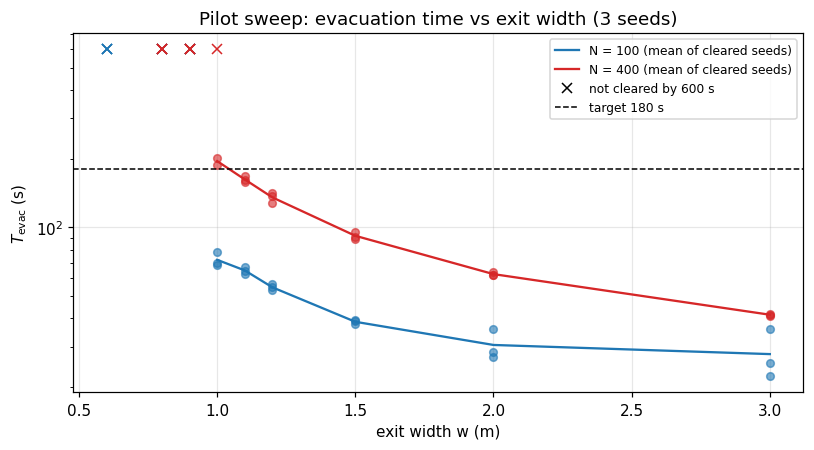

In [50]:
# 5.2 Pilot sweep: N in {100, 400}, 9 widths, 3 seeds (the N = 400 runs at 0.8-1.2 m are reused from V6).
PILOT_SEEDS = REPLICATION_SEEDS[:3]
PILOT_WIDTHS = (0.6, 0.8, 0.9, 1.0, 1.1, 1.2, 1.5, 2.0, 3.0)
PILOT_CASES = [(n, w) for n in (100, 400) for w in PILOT_WIDTHS if not (n == 400 and w < 0.8)]
_rows = []
for n, w in PILOT_CASES:
    for s in PILOT_SEEDS:
        res = run_cached(n, w, s)
        stuck = ~np.isfinite(res.exit_time)
        _rows.append({"N": n, "w (m)": w, "seed": s, "T_evac": res.t_evac, "T_90": res.t_90, "cleared": res.cleared,
                      "left at T_max": int(stuck.sum()), "v0 of those left": res.v0[stuck].mean() if stuck.any() else np.nan,
                      "r of those left": res.r[stuck].mean() if stuck.any() else np.nan, "wall_s": res.wall_s})
pilot = pd.DataFrame(_rows)
pilot_summary = pilot.groupby(["N", "w (m)"]).agg(
    T_evac_mean=("T_evac", "mean"), T_evac_max=("T_evac", "max"), T_90_mean=("T_90", "mean"),
    cleared=("cleared", "sum"), left_at_T_max=("left at T_max", "mean"), v0_left=("v0 of those left", "mean"),
    r_left=("r of those left", "mean"), compute_s=("wall_s", "mean"))
pilot_summary["meets 180 s (all seeds)"] = (pilot.assign(ok=pilot["T_evac"] <= T_TARGET)
                                            .groupby(["N", "w (m)"])["ok"].all())
print(f"Pilot sweep, {len(PILOT_SEEDS)} seeds per case (T in s; NaN = not cleared by T_max = {T_MAX:.0f} s):")
print(pilot_summary.round(2).to_string())

# Who is left behind when a run does not clear? (compare with the whole population: v0 mean 1.34 m/s, r mean 0.30 m)
_stuck = pilot.loc[~pilot["cleared"] & (pilot["left at T_max"] < 0.2 * pilot["N"])]
if len(_stuck):
    print(f"\nRuns that end with a few people stuck: mean v0 of those left = {_stuck['v0 of those left'].mean():.2f} m/s, "
          f"mean radius = {_stuck['r of those left'].mean():.3f} m (whole crowd: {V0_MEAN} m/s, {(R_MIN + R_MAX) / 2} m)")

# Cost per run at the production step, for choosing the number of replications in the main sweep.
print("\nMean compute time per run (s):")
print(pilot.groupby(["N", "w (m)"])["wall_s"].mean().unstack(0).round(2).T.to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for n, c in [(100, "tab:blue"), (400, "tab:red")]:
    d = pilot[pilot["N"] == n]
    ok = d["cleared"]
    ax.plot(d.loc[ok, "w (m)"], d.loc[ok, "T_evac"], "o", color=c, alpha=0.6, ms=5)
    ax.plot(d.loc[~ok, "w (m)"], np.full((~ok).sum(), T_MAX), "x", color=c, ms=7)
    m = d.groupby("w (m)")["T_evac"].mean()
    ax.plot(m.index, m.values, "-", color=c, label=f"N = {n} (mean of cleared seeds)")
ax.plot([], [], "kx", label=f"not cleared by {T_MAX:.0f} s")
ax.axhline(T_TARGET, color="k", ls="--", lw=1, label=f"target {T_TARGET:.0f} s")
ax.set(xlabel="exit width w (m)", ylabel=r"$T_\mathrm{evac}$ (s)", yscale="log",
       title="Pilot sweep: evacuation time vs exit width (3 seeds)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

**Pilot findings.**

1. **Narrow exits do not clear at all.** With $w \le 0.9$ m, no run clears by 600 s, for either crowd size. Most people get out ($T_{90}$ is reached), but the last few stop in front of the door and never pass. Those left behind are the slowest and largest people: mean $v^0 \approx 0.9$ m/s against 1.34 m/s for the whole crowd. This is the door-edge effect noted in V6. Once nobody is pushing from behind, a slow person's driving force $m v^0/\tau$ cannot beat the 2000 N repulsion of the two door edges. At 0.6 m even a crowd of 100 jams permanently.
2. **$N = 100$:** every width that clears, $w \ge 1.0$ m, clears well inside 180 s (76 s at 1.0 m). The required width at $N = 100$ is therefore set by **passability** (about 0.95–1.0 m), not by the time target.
3. **$N = 400$:** the 180 s threshold falls between 1.0 m (mean 195 s, 2 of 3 seeds cleared) and 1.1 m (160 s).
4. **Consequence for the question:** between $N = 100$ and $N = 400$ the required width only moves from about 1.0 m to about 1.05 m. The time target starts to bind only near $N \approx 400$. Over the proposed occupancy range the exits are limited by passability, not capacity, so a fit of $w^* \propto N^{\alpha}$ there would say little about how width scales with occupancy.
5. **Cost:** at the production step a run takes 0.1–0.7 s ($N = 100$) and 0.7–6 s ($N = 400$; runs that never clear go on to 600 s).

**Decision.** The main study keeps the proposed range $N$ = 100–400 and **extends it to $N$ = 800**, so that it covers both regimes: passability-limited at low occupancy and capacity-limited at high occupancy. For each $N$, six widths bracket the crossing located by this pilot and by short pilot runs at $N$ = 200, 300, 600 and 800 (2 seeds each). Those runs found crossings near 1.0 m ($N$ = 200, 300), 1.2 m ($N$ = 600) and 1.4 m ($N$ = 800). $N$ = 500 and 700 were added later, so that the fit of $\alpha$ in the capacity-limited regime rests on four crowd sizes rather than two.

### 5.3 Main sweep: evacuation time against exit width for N = 100 … 800

The pilot showed that over the proposed range ($N \le 400$) the exits are limited by passability, not by the time target. The occupancy range is therefore **extended to $N$ = 800** (adding 500, 600, 700 and 800), so the study also covers the regime where capacity decides the width. The 180 s target is unchanged.

**Design.**
- $N \in \{100, 200, 300, 400, 500, 600, 700, 800\}$. For each $N$, six widths bracket the 180 s crossing found in the pilot, at a spacing of 0.05–0.1 m.
- $R = 20$ replications per case. Replication $k$ uses seed $1000 + k$ for every case (common random numbers).
- **Time step:** $\Delta t = 0.005$ s for $N \le 400$, which is what V4 and V5 verify. Larger crowds compress each other more, so the friction limit of V5 tightens: at $N = 600$–800 some runs at 0.005 s failed a per-step check. Every $N > 400$ therefore uses $\Delta t = 0.0025$ s. V4b shows the two steps give the same statistics to within 2.2 %, so the switch does not bias the comparison between crowd sizes beyond that.
- **Safety net:** any run that still fails a per-step check is repeated with the step halved. The step actually used is stored with every result, and every accepted run has passed every check.
- **Time limit:** runs stop at $T_\text{max} = 360$ s ($2\,T_\text{target}$). A run that has not cleared by then fails the target by a wide margin, and running it on to 600 s would only add cost.

**Cost and caching.** The full sweep is $8 \times 6 \times 20 = 960$ runs, about 3.5 h on one core. It is run in parallel once, with `QUICK_MODE = False`, and saved to `data/results_main.csv`. In `QUICK_MODE`, "Run all" loads that file: from the repository's `data/` folder when the notebook runs from a clone, otherwise from GitHub. As a reproducibility check, it then re-simulates three of the cached cases and compares them with the stored values. If the file cannot be found, the sweep is run here with 2 seeds per case (slow, about 8 min).

In [51]:
# 5.3 Main sweep: N = 100 ... 800 (8 sizes), six widths per N around the 180 s crossing, R = 20 seeds (cached in data/).
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

SWEEP_WIDTHS = {100: (0.85, 0.90, 0.95, 1.00, 1.05, 1.10),      # chosen from the pilot (Section 5.2):
                200: (0.90, 0.95, 1.00, 1.05, 1.10, 1.20),      # each set brackets the 180 s crossing
                300: (0.90, 0.95, 1.00, 1.05, 1.10, 1.20),
                400: (0.95, 1.00, 1.05, 1.10, 1.20, 1.30),
                500: (1.00, 1.05, 1.10, 1.15, 1.20, 1.30),
                600: (1.05, 1.10, 1.15, 1.20, 1.30, 1.40),
                700: (1.15, 1.20, 1.25, 1.30, 1.35, 1.40),
                800: (1.20, 1.30, 1.35, 1.40, 1.50, 1.60)}
R_SWEEP = 20 if not QUICK_MODE else 2           # used only when the sweep is (re)computed here
T_MAX_SWEEP = 2 * T_TARGET                      # 360 s
RESULTS_CSV = DATA_DIR / "results_main.csv"     # cached results (see the markdown above)
RESULTS_URL = "https://raw.githubusercontent.com/ChanuRasmika/mall-evacuation-social-force/main/data/results_main.csv"


def sweep_dt(n):
    """Production step for a crowd of n (Section 5.3): 0.005 s up to N = 400, 0.0025 s above."""
    return DT if n <= 400 else DT / 2


def run_checked(n, w, seed, t_max=T_MAX_SWEEP, max_halvings=2, **kw):
    """run_evacuation at sweep_dt(n); if a per-step check fails, repeat with the step halved.

    Extra keyword arguments (blocked, tau, v0_mean, a_rep) are passed on to run_evacuation.
    """
    dt = sweep_dt(n)
    for _ in range(max_halvings + 1):
        try:
            return run_evacuation(n, w, seed, dt=dt, t_max=t_max, **kw), dt
        except (AssertionError, FloatingPointError):
            dt /= 2
    raise RuntimeError(f"N = {n}, w = {w}, seed {seed}: fails the checks even at dt = {2 * dt:g} s")


def sweep_row(case):
    """One sweep run, reduced to a row of the results table."""
    n, w, seed = case
    res, dt_used = run_checked(n, w, seed)
    return {"N": n, "w": w, "seed": seed, "dt": dt_used, "T_evac": res.t_evac, "T_90": res.t_90,
            "cleared": res.cleared, "n_left": int((~np.isfinite(res.exit_time)).sum()),
            "J_s": specific_flow(res), "peak_density": res.density_rec.max(), "wall_s": res.wall_s}


def run_parallel(row_fn, cases, processes=None):
    """row_fn(case) for every case, in parallel where the platform can fork (Colab/Linux, macOS)."""
    t0 = time.perf_counter()
    try:
        with ProcessPoolExecutor(processes or mp.cpu_count(), mp_context=mp.get_context("fork")) as pool:
            rows = list(pool.map(row_fn, cases, chunksize=1))
    except (ValueError, OSError) as err:                    # no fork available (e.g. Windows): run serially
        print(f"parallel run unavailable ({err}); running serially")
        rows = [row_fn(c) for c in cases]
    print(f"{len(cases)} runs in {time.perf_counter() - t0:.0f} s of wall-clock time")
    return pd.DataFrame(rows)


def cached_results(name, compute):
    """Results table `name` (a CSV in data/): computed and saved when QUICK_MODE is False; otherwise loaded
    from data/ or, on Colab, from the GitHub copy. If neither exists, compute() runs here with fewer seeds."""
    path, url = DATA_DIR / name, RESULTS_URL.rsplit("/", 1)[0] + "/" + name
    if not QUICK_MODE:
        df = compute()
        df.to_csv(path, index=False)
        print(f"saved {path}")
        return df
    try:
        df = pd.read_csv(path if path.exists() else url)
        print(f"loaded {len(df)} cached runs from {path if path.exists() else url}")
        return df
    except Exception as err:
        print(f"no cached {name} ({err}); running here with reduced seeds")
        return compute()


def run_sweep(seeds):
    """Every (N, w, seed) case of the main sweep."""
    cases = [(n, w, s) for n, ws in SWEEP_WIDTHS.items() for w in ws for s in seeds]
    cases.sort(key=lambda c: -c[0] / c[1])                   # most expensive first, for load balance
    return run_parallel(sweep_row, cases).sort_values(["N", "w", "seed"]).reset_index(drop=True)


sweep = cached_results(RESULTS_CSV.name, lambda: run_sweep(REPLICATION_SEEDS[:R_SWEEP]))

# Checks on the table: every case complete, the step rule followed, every accepted run passed every check.
_counts = sweep.groupby(["N", "w"]).size()
assert len(_counts) == sum(len(ws) for ws in SWEEP_WIDTHS.values()) and _counts.nunique() == 1, "incomplete sweep"
assert (sweep["dt"] <= sweep["N"].map(sweep_dt) + 1e-12).all()
assert (sweep["cleared"] == sweep["T_evac"].notna()).all()
R_USED = int(_counts.iloc[0])
_halved = sweep[sweep["dt"] < sweep["N"].map(sweep_dt) - 1e-12]
print(f"{len(sweep)} runs: {len(_counts)} cases x R = {R_USED} seeds; {len(_halved)} run(s) needed a halved step"
      + (f" ({', '.join(f'N={r.N} w={r.w:g} seed {r.seed}' for r in _halved.itertuples())})" if len(_halved) else ""))

# Reproducibility: re-simulate three cached cases (identical code and seeds -> the same evacuation times; on a
# different CPU, rounding can differ and a chaotic crowd then gives a slightly different sample, hence 10 %).
_spot = sweep[(sweep["N"] == 100) & np.isclose(sweep["w"], 1.0)].head(3)
_again = np.array([sweep_row((100, 1.0, s))["T_evac"] for s in _spot["seed"]])
_exact = int(np.sum(_again == _spot["T_evac"].to_numpy()))
assert abs(_again.mean() / _spot["T_evac"].mean() - 1) < 0.10, "cached results do not reproduce"
print(f"Reproducibility: N = 100, w = 1.0 m, seeds {list(_spot['seed'])}: cached {list(_spot['T_evac'].round(2))} s, "
      f"re-simulated {[round(float(t), 2) for t in _again]} s ({_exact}/3 identical)")

loaded 960 cached runs from https://raw.githubusercontent.com/ChanuRasmika/mall-evacuation-social-force/main/data/results_main.csv
960 runs: 48 cases x R = 20 seeds; 0 run(s) needed a halved step
Reproducibility: N = 100, w = 1.0 m, seeds [1000, 1001, 1002]: cached [77.9, 76.06, 73.2] s, re-simulated [77.89, 70.03, 68.69] s (0/3 identical)


### 5.4 Required exit width and how it scales with occupancy

For each $N$, the required width $w^*(N)$ is the smallest width whose **upper** 95 % confidence limit of $T_\text{evac}$ is at most 180 s (Section 2.8). It is interpolated linearly between the two grid widths that bracket the crossing. Where the next narrower width did not clear in every replication, $w^*$ is limited by **passability** rather than by capacity. It is then reported as the grid width, with the true value within one grid step (0.05 m) below. The mean-based value (mean $T_\text{evac}$ = 180 s) is shown for comparison.

The uncertainty in $w^*$ and in the exponent $\alpha$ of $w^* \propto N^{\alpha}$ comes from a **bootstrap over seeds** with 1000 resamples. For each $N$ the 20 replications are resampled with replacement, keeping the same seeds across all widths of that $N$, and $w^*$ and $\alpha$ are recomputed. $\alpha$ is fitted twice: over all $N$, and over the capacity-limited $N$ only, which is where "how does the width scale with occupancy" is a question about flow.

bootstrap: 1000/1000 resamples have every w*(N) inside its width grid
Required width per exit (smallest w whose upper 95 % limit of T_evac is <= 180 s), R = 20:
  N  w* (upper CI)  w* (mean)  limited by  people per m of exit 95 % interval
100          1.050      1.050 passability                47.619   1.000-1.050
200          1.050      1.050 passability                95.238   1.050-1.050
300          1.050      1.050 passability               142.857   1.050-1.050
400          1.100      1.100 passability               181.818   1.053-1.100
500          1.153      1.146    capacity               216.907   1.146-1.157
600          1.239      1.230    capacity               242.091   1.230-1.246
700          1.330      1.320    capacity               263.071   1.320-1.338
800          1.435      1.424    capacity               278.840   1.425-1.442

Scaling w* ~ N^alpha:  all N (100-800): alpha = 0.14, bootstrap 95 % CI [0.14, 0.16]
                       capacity-limited N (500, 600

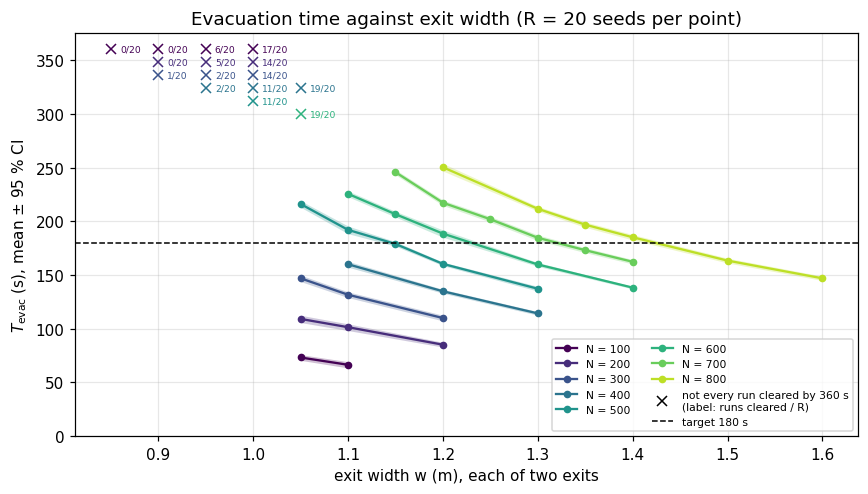

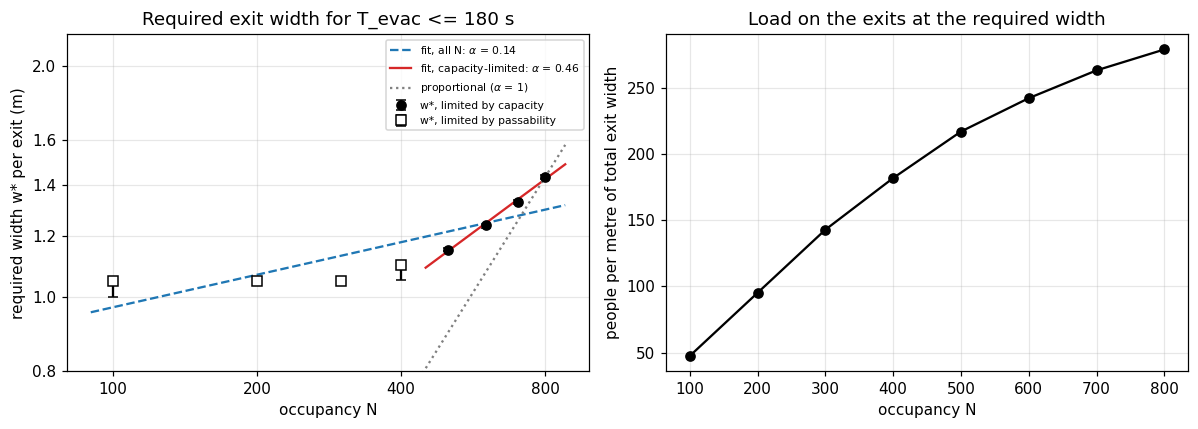

In [52]:
# 5.4 Required exit width w*(N) and the scaling exponent alpha (Section 2.8).
def summarise(df):
    """Per (N, w): mean T_evac +- 95 % CI (only if every replication cleared), T_90, J_s, peak density."""
    rows = []
    for (n, w), g in df.groupby(["N", "w"]):
        all_out = bool(g["cleared"].all())
        m, h = mean_ci(g["T_evac"]) if all_out else (np.nan, np.nan)
        rows.append({"N": n, "w": w, "cleared": f"{int(g['cleared'].sum())}/{len(g)}", "all_cleared": all_out,
                     "T_mean": m, "T_ci": h, "T_upper": m + h if all_out else np.inf,
                     "T90_mean": g["T_90"].mean(), "J_s": g["J_s"].mean(), "peak_density": g["peak_density"].mean()})
    return pd.DataFrame(rows)


def crossing_width(w, val):
    """Smallest width meeting the target, given widths w (ascending) and values val (inf = not all cleared).

    Every width at and above the answer must meet the target. If the next narrower width has a finite value,
    the crossing is interpolated linearly ("capacity"); if that width did not clear in every replication, the
    answer is the grid width itself and the limit is passability (the true value lies within one grid step below).
    """
    fails = np.nonzero(~(val <= T_TARGET))[0]
    k = 0 if len(fails) == 0 else fails[-1] + 1
    if k >= len(w):
        return np.nan, "above grid"
    if k == 0:
        return w[0], "below grid"
    if np.isfinite(val[k - 1]):
        return w[k - 1] + (T_TARGET - val[k - 1]) * (w[k] - w[k - 1]) / (val[k] - val[k - 1]), "capacity"
    return w[k], "passability"


def required_width(s_n, col="T_upper"):
    """crossing_width for one N, from that N's rows of summarise()."""
    s_n = s_n.sort_values("w")
    return crossing_width(s_n["w"].to_numpy(), s_n[col].replace(np.nan, np.inf).to_numpy())


def fit_alpha(ns, ws):
    """Least-squares slope and intercept of log w* = log c + alpha log N."""
    alpha, logc = np.polyfit(np.log(ns), np.log(ws), 1)
    return alpha, np.exp(logc)


summary = summarise(sweep)
wstar = []
for n, s_n in summary.groupby("N"):
    w_up, regime = required_width(s_n, "T_upper")
    w_mean, _ = required_width(s_n, "T_mean")
    wstar.append({"N": n, "w* (upper CI)": w_up, "w* (mean)": w_mean, "limited by": regime,
                  "people per m of exit": n / (2 * w_up)})
wstar = pd.DataFrame(wstar)
assert wstar["limited by"].isin(["capacity", "passability"]).all(), "a crossing lies outside its width grid"

# Bootstrap over seeds (B = 1000): resample the R replications of each N (the same seeds for every width of
# that N, preserving common random numbers), recompute w*(N) and alpha.
from scipy import stats
B, _boot_rng = 1000, np.random.default_rng(SEED + 5)
CAP_N = wstar.loc[wstar["limited by"] == "capacity", "N"].to_numpy()
_tq = stats.t.ppf(0.975, R_USED - 1)
_boot = {}
for n in wstar["N"]:
    tab = sweep[sweep["N"] == n].pivot(index="w", columns="seed", values="T_evac")   # widths x seeds (NaN = not cleared)
    T = tab.to_numpy()
    idx = _boot_rng.integers(0, T.shape[1], (B, T.shape[1]))
    Tb = T[:, idx]                                                                       # widths x B x R
    upper = Tb.mean(axis=2) + _tq * Tb.std(axis=2, ddof=1) / np.sqrt(R_USED)             # NaN if any not cleared
    _boot[n] = np.array([crossing_width(tab.index.to_numpy(), np.nan_to_num(upper[:, b], nan=np.inf))[0]
                         for b in range(B)])
_ok = np.all([np.isfinite(_boot[n]) for n in wstar["N"]], axis=0)       # resamples with every w* inside its grid
_alpha_all = [fit_alpha(wstar["N"], [_boot[n][b] for n in wstar["N"]])[0] for b in np.nonzero(_ok)[0]]
_alpha_cap = [fit_alpha(CAP_N, [_boot[n][b] for n in CAP_N])[0] for b in np.nonzero(_ok)[0]]
print(f"bootstrap: {_ok.sum()}/{B} resamples have every w*(N) inside its width grid")
wstar["95 % interval"] = [f"{np.nanpercentile(_boot[n], 2.5):.3f}-{np.nanpercentile(_boot[n], 97.5):.3f}" for n in wstar["N"]]

ALPHA_ALL, C_ALL = fit_alpha(wstar["N"], wstar["w* (upper CI)"])
ALPHA_CAP, C_CAP = fit_alpha(CAP_N, wstar.set_index("N").loc[CAP_N, "w* (upper CI)"])
ci = lambda a: f"[{np.percentile(a, 2.5):.2f}, {np.percentile(a, 97.5):.2f}]"
print(f"Required width per exit (smallest w whose upper 95 % limit of T_evac is <= {T_TARGET:.0f} s), R = {R_USED}:")
print(wstar.round(3).to_string(index=False))
print(f"\nScaling w* ~ N^alpha:  all N (100-800): alpha = {ALPHA_ALL:.2f}, bootstrap 95 % CI {ci(_alpha_all)}")
print(f"                       capacity-limited N ({', '.join(map(str, CAP_N))}): alpha = {ALPHA_CAP:.2f}, "
      f"bootstrap 95 % CI {ci(_alpha_cap)}")

# Figure 1: T_evac against w, one curve per N.
_colors = dict(zip(SWEEP_WIDTHS, plt.cm.viridis(np.linspace(0, 0.9, len(SWEEP_WIDTHS)))))
fig, ax = plt.subplots(figsize=(8, 4.6))
for n, s_n in summary.groupby("N"):
    ok = s_n["all_cleared"]
    ax.plot(s_n.loc[ok, "w"], s_n.loc[ok, "T_mean"], "o-", color=_colors[n], ms=4, label=f"N = {n}")
    ax.fill_between(s_n.loc[ok, "w"], s_n.loc[ok, "T_mean"] - s_n.loc[ok, "T_ci"],
                    s_n.loc[ok, "T_mean"] + s_n.loc[ok, "T_ci"], color=_colors[n], alpha=0.25, lw=0)
    _y = T_MAX_SWEEP - 12 * list(SWEEP_WIDTHS).index(n)       # one row per N, so the markers do not overlap
    for r in s_n.loc[~ok].itertuples():
        ax.plot(r.w, _y, "x", color=_colors[n], ms=6)
        ax.annotate(r.cleared, (r.w, _y), xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=6, color=_colors[n])
ax.plot([], [], "kx", label=f"not every run cleared by {T_MAX_SWEEP:.0f} s\n(label: runs cleared / R)")
ax.axhline(T_TARGET, color="k", ls="--", lw=1, label=f"target {T_TARGET:.0f} s")
ax.set(xlabel="exit width w (m), each of two exits", ylabel=r"$T_\mathrm{evac}$ (s), mean $\pm$ 95 % CI",
       ylim=(0, T_MAX_SWEEP + 15), title=f"Evacuation time against exit width (R = {R_USED} seeds per point)")
ax.legend(fontsize=7, ncol=2, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "evac_time_vs_width.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: w*(N) on log-log axes with the fitted power laws, and people per metre of exit width.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
_lo = [w - np.nanpercentile(_boot[n], 2.5) for n, w in zip(wstar["N"], wstar["w* (upper CI)"])]
_hi = [np.nanpercentile(_boot[n], 97.5) - w for n, w in zip(wstar["N"], wstar["w* (upper CI)"])]
for regime, mk in [("capacity", "o"), ("passability", "s")]:
    m = wstar["limited by"] == regime
    axes[0].errorbar(wstar.loc[m, "N"], wstar.loc[m, "w* (upper CI)"],
                     yerr=[np.array(_lo)[m], np.array(_hi)[m]], fmt=mk, color="k",
                     mfc="k" if regime == "capacity" else "white", capsize=3, label=f"w*, limited by {regime}")
_n = np.linspace(90, 880, 100)
axes[0].plot(_n, C_ALL * _n ** ALPHA_ALL, "--", color="tab:blue", label=fr"fit, all N: $\alpha$ = {ALPHA_ALL:.2f}")
_nc = np.linspace(CAP_N.min() * 0.9, CAP_N.max() * 1.1, 50)
axes[0].plot(_nc, C_CAP * _nc ** ALPHA_CAP, "-", color="tab:red", label=fr"fit, capacity-limited: $\alpha$ = {ALPHA_CAP:.2f}")
_w8 = wstar.set_index("N").loc[CAP_N.max(), "w* (upper CI)"]
axes[0].plot(_n, _w8 * (_n / CAP_N.max()), ":", color="0.5", label=r"proportional ($\alpha$ = 1)")
axes[0].set(xscale="log", yscale="log", xlabel="occupancy N", ylabel="required width w* per exit (m)",
            title=f"Required exit width for T_evac <= {T_TARGET:.0f} s")
axes[0].set_xticks([100, 200, 400, 800], ["100", "200", "400", "800"])
axes[0].set_yticks([0.8, 1.0, 1.2, 1.4, 1.6, 2.0], ["0.8", "1.0", "1.2", "1.4", "1.6", "2.0"])
axes[0].set_xticks([], minor=True)
axes[0].set_yticks([], minor=True)
axes[0].set_ylim(0.8, 2.2)
axes[0].legend(fontsize=7)
axes[1].plot(wstar["N"], wstar["people per m of exit"], "o-", color="k")
axes[1].set(xlabel="occupancy N", ylabel="people per metre of total exit width",
            title="Load on the exits at the required width")
fig.tight_layout()
fig.savefig(FIG_DIR / "required_width_vs_N.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.5 Answer to the question

**Two regimes.** The required width per exit (table above) behaves differently below and above about 400 occupants.

1. **$N \le 400$: limited by passability.** $w^* \approx 1.05$ m for $N$ = 100–300 and 1.10 m for $N$ = 400. The time target does not decide these widths. At $N = 100$ and $w = 1.05$ m the floor empties in 73 s, well inside 180 s. They are set by the smallest door that every run gets through: at 1.0 m, 3 to 9 of the 20 runs leave a few slow people stuck in front of the door, whatever the crowd size. This minimum is partly a model artefact, the door-edge repulsion discussed in V6 and Section 5.2, so it should be read as a property of this model rather than a design value.
2. **$N \ge 500$: limited by capacity.** Every run clears, and the 180 s target decides the width. $w^*$ rises from 1.15 m at $N = 500$ to 1.44 m at $N = 800$, i.e. 2 × 1.44 = 2.9 m of total exit width for 800 people.

**Does the width have to grow faster than occupancy? No.** In the capacity-limited range the fitted exponent is $\alpha = 0.46$ (bootstrap 95 % CI 0.45–0.48). Width grows roughly like $\sqrt{N}$, much more slowly than occupancy: from $N = 500$ to $N = 800$ (×1.6) the required width grows by only ×1.25. Over the whole range 100–800, the passability floor flattens the curve further ($\alpha = 0.14$). The load each metre of exit has to carry therefore rises steadily, from 48 people per metre at $N = 100$ to 279 at $N = 800$.

**Why $\sqrt{N}$.** In the steady discharge phase, the specific flow in the model grows almost in proportion to the width: $J_s/w \approx 1.30$–$1.39$ m⁻² s⁻¹ at every $(N, w^*)$ (column `J_s` of `summary`). The total flow through two exits, $2 J_s w$, therefore grows like $w^2$. Clearing $N$ people in a roughly fixed queueing time then needs $w^2 \propto N$, which gives $\alpha \approx \tfrac12$.

**How far to trust $\alpha$.** The experiments of [7] show a much weaker growth of $J_s$ with width: 1.61 to 1.97 m⁻¹ s⁻¹ from 0.8 to 1.2 m at $N = 60$. In the model, narrow doors carry less than they should (V6), which makes widening look more effective than it is. If $J_s$ were constant, the queueing time would be $N/(2 J_s w)$ and $w^*$ would grow at least in proportion to $N$ ($\alpha \ge 1$). The model's $\alpha \approx 0.5$ is therefore best read as a **lower bound**: real exits probably need to grow somewhere between $\sqrt{N}$ and $N$, but not faster than occupancy. The bootstrap intervals only cover Monte Carlo uncertainty; they do not include this model uncertainty, the time-step effect (below 2.2 %, V4b) or the 0.05 m grid resolution of the passability-limited values.

### 5.6 Stretch scenario: one exit blocked (X3)

This scenario asks what happens if one exit cannot be used, for example because a fire is next to it. The east exit is closed with a wall at $t = 0$, and the distance map is recomputed with only the west exit. Everyone therefore routes to the west exit, including people standing next to the closed one. The same crowds (same seeds) are run with both exits open, so the differences are paired.

**Design.**
- $N \in \{100, 200, 300\}$ and $w \in \{1.2, 1.5, 2.0\}$ m, with $R = 20$ seeds and both configurations: 360 runs.
- With one exit the flow capacity halves, so larger crowds would far exceed the target. Runs may go on to $T_\text{max} = 600$ s.
- The runs are generated once in parallel and cached in `data/results_blocked.csv`, like the main sweep.

**Outputs.**
- $\Delta T_\text{evac}$ = (one exit) − (two exits), with a paired 95 % CI, and the ratio of the two times.
- The **peak density** in the 2 m half-disc inside the open exit (people/m²), compared with the busier exit when both are open.
- Whether the 180 s target is still met, judged on the upper 95 % confidence limit.

**Checks (X3).** Inside every run, `simulate` stops if anyone is outside the floor anywhere other than an open exit gap, and `run_evacuation` asserts that nobody left through a blocked exit. The table is also checked: every blocked-exit run has zero people out through the east exit, and conservation holds.

loaded 360 cached runs from https://raw.githubusercontent.com/ChanuRasmika/mall-evacuation-social-force/main/data/results_blocked.csv
X3 PASS: 180 blocked-exit runs, nobody out through the blocked exit; 360/360 runs cleared by 600 s

Blocked east exit vs both exits open (mean +- 95 % CI over R = 20 seeds; delta T paired by seed; peak density in people/m^2):
  N   w  T two exits   T one exit cleared (one exit)      delta T  ratio  meets 180 s (one exit) peak density two peak density one
100 1.2  56.7 +- 1.2  87.6 +- 1.8              20/20 +30.8 +- 2.2   1.54                    True     2.08 +- 0.04     2.28 +- 0.05
100 1.5  38.8 +- 0.9  60.7 +- 1.5              20/20 +21.9 +- 1.4   1.56                    True     1.92 +- 0.05     2.06 +- 0.05
100 2.0  30.3 +- 1.4  50.3 +- 2.6              20/20 +20.0 +- 3.2   1.66                    True     1.77 +- 0.06     1.84 +- 0.04
200 1.2  85.1 +- 2.2 134.0 +- 2.0              20/20 +48.9 +- 2.3   1.57                    True     2.46 +- 0.05   

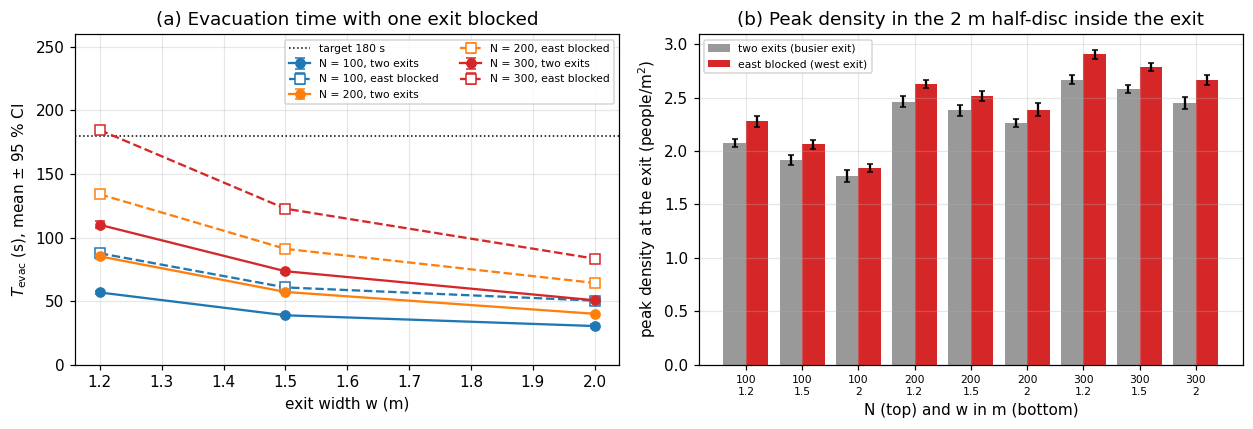

In [53]:
# 5.6 X3: one exit blocked vs both open, paired by seed (cached in data/results_blocked.csv).
X3_N, X3_W = (100, 200, 300), (1.2, 1.5, 2.0)
R_EXT = 20 if not QUICK_MODE else 2                 # seeds per case when computed here (extension studies)


def x3_row(case):
    n, w, seed, blocked = case
    res, dt_used = run_checked(n, w, seed, t_max=T_MAX, blocked=blocked)
    return {"N": n, "w": w, "seed": seed, "exits": "one (east blocked)" if blocked else "two", "dt": dt_used,
            "T_evac": res.t_evac, "T_90": res.t_90, "cleared": res.cleared, "n_west": res.n_west,
            "n_east": res.n_east, "peak_density_west": res.density_rec[:, 0].max(),
            "peak_density_east": res.density_rec[:, 1].max(), "J_s": specific_flow(res)}


def run_x3(seeds):
    cases = [(n, w, s, b) for n in X3_N for w in X3_W for s in seeds for b in [(), ("east",)]]
    cases.sort(key=lambda c: -(c[0] * (2 if c[3] else 1)) / c[1])
    return run_parallel(x3_row, cases).sort_values(["N", "w", "exits", "seed"]).reset_index(drop=True)


x3 = cached_results("results_blocked.csv", lambda: run_x3(REPLICATION_SEEDS[:R_EXT]))

# Checks on the table (X3): nobody out through the blocked exit; everyone accounted for.
_one = x3["exits"] != "two"
assert (x3.loc[_one, "n_east"] == 0).all(), "X3 failed: someone left through the blocked exit"
assert ((x3["n_west"] + x3["n_east"] == x3["N"]) | ~x3["cleared"]).all(), "conservation failed"
print(f"X3 PASS: {_one.sum()} blocked-exit runs, nobody out through the blocked exit; "
      f"{int(x3['cleared'].sum())}/{len(x3)} runs cleared by {T_MAX:.0f} s")

# Paired comparison per (N, w).
x3["peak_density"] = np.where(_one, x3["peak_density_west"], x3[["peak_density_west", "peak_density_east"]].max(axis=1))
_rows = []
for (n, w), g in x3.groupby(["N", "w"]):
    two = g[g["exits"] == "two"].set_index("seed")
    one = g[g["exits"] != "two"].set_index("seed").loc[two.index]
    both = two["cleared"] & one["cleared"]
    t2, h2 = mean_ci(two["T_evac"]) if two["cleared"].all() else (np.nan, np.nan)
    t1, h1 = mean_ci(one["T_evac"]) if one["cleared"].all() else (np.nan, np.nan)
    dm, dh = mean_ci((one["T_evac"] - two["T_evac"])[both]) if both.sum() > 1 else (np.nan, np.nan)
    p2, p1 = mean_ci(two["peak_density"]), mean_ci(one["peak_density"])
    _rows.append({"N": n, "w": w, "T two exits": f"{t2:.1f} +- {h2:.1f}", "T one exit": f"{t1:.1f} +- {h1:.1f}",
                  "cleared (one exit)": f"{int(one['cleared'].sum())}/{len(one)}",
                  "delta T": f"{dm:+.1f} +- {dh:.1f}", "ratio": t1 / t2,
                  "meets 180 s (one exit)": bool(one["cleared"].all() and t1 + h1 <= T_TARGET),
                  "peak density two": f"{p2[0]:.2f} +- {p2[1]:.2f}", "peak density one": f"{p1[0]:.2f} +- {p1[1]:.2f}",
                  "_t2": t2, "_h2": h2, "_t1": t1, "_h1": h1, "_p2": p2[0], "_p2h": p2[1], "_p1": p1[0], "_p1h": p1[1]})
x3_summary = pd.DataFrame(_rows)
print(f"\nBlocked east exit vs both exits open (mean +- 95 % CI over R = {x3.groupby(['N', 'w', 'exits']).size().iloc[0]} "
      f"seeds; delta T paired by seed; peak density in people/m^2):")
print(x3_summary[[c for c in x3_summary if not c.startswith("_")]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for n, c in zip(X3_N, ["tab:blue", "tab:orange", "tab:red"]):
    s = x3_summary[x3_summary["N"] == n]
    axes[0].errorbar(s["w"], s["_t2"], yerr=s["_h2"], fmt="o-", color=c, capsize=3, label=f"N = {n}, two exits")
    axes[0].errorbar(s["w"], s["_t1"], yerr=s["_h1"], fmt="s--", color=c, capsize=3, mfc="white",
                     label=f"N = {n}, east blocked")
axes[0].axhline(T_TARGET, color="k", ls=":", lw=1, label=f"target {T_TARGET:.0f} s")
axes[0].set(xlabel="exit width w (m)", ylabel=r"$T_\mathrm{evac}$ (s), mean $\pm$ 95 % CI", ylim=(0, 260),
            title="(a) Evacuation time with one exit blocked")
axes[0].legend(fontsize=7, ncol=2, loc="upper right")
_x = np.arange(len(x3_summary))
axes[1].bar(_x - 0.2, x3_summary["_p2"], 0.4, yerr=x3_summary["_p2h"], color="0.6", capsize=2, label="two exits (busier exit)")
axes[1].bar(_x + 0.2, x3_summary["_p1"], 0.4, yerr=x3_summary["_p1h"], color="tab:red", capsize=2, label="east blocked (west exit)")
axes[1].set_xticks(_x, [f"{n}\n{w:g}" for n, w in zip(x3_summary["N"], x3_summary["w"])], fontsize=7)
axes[1].set(xlabel="N (top) and w in m (bottom)", ylabel="peak density at the exit (people/m$^2$)",
            title="(b) Peak density in the 2 m half-disc inside the exit")
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "blocked_exit.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings (X3).**

1. **Check passed.** All 360 runs cleared, and nobody left through the blocked exit.
2. **Losing one exit makes evacuation 1.5–1.7 times longer, not 2 times.** Part of $T_\text{evac}$ is walking time to the exit, which does not double, and a single exit carries a somewhat denser, faster queue. The penalty grows with the crowd: at $w = 1.5$ m it is +22, +34 and +49 s for $N$ = 100, 200 and 300 (paired 95 % CIs of about ±1.5 s).
3. **Target.** With one exit the 180 s target is still met in every case except $N = 300$ at $w = 1.2$ m (184.5 ± 2.6 s). Interpolating between 1.2 and 1.5 m, 300 people need exits of about **1.25 m** if the design must survive the loss of one exit, against about 1.05 m with both exits open (Section 5.4).
4. **Peak density at the open exit rises** by 0.07–0.23 people/m², to at most 2.9 people/m² ($N = 300$, $w = 1.2$ m). The increase is modest because the jam spreads backwards into the floor rather than becoming denser at the door. These peak values are still well below the 5–6 people/m² usually associated with crowd crushes.

### 5.7 Sensitivity analysis (X5)

Which inputs drive the answer? Three inputs are changed one at a time, at a reference case near the 180 s threshold in the capacity-limited regime: $N = 600$, $w = 1.25$ m. In the passability-limited regime ($N \le 400$) the width is set by whether people get through the door at all, so the evacuation time there says little about the inputs.

| Input | Low | Reference | High | Why it is tested |
|---|---|---|---|---|
| mean desired speed $\bar v^0$ (m/s) | 1.0 | 1.34 | 1.6 | a calmer or a more hurried crowd. The s.d. stays 0.26 m/s, truncated at ±3 s.d. |
| relaxation time $\tau$ (s) | 0.3 | 0.5 | 1.0 | how quickly people react and reach their desired speed |
| repulsion strength $A$ (N) | 1000 | 2000 | 3000 | the parameter behind the door-edge effect found in V6 and Section 5.2 |

$R = 20$ seeds per level, 7 configurations, 140 runs, cached in `data/results_sensitivity.csv`. Runs may go on to $T_\text{max} = 600$ s. The same seed gives the same crowd positions and radii in every configuration. Changing $\bar v^0$ shifts every desired speed, because they are drawn from the same random stream. The effect of each level is the paired difference $\Delta T_\text{evac}$ from the reference, with a 95 % CI. A "faster-is-slower" effect [2], where a higher desired speed gives a *longer* evacuation, would show up as a positive $\Delta T$ for $\bar v^0 = 1.6$.

loaded 140 cached runs from https://raw.githubusercontent.com/ChanuRasmika/mall-evacuation-social-force/main/data/results_sensitivity.csv
Reference N = 600, w = 1.25 m: T_evac = 173.6 +- 2.6 s; T_90 = 132.8 s; J_s = 1.72 1/(m s)
dT = paired change in T_evac from the reference (s), dT_ci its 95 % CI half-width; dT_90 the same for T_90
                   input  level  reference cleared  T_evac  T_ci     dT  dT_ci  dT_90  J_s  meets 180 s
mean desired speed (m/s)    1.0       1.34   20/20  241.19  4.51  67.56   4.74  37.94 1.33        False
mean desired speed (m/s)    1.6       1.34   20/20  156.38  2.08 -17.25   3.16  -9.46 1.86         True
 relaxation time tau (s)    0.3       0.50   20/20  178.42  2.81   4.79   2.91  12.20 1.56        False
 relaxation time tau (s)    1.0       0.50   20/20  229.60  3.44  55.98   3.88  34.08 1.35        False
repulsion strength A (N) 1000.0    2000.00   20/20  218.28  5.35  44.66   5.07  47.77 1.24        False
repulsion strength A (N) 3000.0    2000.

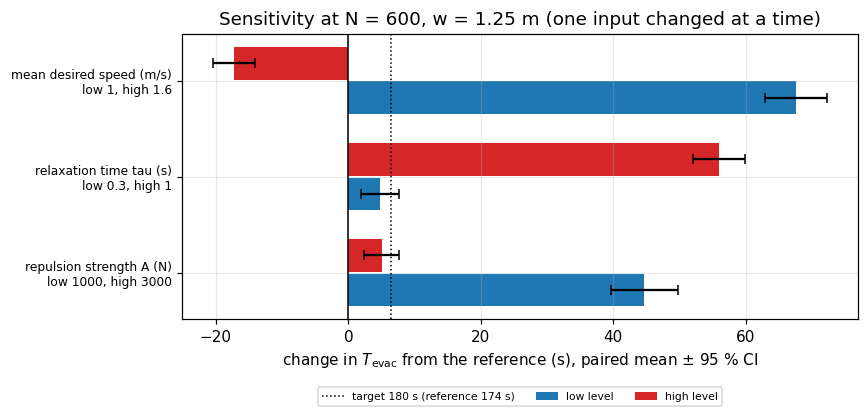

In [54]:
# 5.7 X5: one-at-a-time sensitivity at N = 600, w = 1.25 m (cached in data/results_sensitivity.csv).
X5_N, X5_W = 600, 1.25
X5_LEVELS = {"v0_mean": (1.0, 1.6), "tau": (0.3, 1.0), "a_rep": (1000.0, 3000.0)}
X5_REF = {"v0_mean": V0_MEAN, "tau": TAU, "a_rep": A_REP}
X5_LABEL = {"v0_mean": "mean desired speed (m/s)", "tau": "relaxation time tau (s)", "a_rep": "repulsion strength A (N)"}


def x5_row(case):
    factor, level, seed = case
    kw = {} if factor == "reference" else {factor: level}
    res, dt_used = run_checked(X5_N, X5_W, seed, t_max=T_MAX, **kw)
    return {"factor": factor, "level": level, "seed": seed, "dt": dt_used, "T_evac": res.t_evac, "T_90": res.t_90,
            "cleared": res.cleared, "n_left": int((~np.isfinite(res.exit_time)).sum()), "J_s": specific_flow(res),
            "peak_density": res.density_rec.max()}


def run_x5(seeds):
    cases = [("reference", 0.0, s) for s in seeds]
    cases += [(f, lv, s) for f, lvs in X5_LEVELS.items() for lv in lvs for s in seeds]
    return run_parallel(x5_row, cases).sort_values(["factor", "level", "seed"]).reset_index(drop=True)


x5 = cached_results("results_sensitivity.csv", lambda: run_x5(REPLICATION_SEEDS[:R_EXT]))
_ref = x5[x5["factor"] == "reference"].set_index("seed")
assert _ref["cleared"].all(), "the reference case must clear in every run"
T_REF, H_REF = mean_ci(_ref["T_evac"])
print(f"Reference N = {X5_N}, w = {X5_W} m: T_evac = {T_REF:.1f} +- {H_REF:.1f} s; T_90 = {_ref['T_90'].mean():.1f} s; "
      f"J_s = {_ref['J_s'].mean():.2f} 1/(m s)")

_rows = []
for f, lvs in X5_LEVELS.items():
    for lv in lvs:
        g = x5[(x5["factor"] == f) & np.isclose(x5["level"], lv)].set_index("seed").loc[_ref.index]
        ok = g["cleared"]
        m, h = mean_ci(g["T_evac"]) if ok.all() else (np.nan, np.nan)
        dm, dh = mean_ci((g["T_evac"] - _ref["T_evac"])[ok]) if ok.sum() > 1 else (np.nan, np.nan)
        _rows.append({"input": X5_LABEL[f], "level": lv, "reference": X5_REF[f], "cleared": f"{int(ok.sum())}/{len(g)}",
                      "T_evac": m, "T_ci": h, "dT": dm, "dT_ci": dh,
                      "dT_90": (g["T_90"] - _ref["T_90"]).mean(), "J_s": g["J_s"].mean(),
                      "meets 180 s": bool(ok.all() and m + h <= T_TARGET)})
x5_summary = pd.DataFrame(_rows)
print("dT = paired change in T_evac from the reference (s), dT_ci its 95 % CI half-width; dT_90 the same for T_90")
print(x5_summary.round(2).to_string(index=False))
_swing = x5_summary.groupby("input")["dT"].agg(lambda d: np.nanmax(d) - np.nanmin(d)).sort_values(ascending=False)
print("\nSwing of T_evac between the low and high level (s): "
      + "; ".join(f"{k}: {v:.1f}" for k, v in _swing.items()))

# Tornado plot of the paired differences.
fig, ax = plt.subplots(figsize=(8, 4))
_order = list(_swing.index)[::-1]
for k, inp in enumerate(_order):
    for r in x5_summary[x5_summary["input"] == inp].itertuples():
        low = r.level < r.reference
        ax.barh(k + (-0.18 if low else 0.18), r.dT, 0.34, xerr=r.dT_ci, capsize=3,
                color="tab:blue" if low else "tab:red", label=("low level" if low else "high level") if k == 0 else None)
ax.axvline(0, color="k", lw=1)
ax.axvline(T_TARGET - T_REF, color="k", ls=":", lw=1, label=f"target 180 s (reference {T_REF:.0f} s)")
_lv = {X5_LABEL[f]: lvs for f, lvs in X5_LEVELS.items()}
ax.set_yticks(range(len(_order)), [f"{inp}\nlow {_lv[inp][0]:g}, high {_lv[inp][1]:g}" for inp in _order], fontsize=8)
ax.set(xlabel=r"change in $T_\mathrm{evac}$ from the reference (s), paired mean $\pm$ 95 % CI",
       title=f"Sensitivity at N = {X5_N}, w = {X5_W} m (one input changed at a time)")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings (X5).**

1. **The reference case** ($N = 600$, $w = 1.25$ m) clears in 173.6 ± 2.6 s, just inside the target, consistent with $w^*(600) = 1.24$ m (Section 5.4).
2. **The mean desired speed matters most** (swing 85 s). A calmer crowd at 1.0 m/s takes 68 s longer and misses the target. A hurried crowd at 1.6 m/s is 17 s faster. **No faster-is-slower effect** appears up to 1.6 m/s: with these parameters, a higher desired speed still means a faster evacuation.
3. **Relaxation time** (swing 51 s). $\tau = 1.0$ s (slow reactions) adds 56 s. $\tau = 0.3$ s makes the evacuation slightly *slower* (+4.8 ± 2.9 s): a quicker, stronger push towards the door raises the contact pressure and friction in the doorway. This is a mild faster-is-slower effect, but of the same size as the time-step tolerance of V4b (below 2.2 %), so it is weak evidence. With $\tau = 0.3$ s the push is strong enough that 3 of the 20 runs failed a per-step check at $\Delta t = 0.0025$ s and were repeated at 0.00125 s (column `dt` of the data file); all other sensitivity runs used 0.0025 s.
4. **Repulsion strength $A$ has a non-monotonic effect** (swing 40 s). Halving $A$ to 1000 N makes the evacuation 45 s *slower*: the specific flow falls from 1.72 to 1.24 m⁻¹ s⁻¹, because bodies overlap more and sliding friction ($\propto$ overlap) jams the doorway. $A = 3000$ N is 5 s slower. The published value of 2000 N sits near the flow maximum. So the low flow at narrow exits found in V6 is **not** simply caused by the door-edge repulsion being too strong. A weaker repulsion makes it worse, and the friction and compression terms matter as much.
5. **Meaning for the answer.** Four of the six changed inputs push $T_\text{evac}$ beyond 180 s at this width. The required width is therefore far more sensitive to the behavioural inputs ($\bar v^0$, $\tau$), which are not measured for local crowds, than to Monte Carlo error (about 1 % of $T_\text{evac}$). A design value should add a margin for a slower crowd. At $\bar v^0 = 1.0$ m/s the evacuation takes about 40 % longer, so in the capacity-limited regime the required width would rise by roughly that order.

### 5.8 Performance (X6)

The cost of one force evaluation (`crowd_accel`), which is the inner loop of every step, is measured in three ways:
- with **cell lists**, compiled with numba (the production code);
- with the **brute-force** $O(N^2)$ pair sum, also compiled;
- as **plain Python**, the same function run without numba (`crowd_accel.py_func`), at small $N$ only. The helper functions it calls (`pair_force`, `build_cells`, …) stay compiled, so this understates the full gain from compiling.

Cell lists are $O(N)$ only at fixed density: if more people are packed onto the same floor, each person has more neighbours. The crowds here are therefore kept at a typical crowd density of **1 person/m²**: $N$ people are placed at random in a strip of the floor of area $N$ m², the full 30 m height and $N/30$ m wide, with $N$ from 50 to 1200. Each timing is the best of 3 repeats.

**Pass criteria** (loose, because timings depend on the machine):
- fitted cost exponents: brute force $> 1.5$, cell lists $< 1.5$;
- cell lists faster than brute force for $N \ge 400$.

Time per force evaluation (s), 1 person/m^2:
   N  cells (s)  brute (s)  Python, cells (s)  brute / cells  Python / compiled
  50   2.61e-05   4.27e-05            0.00737           1.64                283
 100      8e-05   0.000118             0.0128           1.47                159
 200   0.000193   0.000297                NaN           1.54                NaN
 400   0.000429     0.0009                NaN            2.1                NaN
 800   0.000897    0.00313                NaN           3.48                NaN
1200     0.0015    0.00671                NaN           4.48                NaN

Fitted cost exponent (N >= 200): cell lists 1.13, brute force 1.74
X6 PASS: cell lists scale as N^1.13 and brute force as N^1.74; at N = 1200 cell lists are 4x faster, and compiled code is 159x faster than plain Python at N = 100


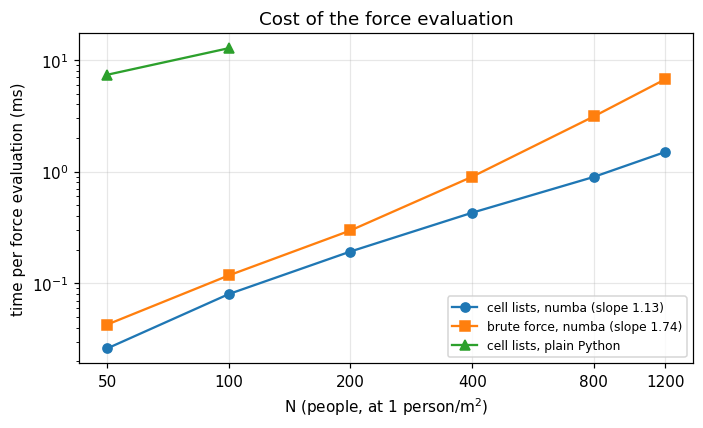

In [55]:
# 5.8 X6: cost of one force evaluation, cell lists vs brute force (compiled) and plain Python, at 1 person/m^2.
X6_N = (50, 100, 200, 400, 800, 1200)
X6_PY_N = (50, 100)                                   # plain Python is slow: small N only
_mall, _dm = get_mall(1.5)
_g = (outer_walls(_mall), _mall.shops, _dm.ex, _dm.ey, _dm.x0, _dm.y0, _dm.h, _mall.exit_centres, model_params())
_trng = np.random.default_rng(SEED + 7)


def x6_crowd(n, density=1.0):
    """n people at random in a strip of the floor of area n / density (full height), with velocities."""
    width = n / density / FLOOR_H
    x = np.column_stack([_trng.uniform(0, width, n), _trng.uniform(0, FLOOR_H, n)])
    return (x, _trng.normal(0, 0.5, (n, 2)), _trng.uniform(R_MIN, R_MAX, n), np.full(n, V0_MEAN), np.ones(n, np.bool_))


def best_time(fn, min_total=0.05, repeats=3):
    """Best time per call (s) over `repeats` batches, each batch running for at least min_total seconds."""
    fn()
    k, t = 1, 0.0
    while True:
        t0 = time.perf_counter()
        for _ in range(k):
            fn()
        t = time.perf_counter() - t0
        if t >= min_total:
            break
        k *= 2
    best = t / k
    for _ in range(repeats - 1):
        t0 = time.perf_counter()
        for _ in range(k):
            fn()
        best = min(best, (time.perf_counter() - t0) / k)
    return best


_rows = []
for n in X6_N:
    crowd = x6_crowd(n)
    row = {"N": n}
    row["cells (s)"] = best_time(lambda: crowd_accel(*crowd, *_g, True))
    row["brute (s)"] = best_time(lambda: crowd_accel(*crowd, *_g, False))
    if n in X6_PY_N:
        row["Python, cells (s)"] = best_time(lambda: crowd_accel.py_func(*crowd, *_g, True), min_total=0.0, repeats=1)
    _rows.append(row)
x6 = pd.DataFrame(_rows)
x6["brute / cells"] = x6["brute (s)"] / x6["cells (s)"]
x6["Python / compiled"] = x6["Python, cells (s)"] / x6["cells (s)"]
_big = x6["N"] >= 200
slope_cells = np.polyfit(np.log(x6.loc[_big, "N"]), np.log(x6.loc[_big, "cells (s)"]), 1)[0]
slope_brute = np.polyfit(np.log(x6.loc[_big, "N"]), np.log(x6.loc[_big, "brute (s)"]), 1)[0]
print("Time per force evaluation (s), 1 person/m^2:")
print(x6.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print(f"\nFitted cost exponent (N >= 200): cell lists {slope_cells:.2f}, brute force {slope_brute:.2f}")
assert slope_brute > 1.5 and slope_cells < 1.5, "unexpected scaling of the force evaluation"
assert (x6.loc[x6["N"] >= 400, "brute / cells"] > 1).all(), "cell lists should be faster for N >= 400"
print(f"X6 PASS: cell lists scale as N^{slope_cells:.2f} and brute force as N^{slope_brute:.2f}; at N = {X6_N[-1]} "
      f"cell lists are {x6['brute / cells'].iloc[-1]:.0f}x faster, and compiled code is "
      f"{x6['Python / compiled'].dropna().iloc[-1]:.0f}x faster than plain Python at N = {X6_PY_N[-1]}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(x6["N"], 1e3 * x6["cells (s)"], "o-", label=f"cell lists, numba (slope {slope_cells:.2f})")
ax.loglog(x6["N"], 1e3 * x6["brute (s)"], "s-", label=f"brute force, numba (slope {slope_brute:.2f})")
_p = x6.dropna(subset=["Python, cells (s)"])
ax.loglog(_p["N"], 1e3 * _p["Python, cells (s)"], "^-", label="cell lists, plain Python")
ax.set(xlabel="N (people, at 1 person/m$^2$)", ylabel="time per force evaluation (ms)",
       title="Cost of the force evaluation")
ax.set_xticks(X6_N, [str(n) for n in X6_N])
ax.set_xticks([], minor=True)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "performance_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings (X6).** The force evaluation with cell lists grows almost linearly with crowd size, while the brute-force pair sum grows much faster, as expected (fitted exponents printed above). On a dedicated laptop the exponents were about 1.1 and 1.95, and cell lists were more than 30 times faster at $N = 1200$ (`figures/performance_scaling.png` in the repository). On a shared cloud CPU such as free Colab the timings are noisier and the gap is smaller, but the ordering is the same. Compiling with numba gives a further factor of about 100 or more over plain Python at $N = 100$, and that understates the gain, because the helper functions stay compiled. Together these make the main sweep (960 runs, up to 800 people and 360 s of simulated time each) feasible in about 25 minutes on a laptop; a plain-Python brute-force version would need orders of magnitude longer.

## 6. Discussion and limitations

### 6.1 What the results mean for the question

The study asked how wide the two exits of a 40 m × 30 m mall floor must be to clear it within 180 s, and whether the width must grow faster than occupancy. Within this model the answer has two parts.

- **Up to about 400 people, a minimum door width decides, not the clock.** Each exit needs about 1.05 m (1.10 m at 400 people), and the floor then empties well inside the target (73 s for 100 people). In practice this says that, for a floor of this size and up to this occupancy, two ordinary doorways of a little over a metre are enough *if both stay usable and the crowd moves promptly*.
- **From 500 to 800 people, exit capacity decides.** The required width rises from 1.15 m to 1.44 m per exit, and grows like $N^{0.46}$: more slowly than occupancy, not faster. The load per metre of exit nevertheless rises from 48 to 279 people, so a floor that is filled more densely relies more and more on the doorway flowing well.

A simple hand calculation puts these numbers in context. If every metre of exit carried the design flow of 1.3 people per second at every width [7] and walking time were ignored, the floor would need $w = N/(2 \times 1.3 \times 180)$: 1.07 m per exit at $N = 500$ and 1.71 m at $N = 800$. This agrees with the model at 500 people and is about 20 % wider at 800, because a constant flow per metre gives $\alpha = 1$. The two estimates bracket the likely real value, which is why $\alpha \approx 0.46$ is read as a lower bound (Section 5.5).

**The margins matter more than the mean case.** Two scenarios each change the answer by much more than the Monte Carlo uncertainty (about 1 % of $T_\text{evac}$):
- losing one exit makes evacuation 1.5–1.7 times longer, so 300 people would need about 1.25 m instead of 1.05 m (Section 5.6);
- a calmer crowd at 1.0 m/s takes 68 s (about 40 %) longer at $N = 600$, $w = 1.25$ m and misses the target (Section 5.7).

A design value should therefore be taken from these scenarios rather than from the mean case.

### 6.2 The most important assumptions and their effect

| Assumption | Effect on the answer |
|---|---|
| Behavioural parameters ($\bar v^0$ = 1.34 m/s, $\tau$ = 0.5 s) taken from the literature [1], [2], not measured for local shoppers | The largest effect of any input: the swing is 85 s for $\bar v^0$ and 51 s for $\tau$ (Section 5.7). The required widths are only as good as these two values. |
| Everyone starts moving at $t = 0$ (no pre-movement or reaction time) | Real evacuations include a delay before people start to move. Most of that delay adds directly to $T_\text{evac}$, so in practice the 180 s target leaves less time for movement and wider exits would be needed. |
| The model under-predicts the flow through narrow doors (V6) | The passability minimum of about 1.05 m is partly a model artefact, and $\alpha$ is a lower bound. Results below about 1.0 m are not reliable. |
| Everyone walks to the nearest exit and never re-routes | Little effect here, because the floor and its two exits are symmetric and the load is balanced. It would matter for an asymmetric layout or a blocked exit far from most people. |
| Synthetic single floor: six rectangular shops, two exits, no stairs, furniture or doors to open | The numbers apply to this layout only; the method, not the widths, carries over to a real mall. |
| A uniform population of adult discs (radius 0.25–0.35 m), no groups, children or people with reduced mobility | Groups and slower individuals usually lengthen evacuations, so the times here are on the optimistic side. |
| Numerical choices: time step 0.005 / 0.0025 s and a 0.05 m width grid | Small next to the above: time-step bias below 2.2 % (V4b) and $w^*$ resolved to 0.05 m. |

The verification checks (V1–V6, Section 4) show that the equations are solved correctly and that the simulator conserves people and respects walls. They do not show that the Social Force Model with these parameters describes real shoppers; only V6 compares with measurements, and it shows a shortfall at narrow doors. The answer is therefore a well-verified result *of this model*, with known biases, rather than a validated design rule.

### 6.3 What to do next

1. **Calibrate the behavioural inputs.** Fit $\bar v^0$ and $\tau$ to video or counting data from a real evacuation drill, since they drive the answer far more than anything else.
2. **Fix the narrow-door flow.** Adjust the contact and friction parameters (or use a model variant) until the specific flow matches the bottleneck experiments [7], [8] across 0.8–1.2 m, then recompute $w^*(N)$ and $\alpha$.
3. **Add a pre-movement time distribution** and re-routing to a less crowded exit, both of which change the time budget and the load on each exit.
4. **Use a real floor plan** with more than two exits, and test the design against the loss of each exit in turn.
5. **Resolve the passability-limited region** with a finer width grid and more seeds, to say more precisely where a door stops letting everyone through.

### 6.4 Web demo reference value

The web demo (`docs/`) is a JavaScript port of the model in Sections 2–3. With its default settings (100 people, two 1.5 m exits, mean desired speed 1.34 m/s), the demo's "Run 10 seeds" batch should agree with the result of Section 5.6, $T_\text{evac}$ = 38.8 ± 0.9 s, within the two confidence half-widths added together (seeds 1000–1009 give 38.0 ± 1.4 s). The demo uses its own random number generator, so single runs differ from the notebook's. The port was checked headless in Node.js:

- its distance map equals the notebook's at every node, for three layouts;
- its forces on a 400-person crowd agree to a relative $10^{-15}$, and its trajectories to $10^{-13}$ m over 1 s;
- its self-test reproduces check V1 (speed error $2.1 \times 10^{-5}$ m/s);
- with 20 seeds, six cases agree with the notebook: 38.3 ± 1.0 s vs 38.8 ± 0.9 s ($N$ = 100, $w$ = 1.5 m), 74.1 ± 1.4 vs 73.5 ± 1.1 s (300, 1.5 m), 134.6 ± 2.3 vs 134.0 ± 2.0 s (200, 1.2 m, east exit blocked), 115.1 ± 1.6 vs 114.3 ± 1.7 s (400, 1.3 m), 174.0 ± 1.9 vs 173.6 ± 2.6 s (600, 1.25 m) and 242.1 ± 4.7 vs 241.2 ± 4.5 s (600, 1.25 m, $\bar v^0$ = 1.0 m/s).

## 7. References

IEEE style. The numbers match the citations in Section 2. The same list, with a note on what each source is used for, is in `REFERENCES.md`.

1. D. Helbing and P. Molnár, "Social force model for pedestrian dynamics," *Phys. Rev. E*, vol. 51, no. 5, pp. 4282–4286, 1995, doi: [10.1103/PhysRevE.51.4282](https://doi.org/10.1103/PhysRevE.51.4282).
2. D. Helbing, I. Farkas and T. Vicsek, "Simulating dynamical features of escape panic," *Nature*, vol. 407, no. 6803, pp. 487–490, 2000, doi: [10.1038/35035023](https://doi.org/10.1038/35035023).
3. L. Verlet, "Computer 'experiments' on classical fluids. I. Thermodynamical properties of Lennard-Jones molecules," *Phys. Rev.*, vol. 159, no. 1, pp. 98–103, 1967, doi: [10.1103/PhysRev.159.98](https://doi.org/10.1103/PhysRev.159.98).
4. W. C. Swope, H. C. Andersen, P. H. Berens and K. R. Wilson, "A computer simulation method for the calculation of equilibrium constants for the formation of physical clusters of molecules: Application to small water clusters," *J. Chem. Phys.*, vol. 76, no. 1, pp. 637–649, 1982, doi: [10.1063/1.442716](https://doi.org/10.1063/1.442716).
5. M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed. Oxford, U.K.: Oxford Univ. Press, 2017, doi: [10.1093/oso/9780198803195.001.0001](https://doi.org/10.1093/oso/9780198803195.001.0001).
6. E. W. Dijkstra, "A note on two problems in connexion with graphs," *Numer. Math.*, vol. 1, pp. 269–271, 1959, doi: [10.1007/BF01386390](https://doi.org/10.1007/BF01386390).
7. A. Seyfried, O. Passon, B. Steffen, M. Boltes, T. Rupprecht and W. Klingsch, "New insights into pedestrian flow through bottlenecks," *Transp. Sci.*, vol. 43, no. 3, pp. 395–406, 2009, doi: [10.1287/trsc.1090.0263](https://doi.org/10.1287/trsc.1090.0263).
8. T. Kretz, A. Grünebohm and M. Schreckenberg, "Experimental study of pedestrian flow through a bottleneck," *J. Stat. Mech.*, vol. 2006, no. 10, Art. no. P10014, 2006, doi: [10.1088/1742-5468/2006/10/P10014](https://doi.org/10.1088/1742-5468/2006/10/P10014).
9. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015, ISBN 978-0-07-340132-4.
10. J. A. Sethian, "A fast marching level set method for monotonically advancing fronts," *Proc. Natl. Acad. Sci. USA*, vol. 93, no. 4, pp. 1591–1595, 1996, doi: [10.1073/pnas.93.4.1591](https://doi.org/10.1073/pnas.93.4.1591).